# Can a language model write, check and repair the programs that watch 20 news pages?

## Keeping track of what other organisations announce

Every organisation depends on other organisations that publish news on their websites. A finance team needs to know when the central bank changes its interest rate, when the tax authority moves a filing deadline, when the largest customer changes how quickly it pays its suppliers, or when the packaging supplier announces a surcharge. Each of these arrives as a short news release on someone else's website, and each can change a forecast, a payment date or a decision about borrowing.

Nobody sends these releases to the team. Someone has to go and look. In many teams that job falls to a junior analyst or an intern, who opens each website once a week, scans the news page for anything new and copies the useful details into a spreadsheet: the headline, the date, who wrote it and the text itself. With 20 websites that is an hour or two every week; with 100 it is most of a day. The work is repetitive, it is the first thing skipped in a busy week, and the release that matters is easy to miss.

Everything in this notebook is fictional. The company, the 20 organisations it watches, their staff, their websites and every release were made up for the experiment, and the websites use the reserved `.example` internet domain.

### An illustrative example

Picture one website: the news page of a national tax authority. On Monday morning the analyst opens it and sees a list of releases, newest first, each with a date and a headline. The top item, dated last Thursday, was not there a week ago. The analyst opens it and copies four things into the tracker: the headline ("Sales tax filing deadline moves to 15 November"), the date, the author if one is named, and the three paragraphs of text. That is the ordinary case. It takes a few minutes and the result is right.

Now add one complication. The release page shows two dates: "Published 5 October" and, underneath, "Last updated 9 October". The tracker needs the publication date, because the team sorts announcements by when they were first made; a deadline change recorded as 9 October would look four days newer than it is, and could be missed by anyone filtering for "announced last week". A careful person reads both labels and takes the first. A person in a hurry, or a program written without that page in mind, may take whichever date it meets first.

### Turning the routine into a program

The usual way to save the hour is a small program for each website. It opens the news page, follows each link to a release and picks out the four facts. Programmers call such a program a scraper. One scraper is quick to write. Twenty are tedious, because every website is built differently: one lists releases in a table, another loads them from a separate data feed after the page opens, a third keeps the author's name only in hidden page information that a reader never sees. And a scraper that works today can stop working when the site is redesigned. Sometimes it fails loudly and finds nothing. Sometimes it fails silently and keeps returning a date, only now the wrong one.

### Two ways to use a language model

A language model can take over this work in two different ways.

The first is to let the model do the analyst's job directly. Every week, each new release page goes to the model, which returns the headline, date, author and text. No program is needed, but the model reads every page every week, so the cost grows with the number of releases, and every reading is a new chance for a mistake.

The second is to have the model write the scraper. The model sees the news page and one example release and writes a small program; the program then runs every week without the model, at almost no cost. The model is called again only when something goes wrong. If the program crashes, or its output fails a check, the error message and the failed checks go back to the model, which writes a corrected version.

That second approach stands or falls with checks that work without knowing the right answer, because in real use nobody has an answer key. This notebook tests two kinds. Automatic rules are free to run and look for output that is clearly wrong: a missing date, a date in the future, a headline that does not appear on the page, leftover web-page code in the text, or a week in which the author comes back empty for every release although last week it was always there. A review by a second, stronger model costs money: it reads a sample of the program's output next to the page it came from and says whether the headline, date, author and text match what the page shows.

## The question

Can a language model write a working extraction program for each of 20 differently built news pages from one example page, find and fix its own mistakes using only checks that do not know the right answer, and keep the programs working for four weeks in which six of the sites are redesigned? Which checks does that need: the free automatic rules alone, or the rules plus a review by a stronger model? And how do accuracy and cost compare with simply having a model read every release page?

## Study summary

**What was compared.** Three writer models, Claude Haiku 5.5, Claude Sonnet 5.5 and the small open-weight Granite 4.2 8B, each wrote one program per source for the news pages of 20 fictional organisations, with up to three repair rounds whenever a check failed. Each writer ran twice: once with automatic rules as the only check, once with the rules followed by a Claude Opus 5.5 review of two sampled records. The programs then ran for three more weeks, 593 release-weeks in all (one release on one week's listing). The same three models also read each of the 240 releases directly, as the comparison. A separate test planted 135 typical errors into correct output to see which check notices them.

**What we found.**

- The two Claude writers rarely needed the loop. Sonnet's first program was fully correct for 20 of 20 sources and Haiku's for 19 of 20; one repair fixed Haiku's last one. In week 3, four of the six redesigns broke both writers' programs; the automatic rules flagged every break, one repair fixed each, and every source delivered correct releases in every week.
- Granite 4.2 8B needed the loop all the time. Its first programs were fully correct for 4 of 20 sources, and for 9 of 20 after three repairs. With rules only, Granite's wrong output went unnoticed in 22 source-weeks; with the review, in 1. By week 4 the review condition had 16 of 20 sources right, against 10 with rules only.
- In the planted-error test the rules flagged 48 of 135 errors and the review flagged all 135, with no false alarm on 20 unchanged controls.
- With a Claude writer and rules only, four weeks of correct releases cost $0.28 (Haiku) or $1.76 (Sonnet) in model calls. The weekly review added about $5 and caught no error that the rules had missed. Reading every page cost $4.25 with Sonnet (every release right) and $0.23 with Haiku (94.4% right).

In the original situation: a team can let a capable model write its scrapers, run them every week for almost nothing, and rely on free automatic rules to notice when a redesign breaks one. A review by a stronger model pays for itself when the writer is weak or a program is new, not as a weekly routine for programs that already work.

**The main caveat.** The 20 sites are made up, small and tidy, each with one designed trap, and the same person designed the traps, the field definitions and the rules. Real sites are larger and messier and will produce errors nobody anticipated, which is where the rules are weakest: they flagged 48 of the 135 planted errors.

## Contents

1. [Setup and configuration](#1-setup-and-configuration)
2. [The sources and their websites](#2-the-sources-and-their-websites)
3. [How a program is written, run and checked](#3-how-a-program-is-written-run-and-checked)
4. [Worked example: one source from first program to repair](#4-worked-example-one-source-from-first-program-to-repair)
5. [Results: writing the first programs](#5-results-writing-the-first-programs)
6. [Results: four weeks of reuse and six redesigns](#6-results-four-weeks-of-reuse-and-six-redesigns)
7. [Results: what each check can catch](#7-results-what-each-check-can-catch)
8. [Comparison with reading every page](#8-comparison-with-reading-every-page)
9. [Error analysis](#9-error-analysis)
10. [What the evidence supports](#10-what-the-evidence-supports)
11. [Limitations](#11-limitations)
12. [Spend, data and how to run](#12-spend-data-and-how-to-run)
13. [Future work and further reading](#13-future-work-and-further-reading)

### How the experiment runs

```mermaid
flowchart TD
    R["Source registry<br/>20 fictional organisations: news page and one sample release each"] --> S
    C["Release texts<br/>240 releases written by GPT-6.1 Sol (codex exec)"] --> S
    S["Site generator (code)<br/>20 page layouts, 6 redesigns<br/>80 snapshots = 20 sites x 4 weekly runs"] --> G
    G["Writer writes a program<br/>Claude Haiku 5.5 or Sonnet 5.5 (claude -p), Granite 4.2 8B (OpenRouter)<br/>in: news page + sample release; out: Python module"] --> X
    X["Sandbox runs the program on this week's snapshot<br/>out: records, error, request log<br/>690 program runs in all"] --> K
    K{"Checks without the answer key<br/>automatic rules; in one condition also an Opus 5.5 review<br/>239 reviews"}
    K -->|pass| O["Records go to the tracker<br/>program kept for next week"]
    K -->|fail| P["Report: error, requests, failed checks"]
    P --> F["Writer repairs the program (rounds 1 and 2)<br/>or rewrites it from scratch (round 3)<br/>210 repairs and rewrites"]
    F --> X
    O --> N["Next week: same program, new snapshot<br/>weeks 2, 3 (six redesigns) and 4"]
    N --> X
    O -.-> E["Scoring against the ground truth<br/>593 release-weeks, 4 fields each"]
    T["Ground truth from the generator<br/>never shown to the loop"] -.-> E
    B["Comparison: the same three models read every release page<br/>240 releases x 3 models = 720 reads"] -.-> E
    Q["Planted-error test: 135 altered outputs + 20 controls<br/>judged by the rules and by the review"] -.-> E
```

One source travels through it like this. Harrow & Finch Bank is listed in the registry with its newsroom address and one sample release. The site generator builds its pages for each Monday, including the data service that fills the newsroom in. In week 1 Claude Haiku 5.5 reads the two raw pages and writes a program; the sandbox runs it on the week-1 snapshot; the rules notice that every date is empty; the report goes back to Haiku, whose second program passes. In week 2 the same program runs again without any model call. In week 3 the bank retires its data service, the program returns nothing, the rules flag it and one repair adapts the program to the new service. Separately, the scoring step compares every week's records with the generator's truth, and the same releases are read directly by each model for the comparison.

## 1. Setup and configuration

### The models and why each is here

| Role | Model | How it is called | Why |
|---|---|---|---|
| Writes and repairs programs; reads pages in the comparison | Claude Haiku 5.5 | `claude -p` | The smallest and cheapest current Claude model, the natural choice for a cost-conscious team |
| Writes and repairs programs; reads pages in the comparison | Claude Sonnet 5.5 | `claude -p` | The mid-sized Claude model, to see whether a stronger writer needs fewer repairs |
| Writes and repairs programs; reads pages in the comparison | Granite 4.2 8B | OpenRouter, pinned to DeepInfra at BF16 | A small open-weight model (8.8 billion parameters, Apache 2.0 licence, released August 2026) that a team could run on its own hardware; it shows what the loop does for a much weaker writer |
| Reviews sampled records against the page | Claude Opus 5.5 | `claude -p` | The strongest Claude model, a tier above every writer, so no model reviews its own work |
| Writes the fictional release texts | GPT-6.1 Sol | `codex exec` | A different company's model, so the tested models never read text of their own making |

Each writer is used in two conditions. In the first, only the automatic rules decide whether a program's output is accepted. In the second, output that passes the rules also goes to the Opus review. Everything else (the pages, the prompts, the number of repair rounds) is the same.

### Settings, caches and budget

The first cell holds every setting that changes what is run or what it costs. `WRITERS` names the writers, `CHECK_MODES` the two check conditions, `REVIEWER` the reviewing model and `MAX_REPAIRS` how often a failing program goes back to its writer in one week. `MAX_CLI_CALLS` and `MAX_NEW_USD` stop the notebook before it spends more than intended.

Every model reply is saved in `data/cache_cli.jsonl` (Claude and GPT) or `data/cache_openrouter.jsonl` (Granite), keyed by the full request, and every program run is saved in `data/program_runs.jsonl`, keyed by the program and the page snapshot. Without `NB_LIVE=1` a missing reply stops the notebook instead of calling a model, so a re-run costs nothing and reproduces every number.

The next cells wrap the command-line tools (`claude -p`, `codex exec`) and the OpenRouter interface. The command-line tools run with no tools enabled, in an empty folder, so a model sees only the text it is given.

In [1]:
import ast, hashlib, html, json, math, os, random, re, shutil, subprocess, sys, tempfile, textwrap, threading, time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import date, datetime, timedelta, timezone
from pathlib import Path
from urllib.parse import urljoin, urlsplit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
DATA, FIG = ROOT / 'data', ROOT / 'figures'
DATA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
LIVE = os.environ.get('NB_LIVE') == '1'  # explicit opt-in; without it a cache miss stops the notebook

# Size knobs. Every paid call is cached in data/, so a re-run with LIVE off costs nothing.
N_SOURCES = 20             # sources taken from the registry, in registry order
WRITERS = {                # label -> (how it is called, model); each writes and repairs its own extraction programs
    'Claude Haiku 5.5': ('claude', 'claude-haiku-5-5'),
    'Claude Sonnet 5.5': ('claude', 'claude-sonnet-5-5'),
    'Granite 4.2 8B': ('openrouter', 'ibm-granite/granite-4.2-8b'),   # small open-weight model
}
OPEN_WRITERS = {k: m for k, (how, m) in WRITERS.items() if how == 'openrouter'}
OPEN_TEMPERATURE = 0.2     # OpenRouter models only; the claude CLI uses its default
CHECK_MODES = ['static', 'static+review']   # which checks may send a program back for repair
REVIEWER = 'claude-opus-5-5'     # reviews sampled records against the page; never one of the writers
CONTENT_AUTHOR = 'gpt-6.1-sol'   # codex exec; writes the fictional release texts (a different vendor)
MAX_REPAIRS = 3            # repair rounds after the first program; the last one starts from scratch
N_REVIEW_SAMPLES = 2       # records the reviewer reads in full per check
BASELINE_READERS = WRITERS # the same models read every release page directly, for comparison
RUN_TIMEOUT_S = 120        # wall-clock limit for one run of a generated program, Python start-up included
MAX_CLI_CALLS = 1500       # hard stop for new claude/codex calls
MAX_NEW_USD = 60.0         # hard stop for new list-price spend, per service (claude -p, OpenRouter)
WORKERS = int(os.environ.get('NB_WORKERS', '6'))
PROTOCOL = 'nb31-v1'

CLAUDE_OPTIONS = ['-p', '--tools', '', '--safe-mode', '--no-session-persistence',
    '--output-format', 'json', '--max-budget-usd', '1.00']
EFFORT = {'write': 'medium', 'review': 'medium', 'read': 'low'}
CODEX_OPTIONS = ['exec', '--skip-git-repo-check', '--ephemeral', '--ignore-user-config',
    '--sandbox', 'read-only', '--disable', 'shell_tool', '--disable', 'unified_exec',
    '--disable', 'apps', '--disable', 'plugins', '--disable', 'multi_agent',
    '--disable', 'browser_use', '--disable', 'computer_use', '--disable', 'image_generation',
    '--disable', 'code_mode', '--disable', 'code_mode_host', '--disable', 'shell_snapshot',
    '-c', 'web_search="disabled"', '-c', 'model_reasoning_effort="medium"', '--json']

# One plot style for this notebook.
COLORS = {'blue': '#2468ac', 'orange': '#dc793a', 'green': '#3a9175', 'purple': '#8d63ad',
          'grey': '#9a9a9a', 'red': '#c0392b', 'light': '#d9d9d9', 'teal': '#5fa8b8'}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.alpha': 0.2, 'axes.axisbelow': True, 'axes.titlelocation': 'left',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'font.size': 9,
    'figure.facecolor': 'white'})
pd.set_option('display.max_colwidth', 120)

def canonical(x):
    return json.dumps(x, sort_keys=True, ensure_ascii=False, separators=(',', ':'))

def digest(x):
    return hashlib.sha256(canonical(x).encode('utf-8')).hexdigest()

def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=1) + '\n', encoding='utf-8')

def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def clip(text, n):
    return text if len(text) <= n else text[:n] + f'\n[... {len(text) - n:,} more characters cut]'

def wilson(k, n, z=1.96):
    """95% Wilson score interval for k successes out of n."""
    if not n:
        return (float('nan'), float('nan'))
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))

print('LIVE' if LIVE else 'Replay from cache', '| writers:', ', '.join(WRITERS), '| reviewer:', REVIEWER)

Replay from cache | writers: Claude Haiku 5.5, Claude Sonnet 5.5, Granite 4.2 8B | reviewer: claude-opus-5-5


In [2]:
CLI_CACHE_PATH = DATA / 'cache_cli.jsonl'
CLI_CACHE = {}
if CLI_CACHE_PATH.exists():
    for line in CLI_CACHE_PATH.read_text(encoding='utf-8').splitlines():
        row = json.loads(line)
        assert digest(row['request']) == row['key']
        CLI_CACHE.setdefault(row['key'], row)   # the first reply to a request is the one used
cli_lock = threading.Lock()
key_locks = defaultdict(threading.Lock)   # identical requests in flight at the same time share one call
cli_new = {'calls': 0, 'usd': 0.0}
USED_KEYS = set()   # cache rows this run touched, for the spend table at the end
cli_workdir = tempfile.TemporaryDirectory(prefix='nb31_cli_')  # empty folder: the models see no repository files

def cli_call(backend, model, prompt, purpose, effort='low'):
    """One claude -p or codex exec call with no tools, cached by the full request."""
    opts = CLAUDE_OPTIONS + ['--effort', effort] if backend == 'claude' else CODEX_OPTIONS
    request = {'protocol': PROTOCOL, 'backend': backend, 'model': model, 'options': opts, 'prompt': prompt}
    key = digest(request)
    with cli_lock:
        lock = key_locks[key]
    with lock:
        return _cli_call(backend, model, prompt, purpose, opts, request, key)

def _cli_call(backend, model, prompt, purpose, opts, request, key):
    with cli_lock:
        USED_KEYS.add(key)
        if key in CLI_CACHE:
            return CLI_CACHE[key]['response']
        if not LIVE:
            raise RuntimeError(f'Offline cache miss {key[:12]} ({backend} {model}, {purpose}); set NB_LIVE=1 to collect it.')
        if cli_new['calls'] >= MAX_CLI_CALLS or cli_new['usd'] >= MAX_NEW_USD:
            raise RuntimeError('CLI budget reached; raise MAX_CLI_CALLS or MAX_NEW_USD explicitly.')
        cli_new['calls'] += 1
    exe = shutil.which(backend)
    if not exe:
        raise RuntimeError(f'{backend} CLI not installed')
    cmd = [exe, *opts, '--model', model] if backend == 'claude' else [exe, *opts, '-m', model, '-']
    t0 = time.perf_counter()
    for attempt in range(3):
        try:
            proc = subprocess.run(cmd, input=prompt, text=True, encoding='utf-8', capture_output=True,
                                  timeout=900, cwd=cli_workdir.name)
            if backend == 'claude':
                obj = json.loads(proc.stdout)
                if obj.get('is_error') or proc.returncode:
                    raise RuntimeError(str(obj.get('result'))[:300])
                response = {'text': obj['result'], 'usage': obj.get('usage', {}),
                            'list_cost_usd': obj.get('total_cost_usd')}
            else:
                if proc.returncode:
                    raise RuntimeError(f'codex failed ({proc.returncode}): {proc.stderr[-300:]}')
                events = [json.loads(l) for l in proc.stdout.splitlines() if l.startswith('{')]
                items = [e['item'] for e in events if e.get('type') == 'item.completed']
                answers = [x['text'] for x in items if x.get('type') == 'agent_message']
                if not answers:
                    raise RuntimeError('No Codex final response: ' + proc.stderr[-300:])
                response = {'text': answers[-1], 'usage': next((e['usage'] for e in events
                            if e.get('type') == 'turn.completed'), {}), 'list_cost_usd': None}
            break
        except Exception:
            if attempt == 2:
                raise
            time.sleep(10 * (attempt + 1))
    response.update(latency_s=round(time.perf_counter() - t0, 2), collected_at=datetime.now(timezone.utc).isoformat())
    with cli_lock:
        cli_new['usd'] += response.get('list_cost_usd') or 0.0
        CLI_CACHE[key] = {'key': key, 'request': request, 'purpose': purpose, 'response': response}
        with CLI_CACHE_PATH.open('a', encoding='utf-8') as f:
            f.write(json.dumps(CLI_CACHE[key], ensure_ascii=False) + '\n')
    return response

def parse_json_reply(text):
    """Parse one JSON value, allowing a ```json fence and text around it."""
    s = text.strip()
    m = re.search(r'```(?:json)?\s*(.*?)```', s, re.S)
    if m:
        s = m.group(1).strip()
    try:
        return json.loads(s)
    except json.JSONDecodeError:
        start = min([i for i in (s.find('{'), s.find('[')) if i >= 0], default=-1)
        if start < 0:
            raise
        return json.JSONDecoder().raw_decode(s[start:])[0]

print(f'{len(CLI_CACHE)} cached CLI responses')

791 cached CLI responses


In [3]:
# The small open-weight writer runs through OpenRouter, pinned to one provider and precision.
import requests
CATALOG_PATH = DATA / 'model_catalog.json'
OPEN_PROVIDER = {'Granite 4.2 8B': 'deepinfra/bf16'}

def collect_catalog():
    """Freeze the catalogue entry, dated permaslug, pinned provider and Hugging Face record of each open model."""
    models = requests.get('https://openrouter.ai/api/v1/models', timeout=60).json()['data']
    out = {'collected_at': datetime.now(timezone.utc).isoformat(), 'models': {}}
    for label, mid in OPEN_WRITERS.items():
        entry = next(m for m in models if m['id'] == mid)
        endpoints = requests.get(f'https://openrouter.ai/api/v1/models/{mid}/endpoints', timeout=60).json()['data']['endpoints']
        pick = next(e for e in endpoints if e.get('tag') == OPEN_PROVIDER[label])
        hf = entry.get('hugging_face_id')
        meta = requests.get(f'https://huggingface.co/api/models/{hf}?expand[]=createdAt&expand[]=cardData'
                            '&expand[]=safetensors&expand[]=sha', timeout=60).json()
        out['models'][label] = {
            'id': mid, 'permaslug': entry.get('canonical_slug'), 'hugging_face_id': hf,
            'hf_created': (meta.get('createdAt') or '')[:10], 'hf_sha': meta.get('sha'),
            'licence': (meta.get('cardData') or {}).get('license'),
            'params_total_b': round(meta['safetensors']['total'] / 1e9, 1) if (meta.get('safetensors') or {}).get('total') else None,
            'context_length': pick.get('context_length'), 'provider': pick['provider_name'], 'provider_tag': pick.get('tag'),
            'quantization': pick.get('quantization'), 'provider_pricing': pick['pricing']}
    save_json(CATALOG_PATH, out)

if not CATALOG_PATH.exists():
    if not LIVE:
        raise RuntimeError('Missing data/model_catalog.json; set NB_LIVE=1 to collect it.')
    collect_catalog()
CATALOG = load_json(CATALOG_PATH)['models']
display(pd.DataFrame([{'model': k, 'permaslug': v['permaslug'], 'size (B)': v['params_total_b'], 'licence': v['licence'],
                       'released (HF repo)': v['hf_created'], 'provider': v['provider'], 'quantization': v['quantization'],
                       '$/M in': round(float(v['provider_pricing']['prompt']) * 1e6, 3),
                       '$/M out': round(float(v['provider_pricing']['completion']) * 1e6, 3)} for k, v in CATALOG.items()]))

OR_CACHE_PATH = DATA / 'cache_openrouter.jsonl'
OR_CACHE = {}
if OR_CACHE_PATH.exists():
    for line in OR_CACHE_PATH.read_text(encoding='utf-8').splitlines():
        row = json.loads(line)
        OR_CACHE.setdefault(row['key'], row)
or_new = {'calls': 0, 'usd': 0.0}
OR_USED = set()

def or_call(label, prompt, purpose, max_tokens=16000):
    """One OpenRouter chat call, cached by the full request. A reply cut off while still reasoning is asked
    again once with twice the token budget."""
    spec = CATALOG[label]
    for budget in (max_tokens, 2 * max_tokens):
        params = {'model': spec['id'], 'temperature': OPEN_TEMPERATURE, 'max_tokens': budget,
                  'reasoning': {'effort': 'medium'}, 'usage': {'include': True},
                  'provider': {'order': [spec['provider_tag']], 'allow_fallbacks': False}}
        request = {'protocol': PROTOCOL, 'params': params, 'messages': [{'role': 'user', 'content': prompt}]}
        key = digest(request)
        with cli_lock:
            lock = key_locks[key]
        with lock:
            with cli_lock:
                OR_USED.add(key)
                row = OR_CACHE.get(key)
            if row is None:
                if not LIVE:
                    raise RuntimeError(f'Offline cache miss {key[:12]} ({label}, {purpose}); set NB_LIVE=1 to collect it.')
                if or_new['usd'] >= MAX_NEW_USD:
                    raise RuntimeError('OpenRouter budget reached; raise MAX_NEW_USD explicitly.')
                t0 = time.perf_counter()
                for attempt in range(8):
                    try:
                        r = requests.post('https://openrouter.ai/api/v1/chat/completions', json={**params, 'messages': request['messages']},
                                          headers={'Authorization': 'Bearer ' + os.environ['OPENROUTER_API_KEY']}, timeout=900)
                        if r.status_code in (408, 429, 500, 502, 503, 504):
                            raise RuntimeError(f'HTTP {r.status_code}: {r.text[:200]}')
                        r.raise_for_status()
                        env = r.json()
                        if 'choices' not in env:
                            raise RuntimeError(f'No choices: {str(env)[:300]}')
                        break
                    except Exception:
                        if attempt == 7:
                            raise
                        time.sleep(min(120, 5 * 2 ** attempt))
                choice = env['choices'][0]
                usage = env.get('usage', {})
                response = {'text': choice['message'].get('content') or '', 'finish_reason': choice.get('finish_reason'),
                            'usage': usage, 'list_cost_usd': float(usage.get('cost') or 0), 'provider': env.get('provider'),
                            'latency_s': round(time.perf_counter() - t0, 2), 'collected_at': datetime.now(timezone.utc).isoformat()}
                row = {'key': key, 'label': label, 'purpose': purpose, 'request': request, 'response': response}
                with cli_lock:
                    OR_CACHE[key] = row
                    or_new['calls'] += 1
                    or_new['usd'] += response['list_cost_usd']
                    with OR_CACHE_PATH.open('a', encoding='utf-8') as f:
                        f.write(json.dumps(row, ensure_ascii=False) + '\n')
        if row['response']['finish_reason'] != 'length' or row['response']['text'].strip():
            return row['response']
    return row['response']

,model,permaslug,size (B),licence,released (HF repo),provider,quantization,$/M in,$/M out
0,Granite 4.2 8B,ibm-granite/granite-4.2-8b-20260831,8.8,apache-2.0,2026-08-07,DeepInfra,bf16,0.06,0.25


## 2. The sources and their websites

### The watch list

The fictional company is a mid-sized food manufacturer in Kestria, an invented country whose currency is the Kestrian crown. Its finance team watches 20 outside organisations. The list below is what an analyst records when an organisation is added: its name, which part of the finance team needs it and why, the address of its news page and, for one source, a note about what counts. This is the input the whole system starts from, the same kind of list a team would keep in a spreadsheet.

The columns `layout` and `redesign` in the code describe how each fictional website is built. They are used only to generate the sites and to explain the results; the programs and the models never see them.

In [4]:
# The source registry: what a finance analyst records when a stakeholder is added to the watch list.
# `layout` and `redesign` describe how the fictional website is built; the extraction loop never sees them.
REGISTRY = [
    dict(id='bok', stakeholder='Bank of Kestria', kind='Central bank', team='Treasury',
         why='Policy-rate decisions change the interest on the company\'s floating-rate loans and the crown\'s exchange rate.',
         domain='www.bankofkestria.example', listing='/news-and-publications/press-releases/',
         layout='table', authors='none', redesign=None, notes=''),
    dict(id='kso', stakeholder='Kestria Statistics Office', kind='National statistics office', team='Planning and analysis',
         why='Inflation and wage figures feed the budget\'s price and pay assumptions.',
         domain='stats.kestria.example', listing='/en/releases/',
         layout='plain_list', authors='single_with_role', redesign='rename_classes', notes=''),
    dict(id='krs', stakeholder='Kestria Revenue Service', kind='Tax authority', team='Tax',
         why='Rate changes, new rules and filing deadlines for corporate and sales tax.',
         domain='www.revenue.kestria.example', listing='/newsroom',
         layout='paged', authors='none', redesign='load_more_api', notes=''),
    dict(id='ksc', stakeholder='Kestria Securities Commission', kind='Securities regulator', team='Financial reporting',
         why='Disclosure rules that apply to the company\'s listed bonds.',
         domain='www.ksc.example', listing='/media/news/',
         layout='dl_meta', authors='single', redesign='updated_date_first', notes=''),
    dict(id='asc', stakeholder='Accounting Standards Council of Kestria', kind='Accounting standard setter', team='Financial reporting',
         why='New and amended accounting standards and the dates they take effect.',
         domain='www.asck.example', listing='/news/',
         layout='jsonld', authors='single', redesign=None, notes=''),
    dict(id='mer', stakeholder='Meridian Ratings', kind='Credit rating agency', team='Treasury',
         why='Rating actions on the company, its banks and the food sector change borrowing costs.',
         domain='www.meridianratings.example', listing='/press/',
         layout='rss_shell', authors='single', redesign=None, notes=''),
    dict(id='nca', stakeholder='Northstar Credit Analytics', kind='Credit rating agency', team='Treasury',
         why='The second agency that rates the company\'s bonds; sector outlooks.',
         domain='research.northstar-credit.example', listing='/insights/press-releases',
         layout='cards_multi', authors='two', redesign=None, notes=''),
    dict(id='hfb', stakeholder='Harrow & Finch Bank', kind='Lending bank', team='Treasury',
         why='The company\'s main lender: fees, lending policy and deposit rates.',
         domain='www.harrowfinch.example', listing='/about/newsroom/',
         layout='api', authors='single', redesign='api_v3', notes=''),
    dict(id='gbs', stakeholder='GreenBasket Supermarkets', kind='Customer', team='Credit and collections',
         why='The largest customer: results, store openings and changes to supplier payment terms.',
         domain='corporate.greenbasket.example', listing='/media',
         layout='nextdata', authors='single', redesign=None, notes=''),
    dict(id='lhr', stakeholder='Lumen Home Retail', kind='Customer', team='Credit and collections',
         why='The second-largest customer: trading updates and financing news.',
         domain='www.lumenhome.example', listing='/press-room/',
         layout='meta_author', authors='single', redesign='visible_byline', notes=''),
    dict(id='cvp', stakeholder='Corvel Packaging', kind='Supplier', team='Procurement finance',
         why='The main packaging supplier: price increases, surcharges and capacity.',
         domain='www.corvelpackaging.example', listing='/news/',
         layout='boilerplate', authors='single', redesign='boxes_in_body', notes=''),
    dict(id='pgc', stakeholder='Prairie Gold Grain Co-operative', kind='Supplier', team='Procurement finance',
         why='Wheat and oat supply, harvest estimates and price notices.',
         domain='www.prairiegold.example', listing='/newsroom/',
         layout='dateline', authors='none', redesign=None, notes=''),
    dict(id='bra', stakeholder='Bramble Foods', kind='Competitor', team='Planning and analysis',
         why='A listed competitor: results, price moves and acquisitions.',
         domain='www.bramblefoods.example', listing='/investors/news/',
         layout='relative', authors='single', redesign=None, notes=''),
    dict(id='ohb', stakeholder='Oakhill Bakeries Group', kind='Competitor', team='Planning and analysis',
         why='A competitor: plant closures, capacity and pricing.',
         domain='www.oakhillbakeries.example', listing='/news.html',
         layout='legacy', authors='single', redesign=None, notes=''),
    dict(id='keb', stakeholder='Kestria Energy Board', kind='Energy regulator', team='Planning and analysis',
         why='Electricity and gas tariff decisions for the company\'s three plants.',
         domain='www.energyboard.kestria.example', listing='/news-events/',
         layout='mixed', authors='none', redesign=None,
         notes='Only items labelled "News release" are in scope. The same page lists events and consultations.'),
    dict(id='pkb', stakeholder='Port of Kestrel Bay', kind='Port authority', team='Procurement finance',
         why='Port disruptions and fee changes affect the cost and timing of imported ingredients.',
         domain='www.portofkestrelbay.example', listing='/news',
         layout='fragment', authors='single', redesign=None, notes=''),
    dict(id='fmf', stakeholder='Food Manufacturers Federation of Kestria', kind='Industry association', team='Planning and analysis',
         why='Industry positions on levies, labelling rules and the sector wage agreement.',
         domain='www.fmfk.example', listing='/media-centre/',
         layout='microdata', authors='single', redesign=None, notes=''),
    dict(id='oce', stakeholder='Ostara Commodities Exchange', kind='Commodity exchange', team='Treasury',
         why='Contract changes and margin notices for the company\'s wheat hedges.',
         domain='www.ostara-exchange.example', listing='/notices/',
         layout='eu_dates', authors='none', redesign=None, notes=''),
    dict(id='poa', stakeholder='Pensions Oversight Authority', kind='Pension regulator', team='Financial reporting',
         why='Funding rules for the company\'s defined-benefit pension plan.',
         domain='www.pensionsoversight.example', listing='/news',
         layout='grouped', authors='single', redesign=None, notes=''),
    dict(id='adv', stakeholder='Agence de développement économique de Val-Brume', kind='Regional development agency', team='Tax',
         why='Grants and tax credits for the company\'s plant in the French-speaking Val-Brume region.',
         domain='www.devvalbrume.example', listing='/nouvelles/',
         layout='french', authors='single', redesign=None, notes='Site in French.'),
][:N_SOURCES]
SOURCES = {s['id']: s for s in REGISTRY}
for s in REGISTRY:
    s['listing_url'] = f"https://{s['domain']}{s['listing']}"

# Four weekly runs. The first builds the programs; the second reuses them; before the third, six sites are
# redesigned; the fourth checks that the repaired programs keep working.
RUNS = {1: date(2026, 10, 5), 2: date(2026, 10, 12), 3: date(2026, 10, 19), 4: date(2026, 10, 26)}
REDESIGN_RUN = 3
LISTING_SIZE = 8   # newest items shown on a listing (all pages together)

def release_dates(source_id):
    """11 or 12 weekday publication dates: 6 before run 1, then 1 to 3 in each later week."""
    rng = random.Random('dates-' + source_id)
    def weekdays(a, b):
        return [a + timedelta(d) for d in range((b - a).days + 1) if (a + timedelta(d)).weekday() < 5]
    out = rng.sample(weekdays(date(2026, 8, 17), date(2026, 10, 2)), 6)
    for lo, hi in [(date(2026, 10, 5), date(2026, 10, 9)), (date(2026, 10, 12), date(2026, 10, 16)),
                   (date(2026, 10, 19), date(2026, 10, 23))]:
        out += rng.sample(weekdays(lo, hi), rng.choice([1, 2, 2, 3]))
    return sorted(out)

registry_table = pd.DataFrame([{k: s[k] for k in ('id', 'stakeholder', 'kind', 'team', 'listing_url', 'notes', 'why')}
                               for s in REGISTRY])
print(len(REGISTRY), 'sources;', sum(len(release_dates(s['id'])) for s in REGISTRY), 'releases across the four weeks')

20 sources; 240 releases across the four weeks


In [5]:
registry_table.to_csv(DATA / 'sources.csv', index=False)
display(registry_table[['id', 'stakeholder', 'kind', 'team', 'listing_url', 'notes']])

,id,stakeholder,kind,team,listing_url,notes
0,bok,Bank of Kestria,Central bank,Treasury,https://www.bankofkestria.example/news-and-publications/press-releases/,
1,kso,Kestria Statistics Office,National statistics office,Planning and analysis,https://stats.kestria.example/en/releases/,
2,krs,Kestria Revenue Service,Tax authority,Tax,https://www.revenue.kestria.example/newsroom,
3,ksc,Kestria Securities Commission,Securities regulator,Financial reporting,https://www.ksc.example/media/news/,
4,asc,Accounting Standards Council of Kestria,Accounting standard setter,Financial reporting,https://www.asck.example/news/,
5,mer,Meridian Ratings,Credit rating agency,Treasury,https://www.meridianratings.example/press/,
6,nca,Northstar Credit Analytics,Credit rating agency,Treasury,https://research.northstar-credit.example/insights/press-releases,
7,hfb,Harrow & Finch Bank,Lending bank,Treasury,https://www.harrowfinch.example/about/newsroom/,
8,gbs,GreenBasket Supermarkets,Customer,Credit and collections,https://corporate.greenbasket.example/media,
9,lhr,Lumen Home Retail,Customer,Credit and collections,https://www.lumenhome.example/press-room/,


### The releases, and why they are new

A test like this is only fair if the models have never seen the pages before. A model trained on public websites may have memorised the layout of a real central bank's news page, or even the releases themselves, and would then be scored on memory rather than on skill. So every site here is new.

The release texts were written for this experiment by GPT-6.1 Sol through `codex exec`, a model from a different company than the three Claude models under test. Each organisation received 10 to 15 releases dated between 17 August and 23 October 2026, with fixed dates chosen by the code, and the energy regulator also received four event notices and two consultations that share its news page. Everything else (the HTML of every page, the URLs, bylines, dates in their local formats, banners, feeds and data services) is generated by the code below from those texts. Because the code builds the pages from known values, the right answer for every release is known exactly: the headline, the publication date, the author and the text, field by field.

The data was generated on 2026-10-29. No tested model can have seen it in training.

In [6]:
CONTENT_PROMPT = """Write fictional news releases for a test website. Everything must be invented. The country is Kestria, a fictional country (capital Saltmarsh; other cities Kestrel Bay, Ostara, Amberford and, in the French-speaking region, Val-Brume; currency the Kestrian crown, KRN). Do not mention any real organisation, person, brand, city or country.

Organisation: {stakeholder} ({kind}). {profile}

Write {n} releases, one for each date below, in this order. Each release must make sense on its date and must not mention events after it. Together they should read like this organisation's real newsroom over a few months: routine items and important ones, with specific figures, names of fictional places and plain wording. Titles are 6 to 16 words and all different.

Dates: {dates}

Authors: {author_rule}
Language: {language_rule}

Each body is a list of "blocks", 120 to 260 words in total: {block_rule}

Return only JSON, no commentary:
{{"releases": [{{"date": "YYYY-MM-DD", "title": "...", {author_fields}"blocks": [{{"type": "p", "text": "..."}}]}}]{extra_schema}}}
"""

PROFILES = {
    'bok': 'It sets the policy interest rate, publishes financial-stability findings and regulates payment systems.',
    'kso': 'It publishes monthly consumer prices, quarterly economic output, labour-market and trade figures.',
    'krs': 'It collects corporate tax, sales tax and payroll tax, and announces rule changes and filing deadlines.',
    'ksc': 'It regulates securities markets: disclosure rules for listed companies and bond issuers, enforcement actions, consultations.',
    'asc': 'It issues and amends the accounting standards that Kestrian companies use, with effective dates and transition rules.',
    'mer': 'It assigns and reviews credit ratings on companies, banks and sectors in Kestria.',
    'nca': 'It rates corporate bonds and publishes sector outlooks, rating actions and methodology updates.',
    'hfb': 'A commercial bank that lends to mid-sized companies; it announces rate changes, fees, lending programmes and results.',
    'gbs': 'The largest supermarket chain in Kestria: results, store openings, supplier policies and payment terms.',
    'lhr': 'A home-goods and grocery retailer: trading updates, financing, store changes and supplier news.',
    'cvp': 'A maker of food packaging (cartons, trays, films): price changes, surcharges, capacity, sustainability.',
    'pgc': 'A farmers\' co-operative that sells wheat and oats: harvest estimates, quality reports, price notices, logistics.',
    'bra': 'A listed food company that competes in bakery and snacks: results, price moves, acquisitions, plant news.',
    'ohb': 'A family-owned bakery group: plant closures and openings, capacity, pricing, hiring.',
    'keb': 'It regulates electricity and gas: tariff decisions, network charges, supply notices for industrial users.',
    'pkb': 'The authority that runs the main container port: disruptions, fees, berth works, shipping schedules.',
    'fmf': 'The trade body of food manufacturers: positions on levies, labelling rules, the sector wage agreement, surveys.',
    'oce': 'An exchange that lists wheat, oat and rapeseed futures: contract changes, margin requirements, trading-hour notices.',
    'poa': 'The regulator of workplace pension plans: funding rules, guidance for employers, enforcement, statistics.',
    'adv': 'A regional agency that runs grant and tax-credit programmes for businesses in the Val-Brume region.',
}
AUTHOR_RULES = {
    'none': ('Releases have no named author. Set "author" to null.', '"author": null, '),
    'single': ('Each release has one named author, a member of staff. Invent realistic, varied full names (first and last name) and reuse 3 to 5 people across the releases.',
               '"author": "First Last", '),
    'single_with_role': ('Each release has one named author with a job title. Invent realistic, varied full names and reuse 3 to 5 people. Put the name in "author" and the job title in "author_role".',
                         '"author": "First Last", "author_role": "Job title", '),
    'two': ('Each release has two named authors (credit analysts). Invent realistic, varied full names; reuse 4 to 6 people in different pairs.',
            '"authors": ["First Last", "First Last"], '),
}
BLOCK_RULES = {
    'asc': ('Use 3 to 5 paragraphs ({"type": "p", "text": ...}) plus one or two subheadings ({"type": "h2", "text": ...}) '
            'and one bullet list ({"type": "ul", "items": [...]}) of 3 to 5 short items.'),
    'krs': 'Use 3 to 5 paragraphs; one release in three may also contain one bullet list ({"type": "ul", "items": [...]}) of 3 or 4 items.',
}
KEB_EXTRA = (' Also write the other items that share the same news page: 4 event notices and 2 consultation notices, '
             'each with a date from this list {extra_dates}, a title, and 1 or 2 short paragraphs as blocks, '
             'under "events": [{{"type": "Event" or "Consultation", "date": "YYYY-MM-DD", "title": "...", "blocks": [...]}}].')

def extra_dates(source_id):
    rng = random.Random('extra-' + source_id)
    days = [date(2026, 8, 17) + timedelta(d) for d in range(68)]
    return sorted(rng.sample([d for d in days if d.weekday() < 5], 6))

def content_prompt(s):
    dates = release_dates(s['id'])
    rule, fields = AUTHOR_RULES[s['authors']]
    language = ('Write everything in French, as a Quebec-style public agency would.' if s['layout'] == 'french'
                else 'Write in plain British English.')
    prompt = CONTENT_PROMPT.format(
        stakeholder=s['stakeholder'], kind=s['kind'].lower(), profile=PROFILES[s['id']], n=len(dates),
        dates=', '.join(d.isoformat() for d in dates), author_rule=rule, language_rule=language,
        block_rule=BLOCK_RULES.get(s['id'], 'Use 3 to 6 paragraphs ({"type": "p", "text": ...}).'),
        author_fields=fields,
        extra_schema=', "events": [...]' if s['layout'] == 'mixed' else '')
    if s['layout'] == 'mixed':
        prompt = prompt.replace('Return only JSON', KEB_EXTRA.format(
            extra_dates=', '.join(d.isoformat() for d in extra_dates(s['id']))).strip() + '\n\nReturn only JSON', 1)
    return prompt

def collect_content(s):
    reply = cli_call('codex', CONTENT_AUTHOR, content_prompt(s), purpose='content')
    obj = parse_json_reply(reply['text'])
    dates = [d.isoformat() for d in release_dates(s['id'])]
    rel = obj['releases']
    assert [r['date'] for r in rel] == dates, (s['id'], [r['date'] for r in rel])
    assert len({r['title'] for r in rel}) == len(rel), s['id']
    return {'releases': rel, 'events': obj.get('events', [])}

In [7]:
with ThreadPoolExecutor(4) as pool:
    CONTENT = dict(zip(SOURCES, pool.map(collect_content, REGISTRY)))
print(sum(len(c['releases']) for c in CONTENT.values()), 'releases and',
      sum(len(c['events']) for c in CONTENT.values()), 'other items written by', CONTENT_AUTHOR)

240 releases and 6 other items written by gpt-6.1-sol


### Building 20 different websites over four weeks

Real news pages differ in ways that matter to a program. Some list releases in a table, some in cards, some only in a feed; some show the date as "5 October 2026", others as "05/10/2026" or "3 days ago"; some put the author in a visible byline, others only in hidden page information; some load the text from a second address after the page opens. Each of the 20 sites below uses one such layout, so that the set covers the common ways a news page is built and the common ways a program can read one wrongly.

The simulation runs for four weekly runs, every Monday from 5 to 26 October 2026:

- **Week 1 (5 October)** is when the source is added. Each listing shows the six releases published so far, and the first program is written.
- **Week 2 (12 October)**: one to three new releases per site; nothing else changes. The stored programs should simply run again.
- **Week 3 (19 October)**: more new releases, and six sites are redesigned. Some redesigns break a program loudly (no records, an error); others break it silently (the program still returns plausible records, but some are wrong).
- **Week 4 (26 October)**: new releases on unchanged sites, to check that repaired programs keep working.

A listing shows the newest eight releases. A release counts as visible on a run date if it was published before that day.

The code below builds every page of every site for every run date. For each page it also stores a "browser view": the page as a browser holds it after its scripts have run, with the scripts removed. A program receives the raw pages, as a real program fetching a web address would; the reviewing model and the direct-reading comparison receive the browser view, as a person looking at the screen would.

In [8]:
import unicodedata
from email.utils import format_datetime

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October',
          'November', 'December']
MOIS = ['janvier', 'février', 'mars', 'avril', 'mai', 'juin', 'juillet', 'août', 'septembre', 'octobre',
        'novembre', 'décembre']
AP = {1: 'Jan.', 2: 'Feb.', 8: 'Aug.', 9: 'Sept.', 10: 'Oct.', 11: 'Nov.', 12: 'Dec.'}
TZ = timezone(timedelta(hours=1))   # Kestria keeps UTC+1 all year

def d_long(d): return f'{d.day} {MONTHS[d.month - 1]} {d.year}'
def d_us(d): return f'{MONTHS[d.month - 1]} {d.day}, {d.year}'
def d_short(d): return f'{d.day} {MONTHS[d.month - 1][:3]} {d.year}'
def d_us_short(d): return f'{MONTHS[d.month - 1][:3]} {d.day}, {d.year}'
def d_ap(d): return f'{AP.get(d.month, MONTHS[d.month - 1])} {d.day}, {d.year}'
def d_slash(d): return d.strftime('%d/%m/%Y')
def d_dot(d): return d.strftime('%d.%m.%Y')
def d_fr(d): return f"{'1er' if d.day == 1 else d.day} {MOIS[d.month - 1]} {d.year}"
def d_weekday(d): return f"{d.strftime('%A')}, {d_us(d)}"

def esc(x):
    return html.escape(x, quote=True)

def slugify(text, n=8):
    t = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode().lower()
    return '-'.join(re.findall(r'[a-z0-9]+', t)[:n])

def blocks_text(blocks):
    """Ground-truth body: paragraphs, subheadings and list items as plain text."""
    parts = []
    for b in blocks:
        parts.append('\n'.join(b['items']) if b['type'] == 'ul' else b['text'])
    return '\n\n'.join(p.strip() for p in parts)

def blocks_html(blocks, p_class=''):
    attr = f' class="{p_class}"' if p_class else ''
    out = []
    for b in blocks:
        if b['type'] == 'ul':
            out.append('<ul>' + ''.join(f'<li>{esc(i)}</li>' for i in b['items']) + '</ul>')
        elif b['type'] == 'h2':
            out.append(f'<h2>{esc(b["text"])}</h2>')
        else:
            out.append(f'<p{attr}>{esc(b["text"])}</p>')
    return '\n'.join(out)

DATELINE_CITIES = ['SALTMARSH', 'AMBERFORD', 'KESTREL BAY', 'OSTARA']

def build_items(s, content):
    """Every release (and, for the energy board, every event or consultation) with its ground truth."""
    rng = random.Random('items-' + s['id'])
    base = rng.randrange(1000, 8000)
    items = []
    for seq, r in enumerate(content['releases']):
        d = date.fromisoformat(r['date'])
        when = datetime(d.year, d.month, d.day, rng.randrange(7, 17), rng.choice([0, 15, 30, 45]), tzinfo=TZ)
        blocks = [dict(b) for b in r['blocks'] if (b.get('text') or b.get('items'))]
        if s['layout'] == 'dateline':
            city = rng.choice(DATELINE_CITIES)
            blocks[0]['dateline'] = f'{city}, Kestria, {d_ap(d)} /KestriaWire/ --'
            blocks[0]['text'] = blocks[0]['dateline'] + ' ' + blocks[0]['text']
        if s['authors'] == 'two':
            names = list(r['authors'])
        elif s['authors'] == 'none':
            names = []
        else:
            names = [r['author']]
        items.append(dict(
            source=s['id'], kind='release', seq=seq, id=base + 7 * seq, date=d, when=when,
            modified=d + timedelta(rng.randrange(1, 9)) if rng.random() < 0.6 else None,
            title=r['title'].strip(), names=names, role=r.get('author_role'), blocks=blocks,
            truth_author=' and '.join(names) if names else None, truth_body=blocks_text(blocks),
            slug=slugify(r['title'])))
    for e in content.get('events', []):
        d = date.fromisoformat(e['date'])
        items.append(dict(source=s['id'], kind=e['type'].lower(), seq=len(items), id=base + 7 * len(items), date=d,
                          when=datetime(d.year, d.month, d.day, 9, 0, tzinfo=TZ), modified=None,
                          event_day=d + timedelta(rng.randrange(14, 35)), title=e['title'].strip(), names=[],
                          role=None, blocks=e['blocks'], truth_author=None, truth_body=blocks_text(e['blocks']),
                          slug=slugify(e['title'])))
    return items

ITEMS = {sid: build_items(SOURCES[sid], CONTENT[sid]) for sid in SOURCES}

def published_before(sid, run, kinds=('release',)):
    """Items a visitor can reach on the run date (published strictly before it), newest first."""
    cut = RUNS[run]
    return sorted([i for i in ITEMS[sid] if i['date'] < cut and i['kind'] in kinds],
                  key=lambda i: (i['when'], i['seq']), reverse=True)

def listed(sid, run):
    """Ground truth for one run: the releases the listing shows (newest LISTING_SIZE)."""
    return published_before(sid, run)[:LISTING_SIZE]

print(sum(len(v) for v in ITEMS.values()), 'items;', 'releases listed per run:',
      {r: sum(len(listed(sid, r)) for sid in SOURCES) for r in RUNS})

246 items; releases listed per run: {1: 120, 2: 153, 3: 160, 4: 160}


In [9]:
class Site:
    """One website on one run date: what fetch() returns for each URL, plus the browser view of each page."""
    def __init__(self, s, run):
        self.s, self.run, self.files, self.views = s, run, {}, {}
        self.redesigned = bool(s['redesign']) and run >= REDESIGN_RUN

    def url(self, path):
        return f"https://{self.s['domain']}{path}"

    def add(self, path, body, ctype='text/html; charset=utf-8', status=200, any_query=False, view=None):
        u = self.url(path)
        self.files[u] = {'status': status, 'type': ctype, 'body': body, 'any_query': any_query}
        if view is not None:
            self.views[u] = browser_view(view)

def browser_view(page_html):
    """The page as a browser holds it after its scripts ran, minus scripts and styles (JSON-LD is kept)."""
    out = re.sub(r'<script(?![^>]*application/ld\+json)[^>]*>.*?</script>', '', page_html, flags=re.S | re.I)
    out = re.sub(r'<style[^>]*>.*?</style>', '', out, flags=re.S | re.I)
    return re.sub(r'\n\s*\n+', '\n', out)

ANALYTICS = ('<script async src="https://metrics.example/tag.js?id={sid}"></script>\n'
             '<script>window.dataLayer=window.dataLayer||[];function gtag(){{dataLayer.push(arguments)}}'
             'gtag("config","{sid}-41");</script>')
NAV = {
    'bok': ['Monetary policy', 'Financial stability', 'Banknotes', 'Statistics', 'News and publications', 'About'],
    'kso': ['Economy', 'People and society', 'Business', 'Releases', 'Methods'],
    'krs': ['Businesses', 'Individuals', 'Forms', 'Newsroom', 'Contact us'],
    'ksc': ['Rules and policy', 'Enforcement', 'Issuers', 'Media', 'About the Commission'],
    'asc': ['Standards', 'Projects', 'Consultations', 'News', 'About'],
    'mer': ['Ratings', 'Research', 'Methodologies', 'Press', 'Regulatory'],
    'nca': ['Ratings', 'Sectors', 'Insights', 'Analysts', 'Investor portal'],
    'hfb': ['Business banking', 'Personal', 'Rates', 'About us', 'Newsroom'],
    'gbs': ['Our stores', 'Suppliers', 'Investors', 'Careers', 'Media'],
    'lhr': ['Company', 'Investors', 'Sustainability', 'Press room', 'Careers'],
    'cvp': ['Products', 'Sustainability', 'Industries', 'News', 'Contact'],
    'pgc': ['Members', 'Grain', 'Markets', 'Newsroom', 'About the co-op'],
    'bra': ['Brands', 'Our company', 'Investors', 'Careers'],
    'keb': ['Tariffs', 'Networks', 'Consumers', 'News and events', 'Publications'],
    'pkb': ['Shipping', 'Cargo', 'Port fees', 'News', 'Community'],
    'fmf': ['Policy', 'Membership', 'Events', 'Media centre', 'About'],
    'oce': ['Markets', 'Contracts', 'Clearing', 'Notices', 'Data'],
    'poa': ['Employers', 'Trustees', 'Guidance', 'News', 'About us'],
    'adv': ['Programmes', 'Entreprises', 'Région', 'Nouvelles', 'Nous joindre'],
}

def page(s, title, main, head='', end='', lang='en', cookie=False, hashed=None):
    p = s['id']
    nav = ''.join(f'<li><a href="/{slugify(n, 3)}/">{esc(n)}</a></li>' for n in NAV.get(p, []))
    ck = (f'<div class="{p}-cookie" role="dialog"><p>We use cookies to understand how our site is used and to improve it. '
          'You can accept all cookies or only the ones we need to run the site.</p>'
          '<button>Accept all</button> <button>Necessary only</button></div>') if cookie else ''
    return f'''<!DOCTYPE html>
<html lang="{lang}">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>{esc(title)} | {esc(s['stakeholder'])}</title>
<link rel="stylesheet" href="/static/css/{p}.min.css">
{ANALYTICS.format(sid=p)}
{head}
</head>
<body>
{ck}
<header class="{p}-header"><a class="{p}-logo" href="/">{esc(s['stakeholder'])}</a>
<nav class="{p}-nav" aria-label="Main"><ul>{nav}</ul></nav>
<form class="{p}-search" action="/search"><input name="q" placeholder="Search"><button>Search</button></form></header>
{main}
<footer class="{p}-footer"><p>&copy; 2026 {esc(s['stakeholder'])}. All rights reserved.</p>
<ul><li><a href="/privacy/">Privacy</a></li><li><a href="/accessibility/">Accessibility</a></li><li><a href="/contact/">Contact</a></li></ul></footer>
{end}
</body>
</html>'''

def teaser(item, n=24):
    words = re.sub(r'\s+', ' ', item['truth_body']).split()
    return ' '.join(words[:n]) + '…'

def truncate(title, n):
    return title if len(title) <= n else title[:n].rsplit(' ', 1)[0] + '…'

def script_json(obj):
    return json.dumps(obj, ensure_ascii=False).replace('</', '<\\/')

def related(site, item, k=3):
    others = [i for i in published_before(site.s['id'], site.run) if i['id'] != item['id']][:k]
    return others

# ---------------------------------------------------------------- item URLs, fixed for the life of each site
def item_path(s, i):
    d, slug, n = i['date'], i['slug'], i['id']
    return {
        'table': f"/news-and-publications/press-releases/{d.year}/{d.month:02d}/{slug}",
        'plain_list': f'/en/releases/{slug}/',
        'paged': f'/newsroom/{d.year}/{n}-{slug}',
        'dl_meta': f'/media/news/{d.year}-{n % 1000:03d}',
        'jsonld': f'/news/{slug}.html',
        'rss_shell': f'/press/{d.year}/{d.month:02d}/{d.day:02d}/{slug}',
        'cards_multi': f'/insights/press-releases/{slug}-{n}',
        'api': f'/about/newsroom/article/{slug}',
        'nextdata': f'/media/{slug}',
        'meta_author': f'/press-room/{d.year}/{slug}/',
        'boilerplate': f'/news/{slug}/',
        'dateline': f"/newsroom/pr-{d.strftime('%Y%m%d')}-{n % 100}.html",
        'relative': f'/investors/news/{slug}',
        'legacy': f'/news_item.asp?id={n}',
        'mixed': f"/news-events/{'news-release' if i['kind'] == 'release' else i['kind']}/{slug}/",
        'fragment': f'/news/{slug}',
        'microdata': f'/media-centre/{slug}/',
        'eu_dates': f'/notices/{d.year}/{n % 1000}/',
        'grouped': f'/news/{slug}',
        'french': f'/nouvelles/{slug}/',
    }[s['layout']]

def item_url(i):
    s = SOURCES[i['source']]
    return f"https://{s['domain']}{item_path(s, i)}"

for _items in ITEMS.values():
    for _i in _items:
        _i['url'] = item_url(_i)

In [10]:
LAYOUTS = {}
def layout(name):
    def wrap(f):
        LAYOUTS[name] = f
        return f
    return wrap

def path_of(i):
    return urlsplit(i['url']).path + (('?' + urlsplit(i['url']).query) if urlsplit(i['url']).query else '')

@layout('table')          # Bank of Kestria: a table of dates and titles; no author
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    body = ''.join(f'<tr><td class="date">{d_long(i["date"])}</td><td><a href="{path_of(i)}">{esc(i["title"])}</a></td>'
                   f'<td>Press release</td></tr>\n' for i in rows)
    main = f'''<main id="main"><h1>Press releases</h1>
<p class="intro">Announcements on monetary policy, financial stability and the Bank's operations.</p>
<p class="tools"><a href="/subscribe/">Subscribe to email alerts</a> | <a href="{s['listing']}archive/">Archive by year</a></p>
<table class="bok-table"><thead><tr><th>Date</th><th>Title</th><th>Type</th></tr></thead>
<tbody>
{body}</tbody></table></main>'''
    site.add(s['listing'], h := page(s, 'Press releases', main), view=h)
    for i in published_before(s['id'], site.run):
        main = f'''<main id="main"><nav class="breadcrumb"><a href="/">Home</a> / <a href="{s['listing']}">Press releases</a></nav>
<div class="page-head"><p class="kicker">Press release</p><h1>{esc(i['title'])}</h1>
<p class="meta">Published on {d_long(i['date'])}</p></div>
<div class="rte">
{blocks_html(i['blocks'])}
</div>
<aside class="notes"><h2>Notes for editors</h2><p>The Bank of Kestria is the central bank of Kestria. Media enquiries: press@bankofkestria.example, 020 4100 0000.</p></aside></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('plain_list')     # Statistics Office: a simple list; byline "By Name, Role"
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    if not site.redesigned:
        lis = ''.join(f'<li class="news-item"><a class="news-link" href="{path_of(i)}">{esc(i["title"])}</a> '
                      f'<time datetime="{i["date"].isoformat()}">{d_short(i["date"])}</time></li>\n' for i in rows)
        main = f'<main><h1>Statistical releases</h1>\n<ul class="news-list">\n{lis}</ul>\n<p><a href="/en/calendar/">Release calendar</a></p></main>'
    else:
        cards = ''.join(f'<div class="card"><h3 class="card__title"><a href="{path_of(i)}">{esc(i["title"])}</a></h3>'
                        f'<span class="card__date">{d_slash(i["date"])}</span></div>\n' for i in rows)
        main = f'<main class="layout"><h1 class="page-heading">Latest releases</h1>\n<div class="cards">\n{cards}</div>\n<a class="button" href="/en/calendar/">See the release calendar</a></main>'
    site.add(s['listing'], h := page(s, 'Releases', main), view=h)
    for i in published_before(s['id'], site.run):
        if not site.redesigned:
            main = f'''<main><article class="release"><h1 class="release-title">{esc(i['title'])}</h1>
<p class="byline">By {esc(i['names'][0])}, {esc(i['role'])}</p>
<time class="pubdate" datetime="{i['when'].isoformat()}">{d_long(i['date'])}, {i['when'].strftime('%H:%M')}</time>
<div class="release-body">
{blocks_html(i['blocks'])}
</div>
<section class="downloads"><h2>Downloads</h2><ul><li><a href="/files/{i['id']}.csv">Data tables (CSV, 24 KB)</a></li></ul></section>
</article></main>'''
        else:
            main = f'''<main class="layout"><article class="content"><header class="content__header"><h1>{esc(i['title'])}</h1>
<div class="content__meta"><span class="content__author">{esc(i['names'][0])}</span> · <span class="content__role">{esc(i['role'])}</span> · <span class="content__date">{d_long(i['date'])}</span></div></header>
<section class="content__body">
{blocks_html(i['blocks'])}
</section>
<aside class="content__downloads"><a href="/files/{i['id']}.csv">Data tables (CSV)</a></aside></article></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('paged')          # Revenue Service: 5 per page, dd/mm/yyyy dates; later a "Load more" button
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    per = 5
    def row(i):
        return (f'<div class="views-row"><span class="date-display-single">{d_slash(i["date"])}</span>'
                f'<h3 class="field-title"><a href="{path_of(i)}">{esc(i["title"])}</a></h3>'
                f'<div class="teaser">{esc(teaser(i))}</div></div>\n')
    pages = [rows[k:k + per] for k in range(0, len(rows), per)] or [[]]
    for n, chunk in enumerate(pages, 1):
        if site.redesigned:
            if n > 1:
                break
            more = ('<button class="load-more" data-endpoint="/newsroom/api/items?offset=5&amp;limit=5">Load more</button>'
                    if len(rows) > per else '')
            main = f'<main><h1 class="page-title">Newsroom</h1>\n<div class="view-content">\n{"".join(map(row, chunk))}</div>{more}</main>'
            end = ('<script>document.querySelector(".load-more")?.addEventListener("click", e => fetch(e.target.dataset.endpoint)'
                   '.then(r => r.json()).then(d => d.items.forEach(addRow)));</script>')
            h = page(s, 'Newsroom', main, end=end)   # a browser shows the first five rows and the button
            site.add(s['listing'], h, view=h, any_query=True)  # ?page=2 is ignored and returns the first page
            rest = [{'title': i['title'], 'url': path_of(i), 'date': d_slash(i['date']), 'teaser': teaser(i)} for i in rows[per:]]
            site.add('/newsroom/api/items', json.dumps({'items': rest, 'more': False}, ensure_ascii=False),
                     ctype='application/json', any_query=True)
            break
        pager = ''.join(f'<a href="{s["listing"]}?page={k}"{" class=\"current\"" if k == n else ""}>{k}</a> ' for k in range(1, len(pages) + 1))
        nxt = f'<a href="{s["listing"]}?page={n + 1}" rel="next">Next ›</a>' if n < len(pages) else ''
        main = f'<main><h1 class="page-title">Newsroom</h1>\n<div class="view-content">\n{"".join(map(row, chunk))}</div>\n<nav class="pager">{pager}{nxt}</nav></main>'
        h = page(s, 'Newsroom', main)
        site.add(s['listing'] + (f'?page={n}' if n > 1 else ''), h, view=h if n == 1 else None)
        if n == 1:
            site.add(s['listing'] + '?page=1', h)
    for i in published_before(s['id'], site.run):
        main = f'''<main><h1 class="page-title">{esc(i['title'])}</h1>
<div class="field-date">Date: {d_slash(i['date'])}</div>
<div class="field-body">
{blocks_html(i['blocks'])}
</div>
<div class="field-tags">Topics: <a href="/topics/business-tax/">Business tax</a></div></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('dl_meta')        # Securities Commission: a Published / Last updated / Author list; later "Page reviewed" first
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    arts = ''.join(f'<article class="teaser"><h2><a href="{path_of(i)}">{esc(i["title"])}</a></h2>'
                   f'<p class="teaser__meta">News · {d_long(i["date"])}</p></article>\n' for i in rows)
    main = f'<main><h1>News</h1>\n<div class="news-index">\n{arts}</div></main>'
    site.add(s['listing'], h := page(s, 'News', main), view=h)
    for i in published_before(s['id'], site.run):
        upd = i['modified'] if i['modified'] and i['modified'] < RUNS[site.run] else None
        if not site.redesigned:
            meta = f'<dt>Published</dt><dd>{d_long(i["date"])}</dd>'
            if upd:
                meta += f'<dt>Last updated</dt><dd>{d_long(upd)}</dd>'
        else:
            meta = (f'<dt>Page reviewed</dt><dd>{d_long(RUNS[site.run] - timedelta(3))}</dd>'
                    f'<dt>First published</dt><dd>{d_long(i["date"])}</dd>')
        meta += f'<dt>Author</dt><dd>{esc(i["names"][0])}</dd><dt>Reference</dt><dd>KSC-{i["date"].year}-{i["id"] % 1000:03d}</dd>'
        main = f'''<main><h1>{esc(i['title'])}</h1>
<dl class="meta">{meta}</dl>
<div class="body">
{blocks_html(i['blocks'])}
</div>
<p class="contact">Media contact: communications@ksc.example</p></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('jsonld')         # Accounting Standards Council: visible "Last modified" only; publication date in JSON-LD
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    cards = ''.join(f'<div class="news-card"><a href="{path_of(i)}"><h3>{esc(i["title"])}</h3></a>'
                    f'<p>{esc(teaser(i, 18))}</p></div>\n' for i in rows)
    main = f'<main><h1>News</h1>\n<section class="news">\n{cards}</section></main>'
    site.add(s['listing'], h := page(s, 'News', main), view=h)
    for i in published_before(s['id'], site.run):
        mod = i['modified'] if i['modified'] and i['modified'] < RUNS[site.run] else i['date']
        ld = {'@context': 'https://schema.org', '@type': 'NewsArticle', 'headline': i['title'],
              'datePublished': i['when'].isoformat(), 'dateModified': f'{mod.isoformat()}T16:05:00+01:00',
              'author': {'@type': 'Person', 'name': i['names'][0]},
              'publisher': {'@type': 'Organization', 'name': s['stakeholder']}}
        head = f'<script type="application/ld+json">{script_json(ld)}</script>'
        main = f'''<main><article><h1>{esc(i['title'])}</h1>
<p class="page-meta">Last modified {d_long(mod)} · {max(2, len(i['truth_body'].split()) // 200 + 1)} minute read</p>
<div class="prose">
{blocks_html(i['blocks'])}
</div></article>
<div class="feedback">Was this page useful? <button>Yes</button> <button>No</button></div></main>'''
        site.add(path_of(i), h := page(s, i['title'], main, head=head), view=h)

@layout('rss_shell')      # Meridian Ratings: listing drawn by JavaScript; an RSS feed carries the items
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    head = '<link rel="alternate" type="application/rss+xml" title="Meridian Ratings press releases" href="/press/feed.xml">'
    shell = page(s, 'Press releases', '<main><h1>Press releases</h1><div id="press-root" class="loading">Loading…</div>'
                 '<noscript>Please enable JavaScript to view press releases.</noscript></main>',
                 head=head, end='<script src="/static/js/press.3f9a1c.js"></script>')
    lis = ''.join(f'<li><a href="{path_of(i)}">{esc(i["title"])}</a><span>{d_long(i["date"])}</span><p>{esc(teaser(i))}</p></li>\n' for i in rows)
    site.add(s['listing'], shell, view=page(s, 'Press releases', f'<main><h1>Press releases</h1><ul id="press-root">\n{lis}</ul></main>', head=head))
    site.add('/static/js/press.3f9a1c.js', '!function(){var e=document.getElementById("press-root");fetch("/press/feed.xml")'
             '.then(function(r){return r.text()}).then(function(t){var x=(new DOMParser).parseFromString(t,"text/xml");'
             'e.innerHTML=[].map.call(x.querySelectorAll("item"),function(i){return"<li><a href=\\""+i.querySelector("link")'
             '.textContent+"\\">"+i.querySelector("title").textContent+"</a></li>"}).join("")})}();', ctype='application/javascript')
    items = ''.join(f'''<item><title>{esc(i['title'])}</title><link>{i['url']}</link><guid isPermaLink="true">{i['url']}</guid>
<pubDate>{format_datetime(i['when'])}</pubDate><dc:creator>{esc(i['names'][0])}</dc:creator><description>{esc(teaser(i))}</description></item>
''' for i in rows)
    site.add('/press/feed.xml', f'''<?xml version="1.0" encoding="UTF-8"?>
<rss version="2.0" xmlns:dc="http://purl.org/dc/elements/1.1/"><channel><title>Meridian Ratings press releases</title>
<link>{site.url(s['listing'])}</link><description>Rating actions and commentary</description>
{items}</channel></rss>''', ctype='application/rss+xml')
    for i in published_before(s['id'], site.run):
        main = f'''<main><article class="pr"><h1>{esc(i['title'])}</h1>
<div class="pr-meta"><span>{d_long(i['date'])}</span> | <span class="analyst">Written by {esc(i['names'][0])}</span></div>
<div class="pr-body">
{blocks_html(i['blocks'])}
</div>
<div class="disclaimer"><p>Credit ratings are opinions about relative credit risk. They are not statements of fact or recommendations to buy, sell or hold any security.</p></div>
</article></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('cards_multi')    # Northstar: cards with shortened titles; two authors per release
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    cards = ''.join(f'<div class="card"><div class="card-date">{d_us_short(i["date"])}</div><a class="card-link" href="{path_of(i)}">'
                    f'<h4 class="card-title">{esc(truncate(i["title"], 52))}</h4></a><div class="card-authors">{esc(", ".join(i["names"]))}</div></div>\n'
                    for i in rows)
    main = f'<main><h1>Press releases</h1>\n<div class="grid">\n{cards}</div></main>'
    site.add(s['listing'], h := page(s, 'Press releases', main), view=h)
    for i in published_before(s['id'], site.run):
        a, b = i['names']
        slug = lambda n: slugify(n, 3)
        main = f'''<main><h1 class="headline">{esc(i['title'])}</h1>
<div class="authors">By <a rel="author" href="/analysts/{slug(a)}">{esc(a)}</a> and <a rel="author" href="/analysts/{slug(b)}">{esc(b)}</a></div>
<div class="dateline">{d_us(i['date'])}</div>
<div class="article-body">
{blocks_html(i['blocks'])}
</div>
<div class="analyst-box"><h3>Analyst contacts</h3><p>{esc(a)}, Director, 022 1030 4100</p><p>{esc(b)}, Associate Director, 022 1030 5800</p></div></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('api')            # Harrow & Finch: pages drawn from a JSON API; later the API moves to v3
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    epoch = lambda i: int(i['when'].timestamp() * 1000)
    lis = ''.join(f'<li><a href="{path_of(i)}">{esc(i["title"])}</a> <span>{d_short(i["date"])}</span></li>\n' for i in rows)
    view = page(s, 'Newsroom', f'<main><h1>Newsroom</h1><ul id="newsroom">\n{lis}</ul></main>')
    if not site.redesigned:
        end = ("<script>fetch('/api/v2/news?limit=8').then(r => r.json()).then(d => {document.getElementById('newsroom').innerHTML = "
               "d.items.map(i => `<li><a href=\"/about/newsroom/article/${i.slug}\">${i.title}</a> <span>${new Date(i.published_at).toLocaleDateString()}</span></li>`).join('');});</script>")
        site.add(s['listing'], page(s, 'Newsroom', '<main><h1>Newsroom</h1><ul id="newsroom"></ul></main>', end=end), view=view)
        site.add('/api/v2/news', json.dumps({'items': [{'id': i['id'], 'slug': i['slug'], 'title': i['title'],
                 'published_at': epoch(i), 'author': {'display_name': i['names'][0], 'team': 'Media relations'},
                 'summary': teaser(i)} for i in rows], 'total': len(rows)}, ensure_ascii=False),
                 ctype='application/json', any_query=True)
    else:
        end = ("<script>fetch('/api/v3/newsroom/items?pageSize=8').then(r => r.json()).then(d => {document.getElementById('newsroom').innerHTML = "
               "d.data.map(x => `<li><a href=\"/about/newsroom/article/${x.attributes.slug}\">${x.attributes.headline}</a></li>`).join('');});</script>")
        site.add(s['listing'], page(s, 'Newsroom', '<main><h1>Newsroom</h1><ul id="newsroom"></ul></main>', end=end), view=view)
        site.add('/api/v3/newsroom/items', json.dumps({'data': [{'id': str(i['id']), 'type': 'newsItem', 'attributes': {
                 'headline': i['title'], 'slug': i['slug'], 'publishedAt': i['when'].isoformat(), 'byline': i['names'][0]}}
                 for i in rows], 'meta': {'pageSize': 8}}, ensure_ascii=False), ctype='application/json', any_query=True)
        site.add('/api/v2/news', json.dumps({'error': 'API v2 has been retired.'}), ctype='application/json', status=410, any_query=True)
    for i in published_before(s['id'], site.run):
        art_view = page(s, i['title'], f'''<main><article id="article"><h1>{esc(i['title'])}</h1>
<p class="meta">{esc(i['names'][0])} · {d_long(i['date'])}</p>
<div class="body">{blocks_html(i['blocks'])}</div></article></main>''')
        if not site.redesigned:
            end = (f"<script>fetch('/api/v2/news/{i['id']}').then(r => r.json()).then(a => {{const el = document.getElementById('article');"
                   "el.querySelector('h1').textContent = a.title; el.querySelector('.meta').textContent = a.author.display_name + ' · ' + "
                   "new Date(a.published_at).toLocaleDateString(); el.querySelector('.body').innerHTML = a.body_html;});</script>")
            site.add(path_of(i), page(s, 'Newsroom', f'<main><article id="article" data-id="{i["id"]}"><h1></h1><p class="meta"></p><div class="body">Loading…</div></article></main>', end=end), view=art_view)
            site.add(f'/api/v2/news/{i["id"]}', json.dumps({'id': i['id'], 'slug': i['slug'], 'title': i['title'],
                     'published_at': epoch(i), 'updated_at': epoch(i) + 86400000 * 2,
                     'author': {'display_name': i['names'][0], 'team': 'Media relations'},
                     'body_html': blocks_html(i['blocks'])}, ensure_ascii=False), ctype='application/json')
        else:
            end = (f"<script>fetch('/api/v3/newsroom/items/{i['id']}').then(r => r.json()).then(({{data}}) => render(data.attributes));</script>")
            site.add(path_of(i), page(s, 'Newsroom', f'<main><article id="article" data-item="{i["id"]}"></article></main>', end=end), view=art_view)
            site.add(f'/api/v3/newsroom/items/{i["id"]}', json.dumps({'data': {'id': str(i['id']), 'type': 'newsItem', 'attributes': {
                     'headline': i['title'], 'slug': i['slug'], 'publishedAt': i['when'].isoformat(), 'byline': i['names'][0],
                     'content': [{'type': {'p': 'paragraph', 'h2': 'heading', 'ul': 'list'}[b['type']],
                                  **({'items': b['items']} if b['type'] == 'ul' else {'text': b['text']})} for b in i['blocks']]}}},
                     ensure_ascii=False), ctype='application/json')
            site.add(f'/api/v2/news/{i["id"]}', json.dumps({'error': 'API v2 has been retired.'}), ctype='application/json', status=410)

@layout('nextdata')       # GreenBasket: a server-rendered app page with generated class names and a __NEXT_DATA__ block
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    lis = ''.join(f'<li class="NewsList_item__k2Pq9"><a class="NewsList_link__3vXa1" href="{path_of(i)}">{esc(i["title"])}</a>'
                  f'<p class="NewsList_excerpt__Q8m1z">{esc(teaser(i, 16))}</p></li>\n' for i in rows)
    data = {'props': {'pageProps': {'articles': [{'title': i['title'], 'slug': i['slug'], 'publishedAt': i['when'].astimezone(timezone.utc).isoformat().replace('+00:00', '.000Z'),
            'excerpt': teaser(i, 16)} for i in rows]}}, 'page': '/media', 'buildId': 'k3Fz9xQ2', 'isFallback': False}
    end = f'<script id="__NEXT_DATA__" type="application/json">{script_json(data)}</script>'
    main = f'<div id="__next"><main class="Layout_main__Zx81c"><h1 class="Heading_h1__a8Xk2">Media</h1><ul class="NewsList_list__aa71L">\n{lis}</ul></main></div>'
    site.add(s['listing'], page(s, 'Media', main, end=end), view=page(s, 'Media', main))
    for i in published_before(s['id'], site.run):
        rel = related(site, i)
        data = {'props': {'pageProps': {'article': {'title': i['title'], 'slug': i['slug'],
                'publishedAt': i['when'].astimezone(timezone.utc).isoformat().replace('+00:00', '.000Z'),
                'author': {'name': i['names'][0], 'role': 'Corporate Affairs'},
                'body': [{'_type': 'block', 'style': 'normal' if b['type'] == 'p' else b['type'],
                          'children': [{'_type': 'span', 'text': t}]} for b in i['blocks'] for t in (b['items'] if b['type'] == 'ul' else [b['text']])],
                'related': [{'title': r['title'], 'slug': r['slug']} for r in rel]}}},
                'page': '/media/[slug]', 'buildId': 'k3Fz9xQ2', 'isFallback': False}
        main = f'''<div id="__next"><main class="Layout_main__Zx81c"><article class="Article_root__7hQ2w">
<h1 class="Heading_h1__a8Xk2">{esc(i['title'])}</h1>
<div class="ArticleMeta_meta__9dK1q"><span>{d_long(i['date'])}</span><span class="ArticleMeta_author__2bN0p">{esc(i['names'][0])}, Corporate Affairs</span></div>
<div class="RichText_root__x7Qe3">
{blocks_html(i['blocks'], p_class='RichText_p__m1Z0c')}
</div>
<aside class="Related_root__0pLm2"><h2>More from GreenBasket</h2><ul>{''.join(f'<li><a href="/media/{r["slug"]}">{esc(r["title"])}</a></li>' for r in rel)}</ul></aside>
</article></main></div>'''
        site.add(path_of(i), page(s, i['title'], main, end=f'<script id="__NEXT_DATA__" type="application/json">{script_json(data)}</script>'),
                 view=page(s, i['title'], main))

@layout('meta_author')    # Lumen Home: shortened card titles; author only in a meta tag; later a visible "Words by" byline
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    cards = ''.join(f'<a class="press-card" href="{path_of(i)}"><span class="press-card__date">{d_short(i["date"])}</span>'
                    f'<span class="press-card__title">{esc(truncate(i["title"], 55))}</span></a>\n' for i in rows)
    main = f'<main><h1>Press room</h1>\n<div class="press-grid">\n{cards}</div>\n<p class="press-contact">Journalists: press@lumenhome.example</p></main>'
    site.add(s['listing'], h := page(s, 'Press room', main), view=h)
    for i in published_before(s['id'], site.run):
        rel = ''.join(f'<li><a href="{path_of(r)}">{esc(r["title"])}</a></li>' for r in related(site, i))
        if not site.redesigned:
            head = (f'<meta name="author" content="{esc(i["names"][0])}">\n'
                    f'<meta property="article:published_time" content="{i["when"].isoformat()}">')
            byline = ''
        else:
            head = ''
            byline = f'<p class="press-byline">Words by {esc(i["names"][0])}</p>\n'
        main = f'''<main><div class="press-article"><h1 class="press-title">{esc(i['title'])}</h1>
{byline}<p class="press-date">{d_short(i['date'])}</p>
<div class="press-content">
{blocks_html(i['blocks'])}
</div>
<div class="press-related"><h3>Related stories</h3><ul>{rel}</ul></div></div></main>'''
        site.add(path_of(i), h := page(s, i['title'], main, head=head), view=h)

NEWSLETTER = ('<div class="newsletter-box"><h4>Get Corvel news in your inbox</h4><p>Sign up for our monthly update on packaging prices, '
              'new products and sustainability. You can unsubscribe at any time.</p><form><input type="email" placeholder="Email address">'
              '<button>Subscribe</button></form></div>')

@layout('boilerplate')    # Corvel Packaging: cookie banner, share bar, newsletter and related posts around the text
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    posts = ''.join(f'<div class="post-card"><a href="{path_of(i)}">{esc(i["title"])}</a><span>{d_us(i["date"])}</span></div>\n' for i in rows)
    main = f'<main><h1>News</h1>\n<div class="posts">\n{posts}</div></main>'
    site.add(s['listing'], h := page(s, 'News', main, cookie=True), view=h)
    for i in published_before(s['id'], site.run):
        rel = related(site, i)
        if not site.redesigned:
            content = blocks_html(i['blocks'])
            after = NEWSLETTER + '<div class="related-posts"><h4>You may also like</h4><ul>' + ''.join(
                f'<li><a href="{path_of(r)}">{esc(r["title"])}</a></li>' for r in rel) + '</ul></div>'
        else:
            parts = blocks_html(i['blocks']).split('\n')
            inline = (f'<p class="inline-related"><strong>Related:</strong> <a href="{path_of(rel[0])}">{esc(rel[0]["title"])}</a></p>'
                      if rel else '')
            content = '\n'.join(parts[:2] + [NEWSLETTER, inline] + parts[2:]) + (
                '\n<div class="post-tags">Tags: <a href="/tag/pricing/">pricing</a>, <a href="/tag/supply/">supply</a>, '
                '<a href="/tag/sustainability/">sustainability</a></div>')
            after = ''
        main = f'''<main><article class="post"><h1 class="post-title">{esc(i['title'])}</h1>
<div class="post-meta">By {esc(i['names'][0])} · {d_us(i['date'])}</div>
<div class="share-bar">Share: <a href="#">LinkedIn</a> <a href="#">X</a> <a href="#">Email</a></div>
<div class="post-content">
{content}
</div>
{after}</article></main>'''
        site.add(path_of(i), h := page(s, i['title'], main, cookie=True), view=h)

@layout('dateline')       # Prairie Gold: newswire style; the only date is the dateline in the first paragraph
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    prs = ''.join(f'<div class="pr"><a href="{path_of(i)}">{esc(i["title"])}</a></div>\n' for i in rows)
    main = f'<main><h1>Newsroom</h1>\n<div class="pr-list">\n{prs}</div></main>'
    site.add(s['listing'], h := page(s, 'Newsroom', main), view=h)
    for i in published_before(s['id'], site.run):
        b0 = i['blocks'][0]
        first = f'<p><strong>{esc(b0["dateline"])}</strong> {esc(b0["text"][len(b0["dateline"]) + 1:])}</p>'
        main = f'''<main><h1>{esc(i['title'])}</h1>
<div class="pr-text">
{first}
{blocks_html(i['blocks'][1:])}
<p class="about"><strong>About Prairie Gold Grain Co-operative</strong><br>Prairie Gold is owned by 4,100 farming families and handles about a fifth of Kestria's wheat and oat harvest.</p>
<p class="contact">Media contact: Communications office, 061 2290 0000, media@prairiegold.example</p>
<p class="source">SOURCE Prairie Gold Grain Co-operative</p>
</div></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

def ago(d, run_date):
    n = (run_date - d).days
    if n == 0:
        return 'today'
    if n == 1:
        return 'yesterday'
    if n < 14:
        return f'{n} days ago'
    if n < 60:
        return f'{n // 7} weeks ago'
    return f'{n // 30} months ago'

@layout('relative')       # Bramble Foods: "3 days ago" on the listing; a full timestamp on the release
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    lis = ''.join(f'<li class="news-row"><a href="{path_of(i)}">{esc(i["title"])}</a> <span class="ago">{ago(i["date"], RUNS[site.run])}</span></li>\n' for i in rows)
    main = f'<main><h1>Investor news</h1>\n<ul class="news-rows">\n{lis}</ul>\n<p><a href="/investors/reports/">Reports and presentations</a></p></main>'
    site.add(s['listing'], h := page(s, 'Investor news', main), view=h)
    for i in published_before(s['id'], site.run):
        utc = i['when'].astimezone(timezone.utc)
        main = f'''<main><div class="news-header"><h1>{esc(i['title'])}</h1>
<p class="news-byline">By {esc(i['names'][0])}</p>
<time datetime="{utc.isoformat().replace('+00:00', 'Z')}" title="{d_long(i['date'])} {i['when'].strftime('%H:%M')}">{d_long(i['date'])}</time></div>
<div class="news-body">
{blocks_html(i['blocks'])}
</div>
<div class="ir-contact"><h3>Investor contact</h3><p>Investor Relations, ir@bramblefoods.example</p></div></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('legacy')         # Oakhill Bakeries: an old table layout with <br><br> paragraphs and query-string URLs
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    def legacy_page(title, inner):
        return f'''<html>
<head>
<meta http-equiv="Content-Type" content="text/html; charset=windows-1252">
<title>Oakhill Bakeries Group - {esc(title)}</title>
</head>
<body bgcolor="#FFFFFF" leftmargin="0" topmargin="0">
<table width="760" border="0" cellpadding="0" cellspacing="0" align="center">
<tr><td colspan="2"><img src="images/oakhill_logo.gif" width="760" height="90" alt="Oakhill Bakeries Group"></td></tr>
<tr><td width="160" valign="top" bgcolor="#F3EBDD"><font face="Arial" size="2"><a href="index.html">Home</a><br><a href="about.html">About us</a><br>
<a href="news.html">News</a><br><a href="products.html">Our bakeries</a><br><a href="contact.html">Contact</a></font></td>
<td width="600" valign="top">{inner}</td></tr>
<tr><td colspan="2" align="center"><font face="Arial" size="1">&copy; 2026 Oakhill Bakeries Group. All rights reserved.</font></td></tr>
</table>
</body>
</html>'''
    trs = ''.join(f'<tr><td valign="top"><font face="Arial" size="2"><b><a href="news_item.asp?id={i["id"]}">{esc(i["title"])}</a></b><br>'
                  f'{d_us_short(i["date"])}</font></td></tr>\n' for i in rows)
    h = legacy_page('News', f'<font face="Arial" size="4"><b>Latest news</b></font><br><br><table width="100%" cellpadding="4">\n{trs}</table>')
    site.add(s['listing'], h, ctype='text/html; charset=windows-1252', view=h)
    for i in published_before(s['id'], site.run):
        paras = '<br><br>\n'.join(esc(b['text']) if b['type'] != 'ul' else '<br>\n'.join('&bull; ' + esc(x) for x in b['items'])
                                  for b in i['blocks'])
        inner = (f'<font face="Arial" size="4"><b>{esc(i["title"])}</b></font><br>\n<font face="Arial" size="1">Posted: {d_weekday(i["date"])}'
                 f'<br>Posted by: {esc(i["names"][0])}</font><br><br>\n<font face="Arial" size="2">{paras}</font><br><br>\n'
                 '<p align="center"><font face="Arial" size="2"><a href="news.html">&laquo; Back to news</a></font></p>')
        h = legacy_page(i['title'], inner)
        site.add(path_of(i), h, ctype='text/html; charset=windows-1252', view=h)

@layout('mixed')          # Energy Board: news releases, events and consultations on one page; only news is in scope
def _(site):
    s = site.s
    news = listed(s['id'], site.run)
    oldest = news[-1]['when'] if news else datetime(2026, 1, 1, tzinfo=TZ)
    others = [i for i in published_before(s['id'], site.run, kinds=('event', 'consultation')) if i['when'] >= oldest]
    feed = sorted(news + others, key=lambda i: (i['when'], i['seq']), reverse=True)
    label = {'release': 'News release', 'event': 'Event', 'consultation': 'Consultation'}
    def when(i):
        if i['kind'] == 'event':
            return f'Event date: {d_long(i["event_day"])}'
        if i['kind'] == 'consultation':
            return f'Closes: {d_long(i["event_day"])}'
        return d_long(i['date'])
    lis = ''.join(f'<li class="feed-item feed-item--{i["kind"]}"><span class="label">{label[i["kind"]]}</span> '
                  f'<a href="{path_of(i)}">{esc(i["title"])}</a> <span class="date">{when(i)}</span></li>\n' for i in feed)
    main = f'<main><h1>News and events</h1>\n<ul class="feed">\n{lis}</ul></main>'
    site.add(s['listing'], h := page(s, 'News and events', main), view=h)
    for i in published_before(s['id'], site.run, kinds=('release', 'event', 'consultation')):
        if i['kind'] == 'release':
            meta = f'<p class="published">Published: {d_long(i["date"])}</p>'
        elif i['kind'] == 'event':
            meta = f'<p class="event-when">Date: {d_long(i["event_day"])}, 10:00 to 12:00</p><p class="event-where">Venue: Energy Board offices, Saltmarsh</p>'
        else:
            meta = f'<p class="published">Opened: {d_long(i["date"])}</p><p class="closes">Closes: {d_long(i["event_day"])}</p>'
        main = f'''<main><p class="label">{label[i['kind']]}</p><h1>{esc(i['title'])}</h1>
{meta}
<div class="text">
{blocks_html(i['blocks'])}
</div></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('fragment')       # Port of Kestrel Bay: first paragraph on the page; the rest loaded from a fragment URL
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    lis = ''.join(f'<div class="news-teaser"><h3><a href="{path_of(i)}">{esc(i["title"])}</a></h3><span class="meta-date">{d_short(i["date"])}</span></div>\n' for i in rows)
    main = f'<main><h1>Port news</h1>\n{lis}</main>'
    site.add(s['listing'], h := page(s, 'Port news', main), view=h)
    for i in published_before(s['id'], site.run):
        lead, rest = i['blocks'][:1], i['blocks'][1:]
        top = f'''<main><article><h1>{esc(i['title'])}</h1>
<div class="meta"><span class="meta-author">{esc(i['names'][0])}</span> <span class="meta-date">{d_short(i['date'])}</span></div>
<div class="body-lead">{blocks_html(lead)}</div>'''
        raw = top + f'''
<div class="body-rest" data-src="/news/fragments/{i['id']}.html"><button>Read the full release</button></div>
</article></main>'''
        end = ("<script>document.querySelectorAll('[data-src]').forEach(el => fetch(el.dataset.src).then(r => r.text())"
               ".then(h => { el.innerHTML = h; }));</script>")
        view = top + f'\n<div class="body-rest">{blocks_html(rest)}</div>\n</article></main>'
        site.add(path_of(i), page(s, i['title'], raw, end=end), view=page(s, i['title'], view))
        site.add(f'/news/fragments/{i["id"]}.html', blocks_html(rest))

@layout('microdata')      # Food Manufacturers Federation: schema.org microdata and an Atom feed; visible dates lack the year
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    head = '<link rel="alternate" type="application/atom+xml" title="FMF media centre" href="/media-centre/atom.xml">'
    items = ''.join(f'<div class="media-item" itemscope itemtype="https://schema.org/NewsArticle"><a itemprop="url" href="{path_of(i)}">'
                    f'<span itemprop="headline">{esc(i["title"])}</span></a><meta itemprop="datePublished" content="{i["date"].isoformat()}">'
                    f'<span class="when">{i["date"].day} {MONTHS[i["date"].month - 1][:3]}</span></div>\n' for i in rows)
    main = f'<main><h1>Media centre</h1>\n<div class="media-list">\n{items}</div></main>'
    site.add(s['listing'], h := page(s, 'Media centre', main, head=head), view=h)
    entries = ''.join(f'''<entry><title>{esc(i['title'])}</title><link href="{i['url']}"/><id>tag:fmfk.example,2026:{i['id']}</id>
<published>{i['when'].isoformat()}</published><updated>{i['when'].isoformat()}</updated><author><name>{esc(i['names'][0])}</name></author>
<summary>{esc(teaser(i))}</summary></entry>
''' for i in rows)
    site.add('/media-centre/atom.xml', f'''<?xml version="1.0" encoding="utf-8"?>
<feed xmlns="http://www.w3.org/2005/Atom"><title>FMF media centre</title><id>tag:fmfk.example,2026:media</id>
<updated>{rows[0]['when'].isoformat() if rows else '2026-01-01T00:00:00+01:00'}</updated>
{entries}</feed>''', ctype='application/atom+xml')
    for i in published_before(s['id'], site.run):
        main = f'''<main><article itemscope itemtype="https://schema.org/NewsArticle"><h1 itemprop="headline">{esc(i['title'])}</h1>
<div class="byline">Media centre · <span itemprop="author" itemscope itemtype="https://schema.org/Person"><span itemprop="name">{esc(i['names'][0])}</span></span></div>
<meta itemprop="datePublished" content="{i['when'].isoformat()}"><span class="date-visible">{i['date'].day} {MONTHS[i['date'].month - 1]}</span>
<div itemprop="articleBody">
{blocks_html(i['blocks'])}
</div></article>
<section class="member-cta"><h2>Not a member yet?</h2><p>Join more than 600 food manufacturers who shape the rules that affect their business.</p></section></main>'''
        site.add(path_of(i), h := page(s, i['title'], main, head=head), view=h)

@layout('eu_dates')       # Ostara Exchange: dd.mm.yyyy dates, an issue date and an effective date; no author
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    cats = ['Margins', 'Contracts', 'Trading hours', 'Clearing']
    cat = lambda i: cats[i['id'] % 4]
    divs = ''.join(f'<div class="notice-row"><span class="notice-no">Notice {i["date"].year}/{i["id"] % 1000}</span> '
                   f'<span class="notice-date">{d_dot(i["date"])}</span> <a class="notice-title" href="{path_of(i)}">{esc(i["title"])}</a> '
                   f'<span class="notice-cat">{cat(i)}</span></div>\n' for i in rows)
    main = f'<main><h1>Market notices</h1>\n<div class="notices">\n{divs}</div></main>'
    site.add(s['listing'], h := page(s, 'Market notices', main), view=h)
    for i in published_before(s['id'], site.run):
        main = f'''<main><h1>{esc(i['title'])}</h1>
<p class="ref">Notice No. {i['date'].year}/{i['id'] % 1000} · Category: {cat(i)}</p>
<p class="date">Date of issue: {d_dot(i['date'])} · Effective: {d_dot(i['date'] + timedelta(7 + i['id'] % 14))}</p>
<div class="notice-text">
{blocks_html(i['blocks'])}
</div>
<p class="sig">Market Operations, Ostara Commodities Exchange</p></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('grouped')        # Pensions Oversight: listing grouped under month headings with the day only; no date on the release
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    out, current = [], None
    for i in rows:
        m = (i['date'].year, i['date'].month)
        if m != current:
            if current:
                out.append('</ul>')
            out.append(f'<h2 class="month">{MONTHS[m[1] - 1]} {m[0]}</h2><ul>')
            current = m
        out.append(f'<li><span class="day">{i["date"].day:02d}</span> <a href="{path_of(i)}">{esc(i["title"])}</a></li>')
    if current:
        out.append('</ul>')
    main = '<main><h1>News</h1>\n<div class="archive">\n' + '\n'.join(out) + '\n</div></main>'
    site.add(s['listing'], h := page(s, 'News', main), view=h)
    for i in published_before(s['id'], site.run):
        main = f'''<main><h1>{esc(i['title'])}</h1>
<p class="lede-author">Written by {esc(i['names'][0])}</p>
<div class="article-text">
{blocks_html(i['blocks'])}
</div>
<p class="share">Share this page: <a href="#">Email</a> <a href="#">LinkedIn</a></p></main>'''
        site.add(path_of(i), h := page(s, i['title'], main), view=h)

@layout('french')         # Val-Brume agency: French dates (1er octobre), "Par" bylines, "Mis à jour" dates
def _(site):
    s, rows = site.s, listed(site.s['id'], site.run)
    arts = ''.join(f'<article class="nouvelle"><h2><a href="{path_of(i)}">{esc(i["title"])}</a></h2>'
                   f'<p class="date">Publié le {d_fr(i["date"])}</p></article>\n' for i in rows)
    main = f'<main><h1>Nouvelles</h1>\n{arts}</main>'
    site.add(s['listing'], h := page(s, 'Nouvelles', main, lang='fr'), view=h)
    for i in published_before(s['id'], site.run):
        upd = i['modified'] if i['modified'] and i['modified'] < RUNS[site.run] else None
        dates = f'Publié le {d_fr(i["date"])}' + (f' · Mis à jour le {d_fr(upd)}' if upd else '')
        main = f'''<main><h1>{esc(i['title'])}</h1>
<p class="auteur">Par {esc(i['names'][0])}</p>
<p class="date">{dates}</p>
<div class="contenu">
{blocks_html(i['blocks'])}
</div>
<div class="partage">Partager : <a href="#">Facebook</a> <a href="#">LinkedIn</a> <a href="#">Courriel</a></div></main>'''
        site.add(path_of(i), h := page(s, i['title'], main, lang='fr'), view=h)

assert set(LAYOUTS) == {s['layout'] for s in REGISTRY}, set(s['layout'] for s in REGISTRY) - set(LAYOUTS)

def build_site(sid, run):
    site = Site(SOURCES[sid], run)
    LAYOUTS[site.s['layout']](site)
    return site

In [11]:
# Build every site for every run date, save the snapshots, and check them against the frozen manifest:
# the cached model replies were collected on these exact bytes, so any change must be deliberate.
SNAP = {}   # (sid, run) -> Site
for run in RUNS:
    for sid in SOURCES:
        SNAP[sid, run] = build_site(sid, run)

manifest = {}
for (sid, run), site in SNAP.items():
    for sub, obj in (('sites', site.files), ('views', site.views)):
        p = DATA / sub / f'run{run}' / f'{sid}.json'
        p.parent.mkdir(parents=True, exist_ok=True)
        text = json.dumps(obj, ensure_ascii=False, indent=0, sort_keys=True)
        if not p.exists() or p.read_text(encoding='utf-8') != text:   # leave unchanged files alone
            p.write_text(text, encoding='utf-8')
        manifest[f'{sub}/run{run}/{sid}.json'] = hashlib.sha256(text.encode('utf-8')).hexdigest()
MANIFEST_PATH = DATA / 'site_manifest.json'
if MANIFEST_PATH.exists() and os.environ.get('NB_REBUILD_SITES') != '1':
    old = load_json(MANIFEST_PATH)
    changed = sorted(k for k in set(old) | set(manifest) if old.get(k) != manifest.get(k))
    assert not changed, f'Site snapshots differ from the frozen manifest: {changed[:5]} (set NB_REBUILD_SITES=1 to accept)'
else:
    save_json(MANIFEST_PATH, manifest)

def truth_record(i):
    return {'url': i['url'], 'title': i['title'], 'date': i['date'].isoformat(), 'author': i['truth_author'],
            'body': i['truth_body']}

TRUTH = {(sid, run): [truth_record(i) for i in listed(sid, run)] for sid in SOURCES for run in RUNS}
pd.DataFrame([{'run': run, 'run_date': RUNS[run].isoformat(), 'source': sid, **r} for (sid, run), recs in TRUTH.items()
              for r in recs]).to_csv(DATA / 'ground_truth.csv', index=False)
save_json(DATA / 'releases.json', CONTENT)

n_files = sum(len(s.files) for s in SNAP.values())
print(f'{len(SNAP)} snapshots ({len(SOURCES)} sites x {len(RUNS)} runs), {n_files:,} URLs; '
      f'{sum(len(v) for v in TRUTH.values())} listed releases to extract across the runs')

80 snapshots (20 sites x 4 runs), 934 URLs; 593 listed releases to extract across the runs


In [12]:
# What makes each site different. This table is for the reader; the extraction loop never sees it.
LAYOUT_NOTES = {
    'table': 'Releases in a table of dates and titles; no author; a "Notes for editors" box after the text',
    'plain_list': 'A plain list; byline "By Name, Job title"',
    'paged': '5 releases per page, so 8 releases need page 2; dates written day/month/year (05/10/2026)',
    'dl_meta': 'A "Published / Last updated / Author" box above the text',
    'jsonld': 'The page shows only a "Last modified" date; the publication date sits in hidden page data (JSON-LD)',
    'rss_shell': 'The listing is drawn by JavaScript, so the page arrives empty; an RSS feed carries the items',
    'cards_multi': 'Cards with shortened titles; two authors per release',
    'api': 'Listing and release pages are filled in from a separate data service (JSON API) after the page opens',
    'nextdata': 'A web app with generated class names; the same data also sits in a JSON block on the page',
    'meta_author': 'Cards with shortened titles; the author appears only in hidden page information (a meta tag)',
    'boilerplate': 'A cookie banner, share buttons, newsletter box and related posts around the text',
    'dateline': 'Newswire style: the only date is in the first line of the text ("OSTARA, Kestria, Aug. 19, 2026 /KestriaWire/ --")',
    'relative': 'The listing says "3 days ago"; the release has the full date',
    'legacy': 'An old table layout: paragraphs split by line breaks, "Posted: Monday, October 5, 2026"',
    'mixed': 'News releases, events and consultations on one page; only news releases count',
    'fragment': 'Only the first paragraph is on the page; the rest is loaded from a second address',
    'microdata': 'Visible dates have no year; the full date is in page markup and an Atom feed',
    'eu_dates': 'Dates written 05.10.2026, with an issue date and a later "effective" date; no author',
    'grouped': 'Listing grouped under month headings with only the day; the release page has no date at all',
    'french': 'In French: "Publié le 1er octobre 2026", "Par Name", sometimes "Mis à jour le ..."',
}
REDESIGN_NOTES = {
    'rename_classes': 'New design: every page section renamed, listing becomes cards, dates become 05/10/2026',
    'load_more_api': 'Page 2 removed; older items now behind a "Load more" button that calls a data service',
    'updated_date_first': 'Every page gains a "Page reviewed" date above "First published"',
    'api_v3': 'Data service moves from /api/v2 (now "410 Gone") to /api/v3 with renamed fields',
    'visible_byline': 'Author meta tag removed; a visible "Words by Name" line added instead',
    'boxes_in_body': 'Newsletter box, a "Related" link and tags moved inside the text area',
}
SITES_TABLE = pd.DataFrame([{'source': s['id'], 'organisation': s['stakeholder'], 'kind': s['kind'], 'finance team': s['team'],
                             'what makes the site different': LAYOUT_NOTES[s['layout']],
                             f'redesign before week {REDESIGN_RUN}': REDESIGN_NOTES.get(s['redesign'], '')} for s in REGISTRY])
display(SITES_TABLE)

,source,organisation,kind,finance team,what makes the site different,redesign before week 3
0,bok,Bank of Kestria,Central bank,Treasury,"Releases in a table of dates and titles; no author; a ""Notes for editors"" box after the text",
1,kso,Kestria Statistics Office,National statistics office,Planning and analysis,"A plain list; byline ""By Name, Job title""","New design: every page section renamed, listing becomes cards, dates become 05/10/2026"
2,krs,Kestria Revenue Service,Tax authority,Tax,"5 releases per page, so 8 releases need page 2; dates written day/month/year (05/10/2026)","Page 2 removed; older items now behind a ""Load more"" button that calls a data service"
3,ksc,Kestria Securities Commission,Securities regulator,Financial reporting,"A ""Published / Last updated / Author"" box above the text","Every page gains a ""Page reviewed"" date above ""First published"""
4,asc,Accounting Standards Council of Kestria,Accounting standard setter,Financial reporting,"The page shows only a ""Last modified"" date; the publication date sits in hidden page data (JSON-LD)",
5,mer,Meridian Ratings,Credit rating agency,Treasury,"The listing is drawn by JavaScript, so the page arrives empty; an RSS feed carries the items",
6,nca,Northstar Credit Analytics,Credit rating agency,Treasury,Cards with shortened titles; two authors per release,
7,hfb,Harrow & Finch Bank,Lending bank,Treasury,Listing and release pages are filled in from a separate data service (JSON API) after the page opens,"Data service moves from /api/v2 (now ""410 Gone"") to /api/v3 with renamed fields"
8,gbs,GreenBasket Supermarkets,Customer,Credit and collections,A web app with generated class names; the same data also sits in a JSON block on the page,
9,lhr,Lumen Home Retail,Customer,Credit and collections,Cards with shortened titles; the author appears only in hidden page information (a meta tag),"Author meta tag removed; a visible ""Words by Name"" line added instead"


Some layouts can be read correctly by a program that looks only at the sample release it was shown: the table, the plain list and the cards put each field in one obvious place. Most contain at least one trap that the sample page may not reveal. On the Revenue Service site the listing shows dates such as 18/09/2026, which can only be day/month, next to 07/09/2026, which a general-purpose date reader turns into 9 July. On the Pensions Oversight Authority site the release page carries no date at all, so the date must be carried over from the month heading on the listing. On the Port of Kestrel Bay site, a program that reads only the release page gets only the first paragraph.

The six redesigns are spread across the kinds of failure a maintainer meets: two remove what the program depends on (renamed page sections, a retired data service), two change what is on the page so the program finds less (page 2 replaced by a "Load more" button, the author's meta tag replaced by a visible line) and two add something the program may wrongly take in (a "Page reviewed" date above the publication date, a newsletter box inside the text).

### One site up close

The cell below prints the main part of two raw pages from the Securities Commission site in week 1, the listing and the sample release, followed by the right answer for that release. These two pages are exactly what a writer model receives (with the header and footer that the printout leaves out).

In [13]:
def main_part(body, n=1400):
    i = body.find('<main')
    return clip(body[i:] if i >= 0 else body, n)

EX_SID = 'ksc'
ex_site = SNAP[EX_SID, 1]
ex_truth = TRUTH[EX_SID, 1][0]
print('Listing page, week 1:', SOURCES[EX_SID]['listing_url'])
print(main_part(ex_site.files[SOURCES[EX_SID]['listing_url']]['body'], 900))
print('\nSample release page:', ex_truth['url'])
print(main_part(ex_site.files[ex_truth['url']]['body'], 1100))
print('\nThe right answer for this release:')
print(json.dumps({**ex_truth, 'body': clip(ex_truth['body'], 300)}, ensure_ascii=False, indent=1))

Listing page, week 1: https://www.ksc.example/media/news/
<main><h1>News</h1>
<div class="news-index">
<article class="teaser"><h2><a href="/media/news/2026-829">Corrected Amberford Heatworks report satisfies Commission disclosure direction</a></h2><p class="teaser__meta">News · 30 September 2026</p></article>
<article class="teaser"><h2><a href="/media/news/2026-822">Commission reminds issuers of approaching annual reporting consultation deadline</a></h2><p class="teaser__meta">News · 25 September 2026</p></article>
<article class="teaser"><h2><a href="/media/news/2026-815">Kestrel Bay broker fined for trading ahead of client orders</a></h2><p class="teaser__meta">News · 14 September 2026</p></article>
<article class="teaser"><h2><a href="/media/news/2026-808">Commission publishes findings from review of market announcement timing</a></h2><p class="teaser__meta">News · 7 September 2026</p></article>
<article class="teaser"><h2><a href="/media/
[... 626 more characters cut]

Sample rel

The listing gives each release a link, a type ("News") and a date. The release page repeats the headline and puts the facts in a small box: "Published 30 September 2026", "Last updated 1 October 2026", "Author Selin Arvane" and a reference number. The right answer takes the first of the two dates, because the field asks for the date of first publication, and the author's name without the label. The body is the three paragraphs under the box, without the "Media contact" line that follows them.

A program that took the first date it found on the listing would be right here; a program that took the last date in the box would be off by a day for this release and by up to eight days for others. In week 3 this site adds a "Page reviewed" date above "First published", so a program that relied on position rather than on the label would start returning the review date for every release.

## 3. How a program is written, run and checked

### What the writer is asked to do

The writer model gets three things: a description of the task, the registry entry for the source, and the raw HTML of two pages, the listing page and the sample release. It must reply with a Python module that defines one function, `extract(fetch, listing_url)`, which returns one record per listed release with five fields: `url`, `title`, `date`, `author` and `body`. The field definitions are the same ones used later by the reviewer and by the comparison method, word for word, so every method is held to the same standard. The full task text for the Securities Commission is printed at the end of this section.

The program does not get network access of its own. It receives a `fetch` function that returns the body of a web address. This keeps the program independent of where it runs: in this notebook `fetch` answers from the saved snapshot of the site for that week; in production it would make a real web request. It also lets the harness record every address the program asked for.

### Running a program safely

Each program runs in its own Python process with a two-minute limit. Network sockets are switched off inside that process, so `fetch` is the only way out. The harness collects either the list of records or the error and its traceback, plus the list of requests with their status codes (200 for a page that exists, 404 for one that does not, 410 for one that has been retired).

### The automatic rules

The rules below need no model and no answer key. Each describes something every correct output must satisfy, so a failure always means something is wrong.

- The program ran without an error and returned a list of records, each with the five fields.
- Every address belongs to the site and opens a page.
- Every headline has 3 to 300 characters, contains no HTML, is not cut short with "…", and appears in the pages the program fetched.
- Every date is a real calendar date written YYYY-MM-DD, between 2000 and the run date.
- Every author, when given, looks like a name (no digits, no e-mail address, no leftover "By" or "Par") and appears in the fetched pages.
- Every body has at least 200 characters, contains no HTML, and its first and last 80 characters appear in the fetched pages.
- No two records share an address, a headline or a body.
- The dates follow the order of the listing, newest first or oldest first. This catches day and month read the wrong way round, which scatters the dates.
- From week 2 on, the run is compared with the program's last accepted week: at least three quarters as many records, some of last week's addresses found again, and no field that was filled last week suddenly empty.

Before any model was called, the rules were run on the right answers themselves: the true records for all 20 sites in all four weeks pass every rule. A fully correct program is therefore never sent back by the rules.

### The model review

In the second condition, a program whose output passes the rules is not yet accepted. Claude Opus 5.5 receives the listing page and two sampled release pages in their browser view, a one-line summary of every record, and the two sampled records in full, and is asked to mark each field of each sampled record as right or wrong and to say whether the records cover the listing. The sample is the newest record (a new one, from week 2 on) and one more chosen by a fixed hash, so the same case always gets the same sample. Any problem the reviewer names sends the program back for repair, with the reviewer's words included in the report.

Reviewing two records rather than all eight keeps the cost of a review to about six US cents. It also means a review can only see a mistake that shows up in the sampled records or on the listing page.

### Repair, rewrite and reuse

When a check fails, the writer receives the same task and the current pages again, its own program, and a report of what happened: the error and traceback if there was one, the requests the program made with their status codes, every failed rule and reviewer comment, the first two records it returned, and up to three responses from other addresses the program requested (for example a data service's reply or its error message). Rounds 1 and 2 ask for a corrected program. Round 3 asks for a new program written from scratch, with a list of every problem seen so far, in case the first approach was a dead end. If round 3 also fails, the source is flagged for a person and its last program is kept.

A program that passes is stored and runs again the next week on the new snapshot. In the rules-only condition that costs nothing. In the review condition each week's output is reviewed again, which is the only model call in a normal week. When a redesign breaks a program, the same repair rounds start from that week's pages.

### Scoring against the truth

None of the checks above can see the right answers. A separate scoring step, used only for this analysis, compares every program's output with the truth from the site generator:

- **Headline**: the same text, ignoring case and spacing.
- **Date**: exactly the publication date.
- **Author**: the same set of names, in any order; no name when the release credits none.
- **Body**: a word overlap of at least 0.95 with the true text, measured as F1, which combines the share of the program's words that belong to the release (precision) with the share of the release's words the program found (recall). For example, if the true text has 200 words and the program returns those 200 plus a 30-word newsletter box, precision is 200/230 = 0.87, recall is 1.0 and F1 is 0.93: counted wrong. If it returns the first 190 words only, F1 is 0.97: counted right, because a missing closing sentence is within tolerance.

The main measure is the number of **sources extracted fully correctly**: in a given week, the program returned every listed release and nothing else, and all four fields of every release were right. This is a strict standard. One wrong date in eight releases makes the whole source count as wrong, because a finance team cannot tell which of the eight to trust. Field accuracy (the share of all fields of all listed releases that were right) is reported alongside it.

The following cells define the runner, the rules, the scoring, the review and the prompts, and then run every writer in both conditions through all four weeks.

### The model calls for one source in one week

Each source goes through the same small loop every week. The diagram shows which model is called, how, and what passes between the steps. Calls for different sources run in parallel (six at a time); within one source every step waits for the one before.

```mermaid
flowchart LR
    W["Writer: Claude Haiku 5.5 or Sonnet 5.5<br/>claude -p<br/>returns a Python module"] --> X["Sandbox run (no model)<br/>records, error, request log"]
    X --> R{"Automatic rules<br/>(no model)"}
    R -->|"fail"| P["Report: error, requests,<br/>failed rules, sample output"]
    R -->|"pass, rules-only condition"| OK["Accept: records to the tracker,<br/>program kept for next week"]
    R -->|"pass, review condition"| V["Reviewer: Claude Opus 5.5<br/>claude -p<br/>returns right/wrong per field<br/>for 2 sampled records"]
    V -->|"no problems"| OK
    V -->|"problems"| P
    P -->|"rounds 1-2: repair this program<br/>round 3: rewrite from scratch"| W
    P -->|"after round 3"| H["Flag for a person<br/>keep the last program"]
```

In week 1 the loop starts with the writer, which writes the first program from the two pages. In weeks 2 to 4 it starts at the sandbox run with last week's program, and the writer is called only if a check fails.

In [14]:
# Each generated program runs in its own Python process with a time limit. Its only way to the "internet" is
# fetch(), which answers from the frozen snapshot of that site on that run date; sockets are switched off.
RUNNER_SRC = r'''
import contextlib, io, json, socket, sys, time, traceback
from urllib.parse import urlsplit

class FetchError(Exception):
    def __init__(self, status, url, detail=''):
        super().__init__(f'HTTP {status} for {url}' + (f': {detail}' if detail else ''))
        self.status, self.url = status, url

def norm(u):
    p = urlsplit(u.strip())
    return f'https://{p.netloc.lower()}{p.path or "/"}' + (f'?{p.query}' if p.query else '')

def main():
    code_path, site_path, listing_url, out_path = sys.argv[1:5]
    files = json.load(open(site_path, encoding='utf-8'))
    by_path = {u.split('?')[0]: f for u, f in files.items() if f['any_query']}
    log = []
    def fetch(url):
        if not isinstance(url, str) or not url.lower().startswith(('http://', 'https://')):
            raise FetchError(400, url, 'fetch() needs an absolute http(s) URL')
        u = norm(url)
        f = files.get(u)
        if f is None and '?' not in u:   # tolerate a missing or extra trailing slash
            f = files.get(u[:-1] if u.endswith('/') else u + '/')
        if f is None:                    # endpoints that accept any query string
            f = by_path.get(u.split('?')[0])
        status = f['status'] if f else 404
        log.append([url, status])
        if len(log) > 400:
            raise RuntimeError('More than 400 fetches in one run')
        if status != 200:
            raise FetchError(status, url, (f['body'][:200] if f else 'Not Found'))
        return f['body']
    def blocked(*a, **k):
        raise OSError('Network access is disabled here; use fetch(url).')
    socket.socket = blocked
    socket.create_connection = blocked
    src = open(code_path, encoding='utf-8').read()
    ns = {'__name__': 'extractor', 'FetchError': FetchError}
    out = io.StringIO()
    result = {'records': None, 'error': None, 'traceback': None}
    t0 = time.perf_counter()
    try:
        with contextlib.redirect_stdout(out):
            exec(compile(src, 'extractor.py', 'exec'), ns)
            if not callable(ns.get('extract')):
                raise NameError('The module does not define extract(fetch, listing_url).')
            records = ns['extract'](fetch, listing_url)
            if not isinstance(records, list):
                records = list(records) if hasattr(records, '__iter__') and not isinstance(records, (str, dict)) else records
        result['records'] = json.loads(json.dumps(records, default=str))
    except BaseException as e:
        frames = [f for f in traceback.extract_tb(e.__traceback__) if f.filename == 'extractor.py']
        result['error'] = f'{type(e).__name__}: {e}'[:800]
        result['traceback'] = ''.join(traceback.format_list(frames[-6:])) + result['error']
    result['seconds'] = round(time.perf_counter() - t0, 3)   # the program's own time, without Python start-up
    result['fetch_log'] = log
    result['stdout'] = out.getvalue()[-1500:]
    json.dump(result, open(out_path, 'w', encoding='utf-8'), ensure_ascii=False)

main()
'''

SITE_DIR = DATA / 'sites'

def site_file(sid, run):
    return SITE_DIR / f'run{run}' / f'{sid}.json'

# Program runs are saved too, keyed by the program, the snapshot and the runner, so a replay does not depend on
# the reader's library versions or machine speed. NB_RERUN_PROGRAMS=1 runs every program again and compares.
RUN_CACHE_PATH = DATA / 'program_runs.jsonl'
RUN_CACHE = {}
if RUN_CACHE_PATH.exists():
    for line in RUN_CACHE_PATH.read_text(encoding='utf-8').splitlines():
        row = json.loads(line)
        RUN_CACHE[row['key']] = row['result']
RERUN = os.environ.get('NB_RERUN_PROGRAMS') == '1'
run_lock = threading.Lock()
rerun_mismatches = []

def run_program(code, sid, run):
    """Run one extraction program against one site snapshot. Returns records, error, traceback and fetch log."""
    key = digest({'code': code, 'site': manifest[f'sites/run{run}/{sid}.json'], 'runner': RUNNER_SRC})
    with run_lock:
        cached = RUN_CACHE.get(key)
    if cached is not None and not RERUN:
        return cached
    res = execute_program(code, sid, run)
    with run_lock:
        if cached is not None:
            same = {k: cached.get(k) for k in ('records', 'error', 'fetch_log')} == {k: res.get(k) for k in ('records', 'error', 'fetch_log')}
            if not same:
                rerun_mismatches.append((sid, run, key[:12]))
            return cached
        RUN_CACHE[key] = res
        with RUN_CACHE_PATH.open('a', encoding='utf-8') as f:
            f.write(json.dumps({'key': key, 'source': sid, 'run': run, 'result': res}, ensure_ascii=False) + '\n')
    return res

def execute_program(code, sid, run):
    with tempfile.TemporaryDirectory(prefix='nb31_run_') as tmp:
        tmp = Path(tmp)
        (tmp / 'runner.py').write_text(RUNNER_SRC, encoding='utf-8')
        (tmp / 'extractor.py').write_text(code, encoding='utf-8')
        env = {**os.environ, 'PYTHONHASHSEED': '0', 'PYTHONIOENCODING': 'utf-8'}
        try:
            subprocess.run([sys.executable, 'runner.py', 'extractor.py', str(site_file(sid, run).resolve()),
                            SOURCES[sid]['listing_url'], 'out.json'], cwd=tmp, env=env, capture_output=True,
                           timeout=RUN_TIMEOUT_S)
            res = json.loads((tmp / 'out.json').read_text(encoding='utf-8'))
        except subprocess.TimeoutExpired:
            res = {'records': None, 'error': f'Timeout: the program ran for more than {RUN_TIMEOUT_S} seconds',
                   'traceback': None, 'fetch_log': [], 'stdout': ''}
        except FileNotFoundError:
            res = {'records': None, 'error': 'The program crashed the Python process before returning',
                   'traceback': None, 'fetch_log': [], 'stdout': ''}
        res.setdefault('seconds', None)
    return res

In [15]:
FIELDS = ['title', 'date', 'author', 'body']

def norm_text(x):
    x = html.unescape(str(x or ''))
    x = unicodedata.normalize('NFKC', x).replace('’', "'").replace('‘', "'")
    return re.sub(r'\s+', ' ', x).strip().casefold()

def json_strings(obj):
    if isinstance(obj, str):
        yield obj
    elif isinstance(obj, dict):
        for v in obj.values():
            yield from json_strings(v)
    elif isinstance(obj, list):
        for v in obj:
            yield from json_strings(v)

def page_text(body):
    """Text a program could have read from one response: tags removed, JSON strings decoded."""
    s = body.strip()
    if s[:1] in '[{':
        try:
            return ' '.join(page_text(t) if '<' in t else t for t in json_strings(json.loads(s)))
        except json.JSONDecodeError:
            pass
    for m in re.finditer(r'<script[^>]*type="application/(?:ld\+)?json"[^>]*>(.*?)</script>', s, re.S):
        s += ' ' + ' '.join(json_strings(json.loads(m.group(1).replace('<\\/', '</'))))
    attrs = ' '.join(re.findall(r'\b(?:content|datetime|title)="([^"]*)"', s))   # meta tags and time stamps
    s = re.sub(r'<script.*?</script>|<style.*?</style>', ' ', s, flags=re.S | re.I)
    s = re.sub(r'<[^>]+>', ' ', s)
    return s + ' ' + attrs

def fetched_corpus(sid, run, result):
    files = SNAP[sid, run].files
    seen = {}
    for url, status in result.get('fetch_log') or []:
        if status == 200:
            p = urlsplit(url)
            key = f'https://{p.netloc.lower()}{p.path}' + (f'?{p.query}' if p.query else '')
            f = files.get(key) or files.get(key.rstrip('/')) or files.get(key + '/') or files.get(key.split('?')[0])
            if f:
                seen[key] = f['body']
    return norm_text(' '.join(page_text(b) for b in seen.values()))

HTML_TAG = re.compile(r'</?[a-zA-Z][a-zA-Z0-9]*(\s[^<>]*)?/?>')
DATE_RE = re.compile(r'^\d{4}-\d{2}-\d{2}$')

def static_checks(sid, run, result, previous=None):
    """Checks that need no ground truth and no model. Returns a list of problems; empty means pass.
    `previous` summarises the last accepted run of the same program, for the run-over-run checks."""
    s, problems = SOURCES[sid], []
    if result.get('error'):
        return [f'The program raised an error: {result["error"]}']
    recs = result.get('records')
    if not isinstance(recs, list) or not all(isinstance(r, dict) for r in recs):
        return [f'extract() must return a list of dicts; it returned {type(recs).__name__}']
    if not recs:
        return ['extract() returned no records, but the listing page has releases on it']
    missing = sorted({k for r in recs for k in ['url', *FIELDS] if k not in r})
    if missing:
        problems.append(f'Records are missing keys: {missing}')
    corpus = fetched_corpus(sid, run, result)
    per_field = defaultdict(list)
    for n, r in enumerate(recs):
        tag = f'record {n} ({r.get("url")})'
        url = r.get('url')
        if not isinstance(url, str) or urlsplit(url).netloc.lower() != s['domain']:
            per_field['url'].append(f'{tag}: url must be an absolute URL on {s["domain"]}')
        elif SNAP[sid, run].files.get(url.split('#')[0], {}).get('status', 404) != 200 and \
                SNAP[sid, run].files.get(url.rstrip('/') + '/', {}).get('status', 404) != 200 and \
                SNAP[sid, run].files.get(url.rstrip('/'), {}).get('status', 404) != 200:
            per_field['url'].append(f'{tag}: the url does not open a page (HTTP 404)')
        t = r.get('title')
        if not isinstance(t, str) or not 3 <= len(t.strip()) <= 300:
            per_field['title'].append(f'{tag}: title must be a string of 3 to 300 characters, got {t!r:.80}')
        else:
            if HTML_TAG.search(t):
                per_field['title'].append(f'{tag}: title contains HTML tags: {t!r:.80}')
            if t.rstrip().endswith(('…', '...')):
                per_field['title'].append(f'{tag}: title looks shortened: {t!r:.100}')
            if norm_text(t) not in corpus:
                per_field['title'].append(f'{tag}: title {t!r:.80} does not appear in the pages the program fetched')
        d = r.get('date')
        if not isinstance(d, str) or not DATE_RE.match(d):
            per_field['date'].append(f'{tag}: date must be a "YYYY-MM-DD" string, got {d!r:.40}')
        else:
            try:
                dd = date.fromisoformat(d)
                if not date(2000, 1, 1) <= dd <= RUNS[run]:
                    per_field['date'].append(f'{tag}: date {d} is outside 2000-01-01 to the run date {RUNS[run]}')
            except ValueError:
                per_field['date'].append(f'{tag}: date {d!r} is not a real calendar date')
        a = r.get('author')
        if a is not None:
            if not isinstance(a, str) or not 3 <= len(a.strip()) <= 100:
                per_field['author'].append(f'{tag}: author must be None or a name of 3 to 100 characters, got {a!r:.80}')
            elif re.search(r'\d|@|https?:', a) or HTML_TAG.search(a):
                per_field['author'].append(f'{tag}: author does not look like a person\'s name: {a!r:.80}')
            elif re.match(r'^(by|par|written by|words by|posted by)\b', a.strip(), re.I):
                per_field['author'].append(f'{tag}: author still starts with a byline word: {a!r:.80}')
            elif norm_text(a) not in corpus:
                per_field['author'].append(f'{tag}: author {a!r:.60} does not appear in the pages the program fetched')
        b = r.get('body')
        if not isinstance(b, str) or len(b.strip()) < 200:
            per_field['body'].append(f'{tag}: body must be the release text (at least 200 characters), got {len(b) if isinstance(b, str) else type(b).__name__}')
        else:
            if HTML_TAG.search(b):
                per_field['body'].append(f'{tag}: body contains HTML tags')
            nb = norm_text(b)
            for part, piece in (('start', nb[:80]), ('end', nb[-80:])):
                if piece not in corpus:
                    per_field['body'].append(f'{tag}: the {part} of the body ({piece[:50]!r}...) does not appear in the fetched pages')
    for field, msgs in per_field.items():
        problems += msgs[:3] + ([f'... and {len(msgs) - 3} more {field} problems'] if len(msgs) > 3 else [])
    urls = [r.get('url') for r in recs]
    if len(set(map(str, urls))) < len(urls):
        problems.append(f'{len(urls) - len(set(map(str, urls)))} records repeat a url already returned')
    for f in ('title', 'body'):
        vals = [norm_text(r.get(f)) for r in recs if isinstance(r.get(f), str)]
        if len(vals) > 2 and len(set(vals)) < len(vals):
            problems.append(f'{len(vals) - len(set(vals))} records share the same {f} as another record')
    dates = [r.get('date') for r in recs if isinstance(r.get('date'), str) and DATE_RE.match(r['date'])]
    if len(dates) >= 4:
        pairs = list(zip(dates, dates[1:]))
        out_of_order = min(sum(a < b for a, b in pairs), sum(a > b for a, b in pairs))
        if out_of_order > 0.2 * len(pairs):
            problems.append(f'The dates are not in the order of the listing ({out_of_order} of {len(pairs)} neighbours '
                            f'out of order): {dates[:8]}. Check the date format (day and month).')
        if len(set(dates)) == 1:
            problems.append(f'Every record has the same date ({dates[0]})')
    if previous:
        if len(recs) < 0.75 * previous['n']:
            problems.append(f'Only {len(recs)} records this week against {previous["n"]} last week')
        overlap = len(set(map(str, urls)) & set(previous['urls']))
        if overlap < min(3, previous['n'] // 2):
            problems.append(f'Only {overlap} of last week\'s {previous["n"]} release URLs were found again')
        for f in ('author', 'date'):
            rate = sum(bool(r.get(f)) for r in recs) / len(recs)
            if previous['filled'][f] >= 0.5 and rate < previous['filled'][f] - 0.4:
                problems.append(f'{f} is filled for {rate:.0%} of records this week against {previous["filled"][f]:.0%} last week')
    return problems

def run_summary(result):
    recs = result.get('records') or []
    return {'n': len(recs), 'urls': [str(r.get('url')) for r in recs],
            'filled': {f: (sum(bool(r.get(f)) for r in recs) / len(recs) if recs else 0.0) for f in ('author', 'date')}}

In [16]:
# Scoring against the ground truth. The extraction loop never sees any of this.
BODY_F1_OK = 0.95   # a body counts as correct when its word overlap with the true text is at least this

def norm_url(u):
    p = urlsplit(str(u).strip())
    return f'{p.netloc.lower()}{p.path.rstrip("/")}' + (f'?{p.query}' if p.query else '')

def words(x):
    return re.findall(r'\w+', norm_text(x))

def token_f1(got, want):
    g, w = Counter(words(got)), Counter(words(want))
    common = sum((g & w).values())
    if not common:
        return 0.0
    p, r = common / sum(g.values()), common / sum(w.values())
    return 2 * p * r / (p + r)

def names(a):
    if not isinstance(a, str) or not a.strip():
        return frozenset()
    parts = re.split(r',|;|&|\band\b|\bet\b', a)
    return frozenset(norm_text(p) for p in parts if norm_text(p))

def field_ok(field, got, want):
    if field == 'title':
        return isinstance(got, str) and norm_text(got) == norm_text(want)
    if field == 'date':
        return isinstance(got, str) and got.strip() == want
    if field == 'author':
        return names(got) == names(want)
    return isinstance(got, str) and token_f1(got, want) >= BODY_F1_OK

def score(sid, run, records):
    """Compare one run's records with the truth. A source is correct when every listed release was found,
    nothing else was returned, and all four fields of every release are right."""
    truth = TRUTH[sid, run]
    got = {}
    for r in records if isinstance(records, list) else []:
        if isinstance(r, dict):
            got.setdefault(norm_url(r.get('url')), r)
    rows = []
    for t in truth:
        r = got.get(norm_url(t['url']))
        row = {'url': t['url'], 'found': r is not None}
        for f in FIELDS:
            row[f] = bool(r) and field_ok(f, r.get(f), t[f])
        row['body_f1'] = token_f1(r.get('body'), t['body']) if r and isinstance(r.get('body'), str) else 0.0
        rows.append(row)
    truth_urls = {norm_url(t['url']) for t in truth}
    extra = [u for u in got if u not in truth_urls]
    n = len(truth)
    fields_right = sum(row[f] for row in rows for f in FIELDS)
    return {'n_truth': n, 'found': sum(r['found'] for r in rows), 'extra': len(extra),
            'records_right': sum(all(r[f] for f in FIELDS) for r in rows),
            **{f'{f}_right': sum(r[f] for r in rows) for f in FIELDS},
            'field_acc': fields_right / (4 * n) if n else float('nan'),
            'correct': bool(n) and not extra and all(r['found'] and all(r[f] for f in FIELDS) for r in rows),
            'rows': rows, 'extra_urls': extra[:5]}

In [17]:
FIELD_RULES = """- url: the absolute address of the release's own page.
- title: the full headline as plain text, exactly as the release page shows it (not a shortened listing title).
- date: the date the release was first published, as "YYYY-MM-DD". Not a "last updated" or "reviewed" date, and not an event, closing or effective date.
- author: the name or names of the person or people credited as author, without job titles and without words such as "By"; several names joined with " and "; None (null) when no person is credited.
- body: the full main text of the release as plain text, paragraphs separated by blank lines, nothing missing and nothing added: no navigation, cookie notices, share buttons, newsletter boxes, related links, tags, contact boxes or standard "About us" paragraphs."""

REVIEW_PROMPT = """You check the output of an automatic program that collects news releases from one organisation's website for a finance team. Below are the pages as a browser shows them (scripts removed) and the records the program returned. Judge only from these pages.

Each record must contain:
{rules}
- The records together must cover every news release on the listing (including further pages, if the listing shows there are more) and nothing else.{notes}

Source: {stakeholder} ({kind}). Listing page: {listing_url}. Run date: {run_date}.

=== Listing page as a browser shows it ===
{listing_view}

=== All {n} records returned (body shortened here) ===
{summary}

{samples}
Reply with JSON only, no commentary:
{{"listing": {{"ok": true, "problem": ""}}, "records": [{{"url": "...", "title": {{"ok": true, "problem": ""}}, "date": {{"ok": true, "problem": ""}}, "author": {{"ok": true, "problem": ""}}, "body": {{"ok": true, "problem": ""}}}}]}}
Give one entry in "records" for each record shown in full. Set "ok" to false only for a real error, and then say in "problem" what is wrong and what the page shows instead."""

def record_line(k, r):
    b = r.get('body') if isinstance(r.get('body'), str) else repr(r.get('body'))
    return (f'{k}. url: {r.get("url")}\n   title: {r.get("title")!r}\n   date: {r.get("date")!r} | author: {r.get("author")!r}\n'
            f'   body ({len(b):,} characters): {b[:160]!r}...')

def review_samples(sid, run, recs, known=()):
    """The newest records (new this week, when there are any) plus one more chosen by a fixed hash."""
    new = [r for r in recs if str(r.get('url')) not in set(known)]
    pool = new or recs
    picks = [pool[0]]
    rest = [r for r in recs if r is not pool[0]]
    if rest and N_REVIEW_SAMPLES > 1:
        picks.append(rest[int(digest([sid, run])[:8], 16) % len(rest)])
    return picks[:N_REVIEW_SAMPLES]

def review(sid, run, recs, known=()):
    s, site = SOURCES[sid], SNAP[sid, run]
    samples = []
    for k, r in enumerate(review_samples(sid, run, recs, known), 1):
        u = str(r.get('url'))
        view = site.views.get(u) or site.views.get(u.rstrip('/') + '/') or site.views.get(u.rstrip('/')) or '(no page at this address)'
        samples.append(f'=== Record shown in full ({k}) ===\n{json.dumps(r, ensure_ascii=False, indent=1)}\n\n'
                       f'=== Its page as a browser shows it ===\n{clip(view, 20000)}\n')
    prompt = REVIEW_PROMPT.format(
        rules=FIELD_RULES, notes=(' ' + s['notes']) if s['notes'] else '', stakeholder=s['stakeholder'], kind=s['kind'],
        listing_url=s['listing_url'], run_date=RUNS[run].isoformat(),
        listing_view=clip(site.views[s['listing_url']], 20000), n=len(recs),
        summary='\n'.join(record_line(k, r) for k, r in enumerate(recs, 1)), samples='\n'.join(samples))
    reply = cli_call('claude', REVIEWER, prompt, purpose='review', effort=EFFORT['review'])
    try:
        obj = parse_json_reply(reply['text'])
        problems = []
        if not obj['listing'].get('ok', True):
            problems.append(f'Listing: {obj["listing"].get("problem")}')
        for e in obj.get('records', []):
            for f in FIELDS:
                if isinstance(e.get(f), dict) and not e[f].get('ok', True):
                    problems.append(f'{e.get("url")}: {f}: {e[f].get("problem")}')
        return {'problems': problems, 'parsed': True, 'cost': reply.get('list_cost_usd') or 0.0}
    except Exception as ex:   # an unreadable review does not block the program; it is counted
        return {'problems': [], 'parsed': False, 'cost': reply.get('list_cost_usd') or 0.0, 'error': str(ex)[:200]}

In [18]:
TASK = """Write a Python module that collects the news releases of one organisation for a finance team's weekly monitoring job. The module will run unattended every week, so it must keep working on releases published later, not only on the ones visible today.

Source: {stakeholder} ({kind}).
Listing page: {listing_url}
A sample release page: {sample_url}{notes}

The module must define:

    def extract(fetch, listing_url):
        ...
        return records

- fetch(url) performs an HTTP GET and returns the response body as a str (HTML, XML or JSON). It raises FetchError, which has a .status attribute, for HTTP errors; FetchError is already defined in the module's namespace. fetch is the only way to reach the web. Resolve relative links yourself with urllib.parse.urljoin.
- Return a list with one dict per news release currently on the listing (on all of its pages), newest first. Each dict has exactly these keys:
{rules}
- You may import the Python standard library, bs4 (BeautifulSoup, with the "html.parser" or "lxml" parser) and dateutil. Nothing else.
- Parse the pages; never hard-code the titles, dates or addresses of the releases visible today.
"""

def sample_url(sid):
    """The registry's example release: the newest one on the listing when the source was added (run 1)."""
    return TRUTH[sid, 1][0]['url']

def task_text(sid):
    s = SOURCES[sid]
    return TASK.format(stakeholder=s['stakeholder'], kind=s['kind'], listing_url=s['listing_url'],
                       sample_url=sample_url(sid), notes=f'\nNote from the analyst who added this source: {s["notes"]}' if s['notes'] else '',
                       rules=FIELD_RULES)

def pages_text(sid, run):
    files = SNAP[sid, run].files
    out = []
    for label, u in (('Listing page', SOURCES[sid]['listing_url']), ('Sample release page', sample_url(sid))):
        f = files[u]
        out.append(f'=== {label}: {u} (HTTP {f["status"]}) ===\n{clip(f["body"], 40000)}')
    return '\n\n'.join(out)

GENERATE = '{task}\n{pages}\n\nReply with the complete module in one ```python code block and nothing else.'
REPAIR = ('{task}\nA program written for this task needs to be fixed. Below are the pages as they are today, the program, '
          'and what happened when it ran.\n\n{pages}\n\n=== Current program ===\n```python\n{code}\n```\n\n'
          '=== What happened when it ran on {run_date} ===\n{report}\n\n'
          'Reply with the complete corrected module in one ```python code block and nothing else.')
REGENERATE = ('{task}\n{pages}\n\nEarlier programs for this source failed these checks:\n{history}\n\n'
              'Write a new program from scratch that avoids these problems. '
              'Reply with the complete module in one ```python code block and nothing else.')

def extract_code(text):
    blocks = re.findall(r'```(?:python|py)?\s*\n(.*?)```', text, re.S)
    return max(blocks, key=len).strip() + '\n' if blocks else text.strip() + '\n'

def report_text(sid, run, ev):
    """What the harness tells the writer about one run: error, requests, check problems, sample output."""
    res, lines = ev['result'], []
    if res.get('error'):
        lines.append('The program raised an error:\n' + (res.get('traceback') or res['error']))
    else:
        recs = res.get('records')
        lines.append(f'It returned {len(recs) if isinstance(recs, list) else type(recs).__name__} records.')
    log = res.get('fetch_log') or []
    lines.append(f'Requests made ({len(log)}' + (', first 25 shown' if len(log) > 25 else '') + '):')
    lines += [f'  {st} {u}' for u, st in log[:25]] or ['  (none)']
    if ev['static']:
        lines.append('Problems found by the automatic checks:')
        lines += [f'- {p}' for p in ev['static']]
    if ev.get('review_problems'):
        lines.append('Problems found by a reviewer who compared sampled records with the pages:')
        lines += [f'- {p}' for p in ev['review_problems']]
    recs = res.get('records')
    if isinstance(recs, list) and recs:
        shown = [{k: (v[:300] + '...' if k == 'body' and isinstance(v, str) and len(v) > 300 else v)
                  for k, v in r.items()} if isinstance(r, dict) else r for r in recs[:2]]
        lines.append('First records returned (body shortened):\n' + json.dumps(shown, ensure_ascii=False, indent=1))
    shown_urls = {SOURCES[sid]['listing_url'], sample_url(sid)}
    extra, files = [], SNAP[sid, run].files
    for u, st in log:
        key = u.split('#')[0]
        f = files.get(key) or files.get(key.split('?')[0])
        if key in shown_urls or key in {x for x, _ in extra} or not f:
            continue
        if st != 200 or not f['type'].startswith('text/html'):
            extra.append((key, f'=== {key} (HTTP {st}) ===\n{clip(f["body"], 1500)}'))
        if len(extra) == 3:
            break
    if extra:
        lines.append('Responses to other URLs the program requested (first 1,500 characters each):')
        lines += [t for _, t in extra]
    return '\n'.join(lines)

In [19]:
print(task_text('ksc'))
print('[then the raw HTML of the listing page and the sample release, and:]')
print('Reply with the complete module in one ```python code block and nothing else.')

Write a Python module that collects the news releases of one organisation for a finance team's weekly monitoring job. The module will run unattended every week, so it must keep working on releases published later, not only on the ones visible today.

Source: Kestria Securities Commission (Securities regulator).
Listing page: https://www.ksc.example/media/news/
A sample release page: https://www.ksc.example/media/news/2026-829

The module must define:

    def extract(fetch, listing_url):
        ...
        return records

- fetch(url) performs an HTTP GET and returns the response body as a str (HTML, XML or JSON). It raises FetchError, which has a .status attribute, for HTTP errors; FetchError is already defined in the module's namespace. fetch is the only way to reach the web. Resolve relative links yourself with urllib.parse.urljoin.
- Return a list with one dict per news release currently on the listing (on all of its pages), newest first. Each dict has exactly these keys:
- url: t

In [20]:
def model_call(label, prompt, purpose, effort):
    how, model = WRITERS[label]
    if how == 'claude':
        return cli_call('claude', model, prompt, purpose=purpose, effort=effort)
    return or_call(label, prompt, purpose)

def write_code(writer, prompt, purpose):
    reply = model_call(writer, prompt, purpose, EFFORT['write'])
    return extract_code(reply['text']), reply.get('list_cost_usd') or 0.0

def evaluate(code, sid, run, mode, previous, known):
    """Run a program on one snapshot and apply the checks this condition allows."""
    res = run_program(code, sid, run)
    static = static_checks(sid, run, res, previous)
    ev = {'result': res, 'static': static, 'review_problems': [], 'reviewed': False, 'review_parsed': None,
          'review_cost': 0.0}
    if not static and mode == 'static+review':
        rv = review(sid, run, res['records'], known)
        ev.update(review_problems=rv['problems'], reviewed=True, review_parsed=rv['parsed'], review_cost=rv['cost'])
    ev['accepted'] = not static and not ev['review_problems']
    return ev

def attempt_row(writer, mode, sid, run, rnd, kind, code, cost, ev):
    sc = score(sid, run, ev['result'].get('records'))
    return {'writer': writer, 'mode': mode, 'source': sid, 'run': run, 'round': rnd, 'kind': kind,
            'code': code, 'write_cost': cost, 'review_cost': ev['review_cost'], 'accepted': ev['accepted'],
            'static_pass': not ev['static'], 'reviewed': ev['reviewed'], 'review_pass': ev['reviewed'] and not ev['review_problems'],
            'review_parsed': ev['review_parsed'], 'static_problems': ev['static'], 'review_problems': ev['review_problems'],
            'error': ev['result'].get('error'), 'n_records': len(ev['result'].get('records') or []),
            'fetches': len(ev['result'].get('fetch_log') or []), 'seconds': ev['result'].get('seconds'),
            'records': ev['result'].get('records'), 'report': None,
            **{k: sc[k] for k in ('n_truth', 'found', 'extra', 'records_right', 'field_acc', 'correct',
                                  'title_right', 'date_right', 'author_right', 'body_right')},
            'body_f1': [r['body_f1'] for r in sc['rows']]}

def fix_until_accepted(writer, mode, sid, run, code, cost, kind, previous, known):
    """Round 0 is the program as it is (new, or carried over from last week). Rounds 1 and 2 repair it from
    the report; the last round writes a new program from scratch with every problem seen so far."""
    rows, history = [], []
    for rnd in range(MAX_REPAIRS + 1):
        if rnd:
            report = rows[-1]['report']
            if rnd < MAX_REPAIRS:
                prompt = REPAIR.format(task=task_text(sid), pages=pages_text(sid, run), code=code,
                                       run_date=RUNS[run].isoformat(), report=report)
                kind = 'repair'
            else:
                hist = '\n'.join(f'- {p}' for p in list(dict.fromkeys(history))[:15])
                prompt = REGENERATE.format(task=task_text(sid), pages=pages_text(sid, run), history=hist)
                kind = 'regenerate'
            code, cost = write_code(writer, prompt, purpose=kind)
        ev = evaluate(code, sid, run, mode, previous, known)
        row = attempt_row(writer, mode, sid, run, rnd, kind, code, cost, ev)
        row['report'] = None if ev['accepted'] else report_text(sid, run, ev)
        rows.append(row)
        history += [p.split(': ', 1)[-1] if p.startswith('record ') else p for p in ev['static'] + ev['review_problems']][:6]
        if ev['accepted']:
            break
    return rows

def chain(job):
    """One writer, one check condition, one source, through all four weekly runs."""
    writer, mode, sid = job
    rows, previous, known = [], None, []
    code, cost = GEN[writer, sid]
    kind = 'generate'
    for run in RUNS:
        new = fix_until_accepted(writer, mode, sid, run, code, cost, kind, previous, known)
        rows += new
        last = new[-1]
        code, cost, kind = last['code'], 0.0, 'reuse'
        if last['accepted']:
            previous = run_summary({'records': last['records']})
            known = list(dict.fromkeys(known + previous['urls']))
    return rows

In [21]:
# First programs: one generation request per writer and source, shared by both check conditions.
GEN = {}
def _gen(job):
    writer, sid = job
    GEN[job] = write_code(writer, GENERATE.format(task=task_text(sid), pages=pages_text(sid, 1)), purpose='generate')
with ThreadPoolExecutor(WORKERS) as pool:
    list(pool.map(_gen, [(w, sid) for w in WRITERS for sid in SOURCES]))

JOBS = [(w, m, sid) for w in WRITERS for m in CHECK_MODES for sid in SOURCES]
with ThreadPoolExecutor(WORKERS) as pool:
    ATTEMPTS = pd.DataFrame([r for rows in pool.map(chain, JOBS) for r in rows])
ATTEMPTS.drop(columns=['records']).to_json(DATA / 'attempts.jsonl', orient='records', lines=True, force_ascii=False)
print(f'{len(ATTEMPTS)} program runs; {int((ATTEMPTS["round"] > 0).sum())} repairs or rewrites; '
      f'{int(ATTEMPTS["reviewed"].sum())} reviews')

690 program runs; 210 repairs or rewrites; 239 reviews


In [22]:
# Save every program that was written, one file each, so a reader can open them.
PROG_DIR = DATA / 'programs'
for _, r in ATTEMPTS[ATTEMPTS.kind != 'reuse'].iterrows():
    tag = {'Claude Haiku 5.5': 'haiku', 'Claude Sonnet 5.5': 'sonnet', 'Granite 4.2 8B': 'granite'}[r['writer']]
    mode = 'rules' if r['mode'] == 'static' else 'review'
    p = PROG_DIR / f'{tag}_{mode}' / f'{r["source"]}_week{r["run"]}_round{r["round"]}_{r["kind"]}.py'
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(r['code'], encoding='utf-8')
print(len(list(PROG_DIR.rglob('*.py'))), 'program files in', PROG_DIR.relative_to(ROOT))

330 program files in data\programs


## 4. Worked example: one source from first program to repair

Harrow & Finch Bank, the company's main lender, shows the clearest single path through the loop. Its newsroom page arrives almost empty: a short script asks a separate data service for the list of releases and fills the page in. A program that reads only the HTML finds nothing, so the writer has to notice the data service in the script and call it directly.

Claude Haiku 5.5 did notice it. Its first program called the data service, followed each release to its own data record and returned all six releases with the right headlines, authors and texts. But every date came back empty. The cell below shows why, step by step: the data service's reply, what the checks said, the report that went back to Haiku, and the date function before and after the repair.

In [23]:
def show_chain(writer, mode, sid, run, report_chars=1800):
    """Print one source's attempts in one week: what was run, what the checks said, and the truth."""
    g = ATTEMPTS[(ATTEMPTS.writer == writer) & (ATTEMPTS['mode'] == mode) & (ATTEMPTS.source == sid)
                 & (ATTEMPTS.run == run)].sort_values('round')
    for _, r in g.iterrows():
        verdict = 'accepted' if r['accepted'] else 'sent back'
        truth = 'fully correct' if r['correct'] else f'wrong ({r["found"]} of {r["n_truth"]} found; ' + ', '.join(
            f'{f} right {r[f + "_right"]}' for f in FIELDS) + ')'
        print(f'Round {r["round"]} ({r["kind"]}): {r["n_records"]} records, {len(r["code"].splitlines())} lines of code. '
              f'Checks: {verdict}. Truth: {truth}.')
        for p in r['static_problems'] + r['review_problems']:
            print('   -', clip(p, 300))
        if r['report'] and report_chars:
            print('   Report sent to the writer (start):')
            print(textwrap.indent(clip(r['report'], report_chars), '   | '))

def first_diff(a, b, n=12):
    """The first lines that changed between two versions of a program."""
    import difflib
    d = [l for l in difflib.unified_diff(a.splitlines(), b.splitlines(), lineterm='', n=0) if l[:1] in '+-' and l[:3] not in ('+++', '---')]
    return '\n'.join(d[:n])

In [24]:
def function_source(code, name):
    m = re.search(rf'^def {name}\(.*?(?=^\S)', code + '\nEND', re.S | re.M)
    return m.group(0).rstrip() if m else f'({name} not found)'

WX = ('Claude Haiku 5.5', 'static', 'hfb', 1)
api_url = 'https://www.harrowfinch.example/api/v2/news'
first_item = json.loads(SNAP['hfb', 1].files[api_url]['body'])['items'][0]
print(f'The data service behind the listing ({api_url}), first item:')
print(json.dumps({k: (clip(v, 60) if isinstance(v, str) else v) for k, v in first_item.items()}, ensure_ascii=False, indent=1))
print()
show_chain(*WX, report_chars=900)
wx = ATTEMPTS[(ATTEMPTS.writer == WX[0]) & (ATTEMPTS['mode'] == WX[1]) & (ATTEMPTS.source == WX[2])
              & (ATTEMPTS.run == WX[3])].sort_values('round')
print('\nThe date function in the first program:')
print(function_source(wx.iloc[0]['code'], '_iso_date'))
print('\nThe same function after the repair:')
print(function_source(wx.iloc[1]['code'], '_iso_date'))

The data service behind the listing (https://www.harrowfinch.example/api/v2/news), first item:
{
 "id": 3837,
 "slug": "equipment-programme-expands-after-strong-demand-from-regiona\n[... 1 more characters cut]",
 "title": "Equipment programme expands after strong demand from regiona\n[... 15 more characters cut]",
 "published_at": 1790602200000,
 "author": {
  "display_name": "Devran Holt",
  "team": "Media relations"
 },
 "summary": "Harrow & Finch Bank has increased its equipment lending prog\n[... 85 more characters cut]"
}

Round 0 (generate): 6 records, 374 lines of code. Checks: sent back. Truth: wrong (6 of 6 found; title right 6, date right 0, author right 6, body right 6).
   - record 0 (https://www.harrowfinch.example/about/newsroom/article/equipment-programme-expands-after-strong-demand-from-regional): date must be a "YYYY-MM-DD" string, got None
   - record 1 (https://www.harrowfinch.example/about/newsroom/article/business-reference-rate-falls-by-a-further-quarter): date mu

The data service gives each release's time as `published_at`, a 13-digit number: the milliseconds since 1 January 1970, a common way for software to store a moment. Haiku's first program passed that number to Python's `datetime.fromtimestamp`, which expects seconds. Read as seconds, the number points to a year beyond 50,000; Python refuses it, the program's own error handler turned the refusal into "no date", and each record went out with `date: None`.

Nothing crashed. The program finished and returned six tidy records, and a person glancing at the headlines would have seen nothing wrong. What stopped it was one of the automatic rules, "date must be a "YYYY-MM-DD" string, got None", repeated for every record. The report gave Haiku the 15 requests its program had made (all successful, including the data-service addresses), the failed rule and the first two records. Haiku's second program, which cost $0.013 to write, added one step: a number larger than 10^11 is taken to be milliseconds and divided by 1,000.

Scored against the truth, the first program found all 6 releases and got 18 of the 24 fields right (75%): every title, author and body, and none of the dates. The repaired program got all 24 right, passed every rule, and ran unchanged in week 2. In week 3 the bank retired that data service, and the same loop started again (section 6).

The same report format serves every kind of failure. When a program crashes, the report leads with the traceback; when a data service answers "410 Gone", the report includes that answer; when the reviewer objects, its sentences appear under their own heading.

## 5. Results: writing the first programs

This section looks at week 1 only: each writer gets the two pages of each source, writes a program, and has up to three chances to fix it. The table compares the first program with the one the loop ends with, and counts how the checks' final decision lined up with the truth. Four outcomes are possible. "Accepted, correct" is the goal. "Accepted, wrong" is the dangerous one: the checks passed output that is wrong, and the finance team would receive bad records without knowing. "Flagged, wrong" means the loop gave up after the rewrite and a person has to step in, which costs time but misleads nobody. "Flagged, correct" means the checks rejected output that was in fact right.

The model cost column includes the first program, so it is what each condition cost on its own for week 1. The first program is the same in both conditions of a writer, because the request is identical.

In [25]:
A = ATTEMPTS.copy()
COND = [(w, m) for w in WRITERS for m in CHECK_MODES]
MODE_LABEL = {'static': 'automatic rules only', 'static+review': 'rules + Opus review'}
def cond_label(w, m):
    return f'{w.replace("Claude ", "")}, {MODE_LABEL[m]}'

def final_per_run(df):
    """The program each condition ends each week with (the last attempt of that week)."""
    return df.sort_values('round').groupby(['writer', 'mode', 'source', 'run'], as_index=False).last()

FINAL = final_per_run(A)

def outcome(row):
    if row['accepted']:
        return 'accepted, correct' if row['correct'] else 'accepted, wrong'
    return 'flagged, correct' if row['correct'] else 'flagged, wrong'

# Correct sources after each round of the first build (run 1). A chain that stopped early keeps its program.
build = A[A.run == 1]
curve = []
for (w, m), g in build.groupby(['writer', 'mode']):
    for rnd in range(MAX_REPAIRS + 1):
        last = g[g['round'] <= rnd].sort_values('round').groupby('source').last()
        curve.append({'writer': w, 'mode': m, 'round': rnd, 'correct': int(last['correct'].sum()),
                      'accepted': int(last['accepted'].sum()), 'field_acc': last['field_acc'].mean()})
CURVE = pd.DataFrame(curve)

b1 = FINAL[FINAL.run == 1].copy()
b1['outcome'] = b1.apply(outcome, axis=1)
build_table = []
for w, m in COND:
    g = b1[(b1.writer == w) & (b1['mode'] == m)]
    r0 = build[(build.writer == w) & (build['mode'] == m) & (build['round'] == 0)]
    build_table.append({'writer': w, 'checks': MODE_LABEL[m],
                        'correct on first try': f'{int(r0.correct.sum())} of {len(r0)}',
                        'correct after the loop': f'{int(g.correct.sum())} of {len(g)}',
                        'accepted but wrong': int((g.outcome == 'accepted, wrong').sum()),
                        'flagged for a person': int((~g.accepted).sum()),
                        'programs written': int(build[(build.writer == w) & (build['mode'] == m)].shape[0]),
                        'field accuracy after the loop': f'{g.field_acc.mean():.1%}',
                        'model cost ($)': round(build[(build.writer == w) & (build['mode'] == m)][['write_cost', 'review_cost']].sum().sum(), 2)})
BUILD_TABLE = pd.DataFrame(build_table)
display(BUILD_TABLE)

,writer,checks,correct on first try,correct after the loop,accepted but wrong,flagged for a person,programs written,field accuracy after the loop,model cost ($)
0,Claude Haiku 5.5,automatic rules only,19 of 20,20 of 20,0,0,21,100.0%,0.21
1,Claude Haiku 5.5,rules + Opus review,19 of 20,20 of 20,0,0,21,100.0%,1.39
2,Claude Sonnet 5.5,automatic rules only,20 of 20,20 of 20,0,0,20,100.0%,1.41
3,Claude Sonnet 5.5,rules + Opus review,20 of 20,20 of 20,0,0,21,100.0%,2.75
4,Granite 4.2 8B,automatic rules only,4 of 20,9 of 20,6,5,49,69.2%,0.03
5,Granite 4.2 8B,rules + Opus review,4 of 20,9 of 20,1,11,60,53.5%,1.40


The figure has two panels. On the left, each line counts the sources whose program was fully correct after each round, for one writer in one condition: solid lines are the review condition, dashed lines rules only. A source whose program was accepted early keeps that program in later rounds. On the right, each bar splits the 20 sources by the outcome at the end of week 1, using the colours defined below the chart.

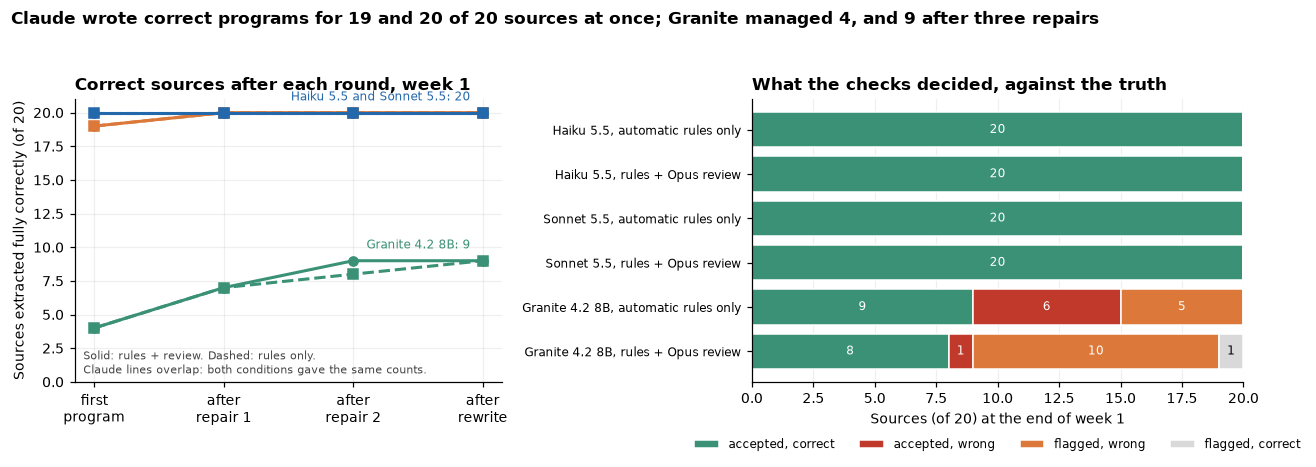

In [26]:
WRITER_COLOR = {'Claude Haiku 5.5': COLORS['orange'], 'Claude Sonnet 5.5': COLORS['blue'], 'Granite 4.2 8B': COLORS['green']}
STYLE = {(w, m): (c, '--' if m == 'static' else '-', 's' if m == 'static' else 'o')
         for w, c in WRITER_COLOR.items() for m in CHECK_MODES}
OUTCOMES = ['accepted, correct', 'accepted, wrong', 'flagged, wrong', 'flagged, correct']
OUTCOME_COLORS = [COLORS['green'], COLORS['red'], COLORS['orange'], COLORS['light']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={'width_ratios': [1, 1.15]})
for w in WRITERS:   # Claude's two conditions share the same numbers, so their lines lie on top of each other
    for m in CHECK_MODES:
        g = CURVE[(CURVE.writer == w) & (CURVE['mode'] == m)]
        c, ls, mk = STYLE[w, m]
        ax1.plot(g['round'], g['correct'], color=c, ls=ls, marker=mk, lw=2, label=cond_label(w, m))
ends = CURVE[CURVE['round'] == MAX_REPAIRS].groupby('writer')['correct'].max()
for value, group in ends.groupby(ends):   # one label per end point, so equal end points share a label
    who = ' and '.join(w.replace('Claude ', '') for w in group.index)
    ax1.annotate(f'{who}: {value}', (MAX_REPAIRS, value), xytext=(-8, 8), textcoords='offset points', ha='right',
                 color=WRITER_COLOR[group.index[-1]], fontsize=8)
ax1.set_xticks(range(MAX_REPAIRS + 1))
ax1.set_xticklabels(['first\nprogram', 'after\nrepair 1', 'after\nrepair 2', 'after\nrewrite'])
ax1.set_ylim(0, len(SOURCES) + 1)
ax1.set_ylabel(f'Sources extracted fully correctly (of {len(SOURCES)})')
ax1.set_title('Correct sources after each round, week 1')
ax1.text(0.02, 0.03, 'Solid: rules + review. Dashed: rules only.\nClaude lines overlap: both conditions gave the same counts.',
         transform=ax1.transAxes, fontsize=7.5, color='#444')
labels = [cond_label(w, m) for w, m in COND]
counts = b1.groupby(['writer', 'mode']).outcome.value_counts().unstack(fill_value=0).reindex(columns=OUTCOMES, fill_value=0)
left = np.zeros(len(COND))
for o, c in zip(OUTCOMES, OUTCOME_COLORS):
    vals = np.array([counts.loc[(w, m), o] for w, m in COND])
    ax2.barh(range(len(COND)), vals, left=left, color=c, label=o, edgecolor='white')
    for y, (v, l) in enumerate(zip(vals, left)):
        if v:
            ax2.text(l + v / 2, y, str(v), ha='center', va='center', fontsize=8, color='white' if c != COLORS['light'] else 'black')
    left += vals
ax2.set_yticks(range(len(COND)))
ax2.set_yticklabels(labels, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlabel(f'Sources (of {len(SOURCES)}) at the end of week 1')
ax2.set_title('What the checks decided, against the truth')
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=4, frameon=False, fontsize=8)
ax2.grid(axis='y', visible=False)
first = CURVE[CURVE['round'] == 0].groupby('writer')['correct'].first()
fig.suptitle(f'Claude wrote correct programs for {first["Claude Haiku 5.5"]} and {first["Claude Sonnet 5.5"]} of 20 sources at once; '
             f'Granite managed {first["Granite 4.2 8B"]}, and 9 after three repairs', x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIG / 'build_rounds.png')
plt.show()

**Both Claude writers produced working programs almost at once.** Sonnet 5.5's first program was fully correct for all 20 sources and Haiku 5.5's for 19; the one exception, Harrow & Finch Bank, is the worked example in section 4 and was fixed by one repair. That includes every trap in section 2: the day/month dates, the date that exists only on the listing, the text loaded from a second address, the author hidden in a meta tag, the events mixed in with news. Both condition rows for each Claude writer show the same counts because the first programs are shared and the rules alone never failed a correct Claude program. The review condition still called the writer twice more: once for Haiku's Harrow & Finch program (the same repair) and once for a Sonnet program the review rejected for a spacing detail (section 9).

**Granite 4.2 8B needed the loop and still fell short.** Its first programs were fully correct for 4 sources. Seven of the 20 crashed (four type errors, a syntax error, a missing-element error and a date-parsing error), four ran but returned no records, three returned records that failed the rules, and six passed the rules, of which two were still wrong. Three rounds of repair and rewriting raised the count to 9 correct sources in each condition. Field accuracy after the loop, 69% with rules only and 54% with the review, is lower than the count suggests because flagged sources often ended on a rewrite that returned nothing.

**The checks decided differently for Granite.** With rules only, 15 programs were accepted and 6 of them were wrong: bodies that stopped after the first paragraph (Port of Kestrel Bay), bodies without their subheadings and bullet lists (Accounting Standards Council), dates with day and month swapped (Ostara Exchange), dates filed under the wrong month heading (Pensions Oversight Authority), an author with half a job title attached ("Elian Corven, Head", Statistics Office) and no author at all where the page names one (Food Manufacturers Federation). With the review, 9 programs were accepted and 1 of them was wrong (Ostara again: one date in six was swapped, and the review passed it; section 9 looks at why); 10 wrong programs were flagged for a person, and 1 correct one was rejected. The review turned five of the six silent errors into flagged sources, for $1.36 in reviews that week.

In practice this means that the writer matters more than the checks for getting started: a Claude-class writer reaches a working program for nearly every source in one or two attempts, while a small open model leaves half the sources to a person even with a perfect review. With a weak writer, the review decides whether the remaining errors are visible or hidden.

## 6. Results: four weeks of reuse and six redesigns

The point of writing programs is that they keep running. From week 2 on, each condition starts the week with the program it ended the previous week with, runs it on the new snapshot and calls the writer only if a check fails. The table counts, per week, the sources whose delivered records were fully correct, the releases right out of those listed, the model calls made and their cost. The grid after it shows the same weeks source by source.

In [27]:
# Weeks 2 to 4: the stored programs run again; checks decide whether the model is called.
REDESIGNED = [sid for sid in SOURCES if SOURCES[sid]['redesign']]
def week_state(g):
    """One cell of the weekly grid: what the finance team received from this source this week."""
    last = g.sort_values('round').iloc[-1]
    repaired = len(g) > 1
    if last['correct']:
        return 'correct after repair' if repaired else 'correct, no model call'
    return 'wrong, flagged' if not last['accepted'] else 'wrong, not noticed'

STATES = ['correct, no model call', 'correct after repair', 'wrong, flagged', 'wrong, not noticed']
STATE_COLORS = [COLORS['green'], COLORS['blue'], COLORS['orange'], COLORS['red']]
GRID = (A.groupby(['writer', 'mode', 'source', 'run']).apply(week_state, include_groups=False)
        .rename('state').reset_index())

weekly = []
for (w, m, run), g in A.groupby(['writer', 'mode', 'run']):
    fin = g.sort_values('round').groupby('source').last()
    weekly.append({'writer': w, 'checks': MODE_LABEL[m], 'run': run, 'date': RUNS[run].isoformat(),
                   'sources correct': int(fin.correct.sum()),
                   'releases right': int(fin.records_right.sum()), 'releases listed': int(fin.n_truth.sum()),
                   'model calls': int((g['round'] > 0).sum() + (g['kind'] == 'generate').sum() + g['reviewed'].sum()),
                   'cost ($)': round(g.write_cost.sum() + g.review_cost.sum(), 2)})
WEEKLY = pd.DataFrame(weekly)
display(WEEKLY.pivot_table(index=['writer', 'checks'], columns='run', values=['sources correct', 'cost ($)']))

cost ($)                    \
run                                           1     2     3     4   
writer            checks                                            
Claude Haiku 5.5  automatic rules only     0.21  0.00  0.07  0.00   
                  rules + Opus review      1.39  1.25  1.40  1.27   
Claude Sonnet 5.5 automatic rules only     1.41  0.00  0.35  0.00   
                  rules + Opus review      2.75  1.25  1.76  1.27   
Granite 4.2 8B    automatic rules only     0.03  0.01  0.01  0.01   
                  rules + Opus review      1.40  1.27  1.04  1.16   

                                       sources correct                    
run                                                  1     2     3     4  
writer            checks                                                  
Claude Haiku 5.5  automatic rules only            20.0  20.0  20.0  20.0  
                  rules + Opus review             20.0  20.0  20.0  20.0  
Claude Sonnet 5.5 automatic rules only            20.0  20.0  20.0  20.0  
                  rules + Opus review             20.0  20.0  20.0  20.0  
Granite 4.2 8B    automatic rules only             9.0   9.0   9.0  10.0  
                  rules + Opus review              9.0  14.0  14.0  16.0

Each of the six panels is one writer in one condition; each row is a source (an asterisk marks the six redesigned sites) and each column a week. Green means the program delivered fully correct records without calling the writer that week; blue with R means a repair that week ended in correct records; orange with F means the loop gave up and flagged the source for a person; red with X means the delivered records were wrong and no check noticed. The dotted line falls just before week 3, when the redesigns happen.

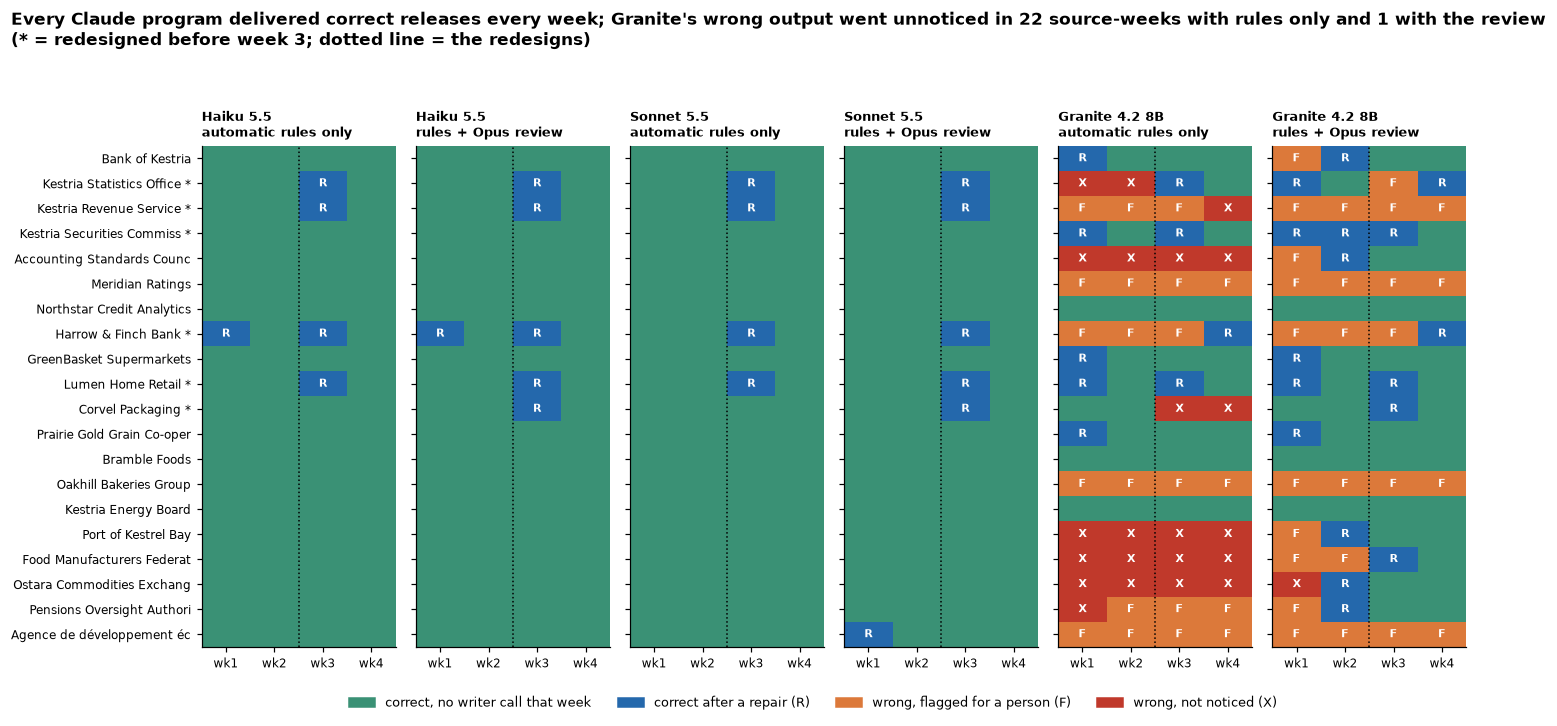

In [28]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
fig, axes = plt.subplots(1, len(COND), figsize=(13.5, 6.6), sharey=True)
order = list(SOURCES)
cmap = ListedColormap(STATE_COLORS)
MARK = {'correct after repair': 'R', 'wrong, flagged': 'F', 'wrong, not noticed': 'X'}
for ax, (w, m) in zip(axes, COND):
    g = GRID[(GRID.writer == w) & (GRID['mode'] == m)]
    mat = g.pivot(index='source', columns='run', values='state').reindex(order)
    ax.imshow(mat.map(STATES.index).values, cmap=cmap, vmin=-0.5, vmax=3.5, aspect='auto')
    ax.set_xticks(range(len(RUNS)))
    ax.set_xticklabels([f'wk{r}' for r in RUNS], fontsize=8)
    ax.set_title(cond_label(w, m).replace(', ', '\n'), fontsize=8.5)
    ax.grid(False)
    for y, sid in enumerate(order):
        for x, run in enumerate(RUNS):
            ax.text(x, y, MARK.get(mat.loc[sid, run], ''), ha='center', va='center', color='white', fontsize=7.5, fontweight='bold')
    ax.axvline(REDESIGN_RUN - 1.5, color='black', lw=1, ls=':')
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels([f'{SOURCES[sid]["stakeholder"][:26]}{" *" if SOURCES[sid]["redesign"] else ""}' for sid in order], fontsize=8)
fig.legend([Patch(color=c) for c in STATE_COLORS],
           ['correct, no writer call that week', 'correct after a repair (R)', 'wrong, flagged for a person (F)', 'wrong, not noticed (X)'],
           loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.55, 0.0), fontsize=8.5)
silent = GRID[GRID.state == 'wrong, not noticed'].groupby(['writer', 'mode']).size()
g_rules, g_review = (int(silent.get(('Granite 4.2 8B', m), 0)) for m in CHECK_MODES)
fig.suptitle(f'Every Claude program delivered correct releases every week; Granite\'s wrong output went unnoticed in {g_rules} '
             f'source-weeks with rules only and {g_review} with the review\n(* = redesigned before week 3; dotted line = the redesigns)',
             x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout(rect=(0, 0.05, 1, 0.94))
fig.savefig(FIG / 'weekly_grid.png')
plt.show()

**Week 2 and week 4 cost nothing for the Claude programs.** All 40 Claude programs ran unchanged on the new snapshots and returned every new release correctly. With rules only, those weeks made no model call at all; with the review, each week cost about $1.25 for 20 reviews that found nothing wrong.

**Four of the six redesigns broke every Claude program, and the rules caught every break.** The Statistics Office rename made Haiku's programs return no records and Sonnet's return records with no date or author. The Revenue Service's "Load more" button cut the records from 8 to 5, which the week-over-week count rule flagged ("Only 5 records this week against 8 last week"). The retired data service at Harrow & Finch returned "410 Gone", which Sonnet's programs raised as an error and Haiku's turned into an empty list. Lumen Home's new "Words by" byline gave Haiku's programs authors that still began with "Words by", which the byline rule caught, and gave Sonnet's programs no author at all, which the fill-rate rule caught ("author is filled for 0% of records this week against 100% last week"). One repair fixed each of the 16 breaks (four sources, two writers, two conditions).

**The two redesigns meant to cause silent errors broke no Claude program.** At the Securities Commission every Claude program still returned the first-publication date, so the new "Page reviewed" date above it changed nothing. At Corvel Packaging the newsletter box that moved inside the text area stayed out of every Claude program's body. One small piece did get in: the new inline paragraph "Related: ..." between two text paragraphs. The scoring tolerates it (one short line lowers each body's word overlap to between 0.965 and 0.971, above the 0.95 threshold), but the review flagged it in both Claude review conditions and the repair took it out. In this one case the review held the programs to the written definition more strictly than the scoring does.

**Granite's programs kept failing in both conditions, but only the review kept the failures visible.** With rules only, five or six sources a week delivered wrong records without any flag (22 source-weeks in all), and the count of correct sources moved only from 9 to 10 over the four weeks. With the review, the same wrong programs were flagged, and the loop tried again each week; by week 4, 16 of 20 sources were correct and 4 (Revenue Service, Meridian Ratings, Oakhill Bakeries and the Val-Brume agency) were still flagged for a person. Every week Granite cost under four cents in writing calls; the review condition's cost, $1.04 to $1.40 a week, was almost all review.

## 7. Results: what each check can catch

### The checks in the main run

Every program run in every week is one case for the checks. The table counts, for each check, how many wrong runs it caught, how many wrong runs it let through (silent errors) and how many correct runs it rejected (needless repairs). The rules judged all 690 runs. The review judged only the 239 runs that passed the rules in the review condition, so its row says what it added on top of them.

In [29]:
# How often did each check's verdict match the truth? Every program run in every week is one case.
def verdict_table(df, verdict_col, label):
    g = df.copy()
    tp = int((~g[verdict_col] & ~g['correct']).sum())   # rejected a wrong program
    fn = int((g[verdict_col] & ~g['correct']).sum())    # passed a wrong program: a silent error
    fp = int((~g[verdict_col] & g['correct']).sum())    # rejected a correct program: a needless repair
    tn = int((g[verdict_col] & g['correct']).sum())
    return {'check': label, 'program runs': len(g), 'wrong programs': tp + fn, 'wrong and caught': tp,
            'wrong but passed': fn, 'correct programs': fp + tn, 'correct but rejected': fp}

static_cases = A.copy()
review_cases = A[A.reviewed].copy()          # runs that passed the rules and then went to the reviewer
combined = A[A['mode'] == 'static+review'].copy()
combined['both_pass'] = combined['accepted']
CHECK_TABLE = pd.DataFrame([
    verdict_table(static_cases, 'static_pass', 'Automatic rules (all runs, both conditions)'),
    verdict_table(review_cases.assign(rv=review_cases['review_pass']), 'rv', 'Opus review (runs that passed the rules)'),
    verdict_table(combined, 'both_pass', 'Rules + review together (review condition)'),
])
display(CHECK_TABLE)

def wrong_fields(row):
    if row['correct']:
        return []
    out = []
    if row['found'] < row['n_truth']:
        out.append('missed releases')
    if row['extra']:
        out.append('extra items')
    for f in FIELDS:
        if row[f'{f}_right'] < row['found']:
            out.append(f)
    return out

A['wrong_fields'] = A.apply(wrong_fields, axis=1)

,check,program runs,wrong programs,wrong and caught,wrong but passed,correct programs,correct but rejected
0,"Automatic rules (all runs, both conditions)",690,272,232,40,418,0
1,Opus review (runs that passed the rules),239,18,17,1,221,9
2,Rules + review together (review condition),358,137,136,1,221,9


**The rules never rejected a correct program** in 418 correct runs, and they caught 232 of the 272 wrong ones. All 18 wrong Claude runs were among those caught. The 40 wrong runs that passed were all Granite's: errors inside a field that still looks plausible, such as a date that is a real date but the wrong one, or a body that is long enough and appears on the page but is incomplete.

**The review caught 17 of the 18 wrong runs that passed the rules and rejected 9 of the 221 correct ones.** All 9 rejections were about formatting rather than facts: six Granite bodies whose paragraphs were separated by a single line break instead of the blank line the field definition asks for, two Claude bodies with the inline "Related:" line from section 6, and one Sonnet body that wrote "40%" where the French page has "40 %". Seven of the nine were followed by a repaired program that was still correct and was accepted, so they cost one writing call and one more review each. Two cost more, both for Granite: at the Bank of Kestria the rejection pushed the loop into a rewrite that came out wrong, and at the Securities Commission it came in the last round, so a correct source was flagged for a person in week 1.

The main run cannot say how much the review adds for a writer as good as Haiku or Sonnet, because those writers left the review nothing to find. The test below supplies the errors.

### Planted errors

To measure each check on errors it has not been tuned on in this run, the true week-2 output of every source was changed in one of seven ways that broken programs typically go wrong, and both checks judged the result. Each change applies to every record of the source, as a bug in a program would. An eighth version leaves the output unchanged, as a control: any flag on it is a false alarm. The rules see the planted output as a second-week run, so their week-over-week comparisons are active; the review sees exactly what it sees in the main run.

In [30]:
# Planted errors: the true week-2 output of each source, changed in one way a broken program typically goes wrong,
# is given to both checks. This measures what each check can catch, which the main run could not, because
# every real error there was caught by the rules alone.
PLANT_RUN = 2

def plant(kind, sid, recs):
    """Return a changed copy of the true records, or None when the change does not apply to this source."""
    recs = [dict(r) for r in recs]
    if kind == 'none':
        return recs
    if kind == 'date_from_next_row':        # the listing parser pairs each title with the date of the row below
        dates = [r['date'] for r in recs]
        for k, r in enumerate(recs[:-1]):
            r['date'] = dates[k + 1]
        return recs if any(a != r['date'] for a, r in zip(dates, recs)) else None
    if kind == 'day_month_swapped':          # 05/10/2026 read month-first
        changed = False
        for r in recs:
            d = date.fromisoformat(r['date'])
            if d.day <= 12 and d.day != d.month:
                r['date'] = date(d.year, d.day, d.month).isoformat()
                changed = True
        return recs if changed else None
    if kind == 'first_paragraph_only':       # the rest of the text is loaded separately or hidden
        for r in recs:
            r['body'] = r['body'].split('\n\n')[0]
        return recs
    if kind == 'page_text_added':            # the program takes the whole page area: related links and footer too
        for r in recs:
            others = [t['title'] for t in recs if t['url'] != r['url']][:3]
            r['body'] += ('\n\nRelated news\n' + '\n'.join(others) +
                          f'\n\n© 2026 {SOURCES[sid]["stakeholder"]}. All rights reserved.\nPrivacy\nAccessibility\nContact')
        return recs
    if kind == 'author_dropped':             # the byline moved and the program finds no author
        if not any(r['author'] for r in recs):
            return None
        for r in recs:
            r['author'] = None
        return recs
    if kind == 'title_cut':                  # the program takes a shortened listing title, without an ellipsis
        for r in recs:
            r['title'] = ' '.join(r['title'].split()[:5])
        return recs
    if kind == 'oldest_missing':             # page 2 of the listing was never fetched
        return recs[:-3]
    raise ValueError(kind)

PLANT_KINDS = ['none', 'date_from_next_row', 'day_month_swapped', 'first_paragraph_only', 'page_text_added',
               'author_dropped', 'title_cut', 'oldest_missing']
PLANT_LABEL = {'none': 'no change (control)', 'date_from_next_row': 'date taken from the next row',
               'day_month_swapped': 'day and month swapped', 'first_paragraph_only': 'body: first paragraph only',
               'page_text_added': 'body: related links and footer added', 'author_dropped': 'author missing on every record',
               'title_cut': 'title cut to five words', 'oldest_missing': 'three oldest releases missing'}

def planted_case(job):
    kind, sid = job
    recs = plant(kind, sid, TRUTH[sid, PLANT_RUN])
    if recs is None:
        return None
    res = {'records': recs, 'error': None,
           'fetch_log': [[u, f['status']] for u, f in SNAP[sid, PLANT_RUN].files.items() if f['status'] == 200]}
    previous = run_summary({'records': TRUTH[sid, PLANT_RUN - 1]})
    static = static_checks(sid, PLANT_RUN, res, previous)
    rv = review(sid, PLANT_RUN, recs, known=previous['urls'])
    sc = score(sid, PLANT_RUN, recs)
    return {'kind': kind, 'source': sid, 'truly_wrong': not sc['correct'], 'rules_caught': bool(static),
            'review_caught': bool(rv['problems']), 'review_parsed': rv['parsed'], 'review_cost': rv['cost'],
            'rules_problem': static[0] if static else '', 'review_problem': rv['problems'][0] if rv['problems'] else ''}

with ThreadPoolExecutor(WORKERS) as pool:
    PLANTED = pd.DataFrame([r for r in pool.map(planted_case, [(k, sid) for k in PLANT_KINDS for sid in SOURCES]) if r])
PLANTED.to_csv(DATA / 'planted_errors.csv', index=False)
# Every planted change must make the output wrong by the scoring rules, and every control must be right.
assert PLANTED[PLANTED.kind != 'none'].truly_wrong.all(), PLANTED[(PLANTED.kind != 'none') & ~PLANTED.truly_wrong]
assert not PLANTED[PLANTED.kind == 'none'].truly_wrong.any()
print(f'{len(PLANTED)} planted cases ({(PLANTED.kind != "none").sum()} with an error, {(PLANTED.kind == "none").sum()} controls); '
      f'review cost ${PLANTED.review_cost.sum():.2f}')

155 planted cases (135 with an error, 20 controls); review cost $10.04


,cases,rules,review,either
date taken from the next row,20,0,20,20
day and month swapped,20,14,20,20
body: first paragraph only,20,1,20,20
body: related links and footer added,20,6,20,20
author missing on every record,15,15,15,15
title cut to five words,20,0,20,20
three oldest releases missing,20,12,20,20
no change (control),20,0,0,0


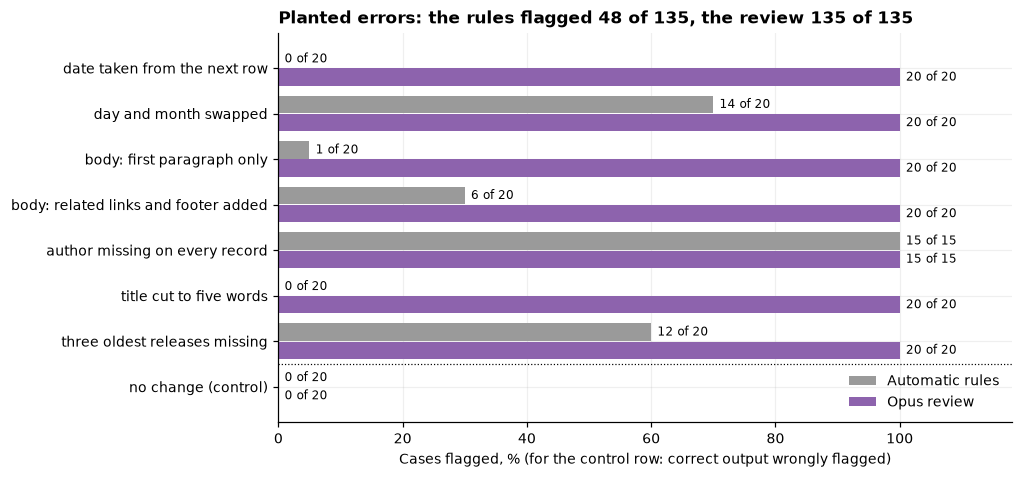

In [31]:
P = PLANTED.copy()
order = [k for k in PLANT_KINDS if k != 'none'] + ['none']
tab = (P.groupby('kind').agg(cases=('source', 'size'), rules=('rules_caught', 'sum'), review=('review_caught', 'sum'),
                             either=('rules_caught', lambda s: int((s | P.loc[s.index, 'review_caught']).sum())))
       .reindex(order))
tab.index = [PLANT_LABEL[k] for k in tab.index]
PLANT_TABLE = tab
display(tab)

fig, ax = plt.subplots(figsize=(8.6, 4.6))
y = np.arange(len(tab))
for off, col, color, label in ((-0.2, 'rules', COLORS['grey'], 'Automatic rules'), (0.2, 'review', COLORS['purple'], 'Opus review')):
    share = tab[col] / tab['cases'] * 100
    ax.barh(y + off, share, height=0.38, color=color, label=label)
    for yi, (k, n, s) in enumerate(zip(tab[col], tab['cases'], share)):
        ax.text(s + 1, yi + off, f'{k} of {n}', va='center', fontsize=8)
ax.set_yticks(y)
ax.set_yticklabels(tab.index)
ax.invert_yaxis()
ax.set_xlim(0, 118)
ax.set_xlabel('Cases flagged, % (for the control row: correct output wrongly flagged)')
ax.axhline(len(tab) - 1.5, color='black', lw=0.8, ls=':')
caught_rules = int(tab.loc[tab.index != PLANT_LABEL['none'], 'rules'].sum())
caught_review = int(tab.loc[tab.index != PLANT_LABEL['none'], 'review'].sum())
n_err = int(tab.loc[tab.index != PLANT_LABEL['none'], 'cases'].sum())
ax.set_title(f'Planted errors: the rules flagged {caught_rules} of {n_err}, the review {caught_review} of {n_err}')
ax.legend(loc='lower right', frameon=False)
fig.savefig(FIG / 'planted_errors.png')
plt.show()

Each pair of bars is one kind of planted error; grey is the share of cases the rules flagged, purple the share the review flagged, with the counts at the end of each bar. Below the dotted line is the control, where a bar would mean a false alarm. Some rows have 15 cases rather than 20 because five sources credit no author, so there is no author to drop.

**The review flagged every planted error, and neither check raised a false alarm.** The review's comments named the field and quoted the page, for example "Record gives 2026-09-28, but the page says 'Published on 5 October 2026'", "Body contains only the first of three paragraphs" and "Title is truncated to 'August goods imports rise faster'; the release page headline is 'August goods imports rise faster than export values'". A comment like that can go straight into the repair report.

**The rules flagged 48 of 135, and which ones follows from what each rule can see.** They caught every dropped author (15 of 15), because last week the field was always filled. They caught most swapped dates (14 of 20) by their effect on the order of the listing; in the six misses the swapped dates did not put more than a fifth of neighbouring pairs out of order, the rule's threshold. They caught 12 of 20 missing-release cases with the week-over-week comparisons; in the 8 misses, five records remained against six the week before, and at least three of them were last week's, so neither the count rule nor the overlap rule fired. They caught 6 of 20 added footers, only where the last 80 characters of the body happened to span text that never appears together on any page. And they caught almost none of the errors that leave a plausible value in place: a date from the neighbouring row (0 of 20), a title cut to five words (0 of 20), a body cut to its first paragraph (1 of 20, the one that fell under 200 characters).

The rules are therefore a good alarm for loud breakage (crashes, empty fields, missing records) and a weak one for quiet mistakes. Those quiet mistakes are exactly the ones Granite made in the main run, and the ones a good writer might make on a real site that holds a trap nobody planned for.

## 8. Comparison with reading every page

The simplest alternative to writing programs is to skip them: every week, give each new release page to a model and ask for the four fields. Here each of the three writer models does exactly that for all 240 releases, once each, in the week the release first appears. The model gets the release page and the listing page in their browser view (scripts removed, as a person would see them after the page has loaded), the same field definitions as the writers and the reviewer, and the release's address. It does not have to find new releases on the listing itself, so its accuracy here is an upper bound for this method.

Its result for a release is then reused in later weeks, which is fair: a release does not change once published. Both methods are scored on the same 593 release-weeks.

In [32]:
READ_PROMPT = """Below are a news listing page and one release page from the website of {stakeholder} ({kind}), as a browser shows them (scripts removed). Extract the release at {url}.

Fields:
{rules}{notes}

=== Listing page: {listing_url} ===
{listing_view}

=== Release page: {url} ===
{view}

Reply with JSON only: {{"title": "...", "date": "YYYY-MM-DD", "author": "..." or null, "body": "..."}}"""

def first_run(sid, url):
    return min(run for run in RUNS if any(t['url'] == url for t in TRUTH[sid, run]))

def read_release(job):
    """The comparison method: a model reads one release page (with its listing) the week it first appears."""
    reader, sid, url = job
    run, s = first_run(sid, url), SOURCES[sid]
    site = SNAP[sid, run]
    prompt = READ_PROMPT.format(stakeholder=s['stakeholder'], kind=s['kind'], url=url, rules=FIELD_RULES,
                                notes=f'\nNote: {s["notes"]}' if s['notes'] else '', listing_url=s['listing_url'],
                                listing_view=clip(site.views[s['listing_url']], 20000), view=clip(site.views[url], 20000))
    reply = model_call(reader, prompt, 'read', EFFORT['read'])
    try:
        rec = parse_json_reply(reply['text'])
        rec = rec if isinstance(rec, dict) else {}
    except Exception:
        rec = {}
    rec['url'] = url
    usage = reply.get('usage', {})
    return {'reader': reader, 'source': sid, 'url': url, 'run': run, 'record': rec,
            'cost': reply.get('list_cost_usd') or 0.0,
            'input_tokens': (usage.get('input_tokens', 0) + usage.get('cache_read_input_tokens', 0)
                             + usage.get('cache_creation_input_tokens', 0) + usage.get('prompt_tokens', 0)),
            'output_tokens': usage.get('output_tokens', usage.get('completion_tokens', 0))}

READ_JOBS = [(rd, sid, u) for rd in BASELINE_READERS for sid in SOURCES
             for u in dict.fromkeys(t['url'] for run in RUNS for t in TRUTH[sid, run])]
with ThreadPoolExecutor(WORKERS) as pool:
    READS = pd.DataFrame(list(pool.map(read_release, READ_JOBS)))
READS.to_json(DATA / 'direct_reads.jsonl', orient='records', lines=True, force_ascii=False)

def baseline_score(reader, sid, run):
    recs = {r['url']: r['record'] for _, r in READS[(READS.reader == reader) & (READS.source == sid)].iterrows()}
    return score(sid, run, [recs[t['url']] for t in TRUTH[sid, run]])

print(f'{len(READS)} direct reads by {len(BASELINE_READERS)} models, list price ${READS.cost.sum():.2f}')

720 direct reads by 3 models, list price $4.54


In [33]:
# The same models reading every release page directly, scored on the same releases, week by week.
rows = []
for rd in BASELINE_READERS:
    for run in RUNS:
        scs = [baseline_score(rd, sid, run) for sid in SOURCES]
        new = READS[(READS.reader == rd) & (READS.run == run)]
        rows.append({'method': f'{rd.replace("Claude ", "")} reads every page', 'run': run,
                     'sources correct': sum(s['correct'] for s in scs),
                     'releases right': sum(s['records_right'] for s in scs), 'releases listed': sum(s['n_truth'] for s in scs),
                     'model calls': len(new), 'cost ($)': round(new.cost.sum(), 2)})
for w, m in COND:
    for _, r in WEEKLY[(WEEKLY.writer == w) & (WEEKLY.checks == MODE_LABEL[m])].iterrows():
        rows.append({'method': cond_label(w, m), 'run': r['run'], 'sources correct': r['sources correct'],
                     'releases right': r['releases right'], 'releases listed': r['releases listed'],
                     'model calls': r['model calls'], 'cost ($)': r['cost ($)']})
COMPARE = pd.DataFrame(rows)
summary = COMPARE.groupby('method', sort=False).agg(**{
    'sources correct (sum of 4 weeks, of 80)': ('sources correct', 'sum'),
    'release-weeks right': ('releases right', 'sum'), 'release-weeks listed': ('releases listed', 'sum'),
    'model calls': ('model calls', 'sum'), 'cost ($)': ('cost ($)', 'sum')}).reset_index()
summary['share right'] = (summary['release-weeks right'] / summary['release-weeks listed']).map('{:.1%}'.format)
COMPARE_SUMMARY = summary
display(summary)

# Field errors of the direct reads, for the error analysis.
read_err = []
for _, r in READS.iterrows():
    t = next(t for t in TRUTH[r['source'], r['run']] if t['url'] == r['url'])
    read_err.append({'reader': r['reader'], 'source': r['source'], 'url': r['url'],
                     **{f: field_ok(f, r['record'].get(f), t[f]) for f in FIELDS},
                     'body_f1': token_f1(r['record'].get('body'), t['body'])})
READ_ERR = pd.DataFrame(read_err)
display(READ_ERR.groupby('reader')[FIELDS].mean().map('{:.1%}'.format))

,method,"sources correct (sum of 4 weeks, of 80)",release-weeks right,release-weeks listed,model calls,cost ($),share right
0,Haiku 5.5 reads every page,68,560,593,240,0.23,94.4%
1,Sonnet 5.5 reads every page,80,593,593,240,4.25,100.0%
2,Granite 4.2 8B reads every page,63,572,593,240,0.06,96.5%
3,"Haiku 5.5, automatic rules only",80,593,593,25,0.28,100.0%
4,"Haiku 5.5, rules + Opus review",80,593,593,107,5.31,100.0%
5,"Sonnet 5.5, automatic rules only",80,593,593,24,1.76,100.0%
6,"Sonnet 5.5, rules + Opus review",80,593,593,108,7.03,100.0%
7,"Granite 4.2 8B, automatic rules only",37,294,593,103,0.06,49.6%
8,"Granite 4.2 8B, rules + Opus review",53,404,593,202,4.87,68.1%


,title,date,author,body
reader,,,,
Claude Haiku 5.5,100.0%,99.2%,99.2%,95.8%
Claude Sonnet 5.5,100.0%,100.0%,100.0%,100.0%
Granite 4.2 8B,99.6%,98.8%,99.6%,97.5%


The first table sums the four weeks for each method: sources fully correct (out of 80 source-weeks), release-weeks right (out of 593), model calls and list-price cost. The second gives the share of releases with each field right when a model reads the page.

The figure puts the two views of cost next to each other. On the left, each line is the cumulative model cost of one method over the four weeks: dotted lines with triangles are direct reading, dashed lines with squares are programs with rules only, solid lines with circles are programs with the review. On the right, each bar is one method's share of release-weeks delivered correctly, with its four-week cost printed after the share; colours follow the model (orange Haiku, blue Sonnet, green Granite).

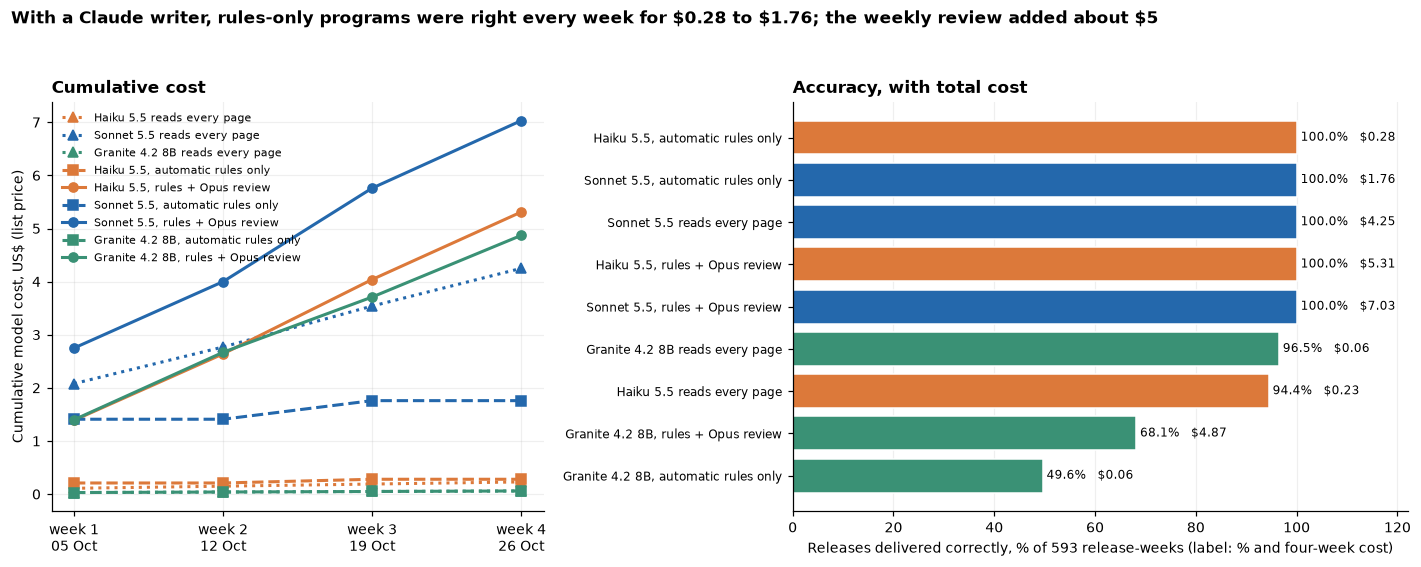

In [34]:
METHOD_STYLE = {cond_label(w, m): STYLE[w, m] for w, m in COND}
METHOD_STYLE.update({f'{rd.replace("Claude ", "")} reads every page': (WRITER_COLOR[rd], ':', '^') for rd in BASELINE_READERS})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1, 1.25]})
for method, g in COMPARE.groupby('method', sort=False):
    c, ls, mk = METHOD_STYLE[method]
    ax1.plot(g['run'], g['cost ($)'].cumsum(), color=c, ls=ls, marker=mk, lw=2, label=method)
ax1.set_xticks(list(RUNS))
ax1.set_xticklabels([f'week {r}\n{RUNS[r].strftime("%d %b")}' for r in RUNS])
ax1.set_ylabel('Cumulative model cost, US$ (list price)')
ax1.set_title('Cumulative cost')
ax1.legend(frameon=False, fontsize=7.5, loc='upper left')
s = COMPARE_SUMMARY.copy()
s['share'] = s['release-weeks right'] / s['release-weeks listed'] * 100
s = s.sort_values(['share', 'cost ($)'], ascending=[True, False])
ys = range(len(s))
ax2.barh(ys, s['share'], color=[METHOD_STYLE[m][0] for m in s['method']],
         hatch=None, edgecolor='white')
for y, (_, r) in zip(ys, s.iterrows()):
    ax2.text(r['share'] + 0.8, y, f'{r["share"]:.1f}%   ${r["cost ($)"]:.2f}', va='center', fontsize=8)
ax2.set_yticks(list(ys))
ax2.set_yticklabels(s['method'], fontsize=8)
ax2.set_xlim(0, 122)
ax2.set_xlabel(f'Releases delivered correctly, % of {int(s["release-weeks listed"].iloc[0])} release-weeks (label: % and four-week cost)')
ax2.set_title('Accuracy, with total cost')
ax2.grid(axis='y', visible=False)
fig.suptitle('With a Claude writer, rules-only programs were right every week for $0.28 to $1.76; the weekly review added about $5',
             x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIG / 'cost_vs_accuracy.png')
plt.show()

**With a Claude writer, programs with rules only gave the best accuracy for the least money.** Haiku's programs delivered all 593 release-weeks correctly for $0.28 of model calls over four weeks, and Sonnet's for $1.76; most of that is week 1, when the programs were written. Reading every page with Sonnet was also right every time, but cost $4.25, and that cost recurs every week in proportion to the number of new releases. Reading with Haiku cost $0.23 and got 94.4% of release-weeks right.

**Reading is cheap on these pages, which narrows the gap.** The two pages of a direct read come to about 2,000 tokens (Granite's count, which has no tool overhead; the Claude counts of 4,900 to 5,700 include about 3,000 tokens of the command-line tool's own instructions), and a read costs about $0.001 with Haiku and $0.018 with Sonnet. Real news pages are often 10 to 50 times larger, and their browser view would grow with them, while a program's running cost stays near zero. At these page sizes the economic case for programs is modest; on real pages it grows, and the measured figures here are the lower end.

**The review changes the cost picture more than the choice of method.** Reviewing 20 sources every week cost about $1.25 a week, so both Claude review conditions ended above direct reading with Sonnet. The review earned nothing for those writers in the main run (section 6). Run every week, it is the largest cost in the whole system; run only after a program is written or repaired, it would have cost about $1.20 in week 1 (one review per new program), a few reviews in week 3 and nothing in weeks 2 and 4.

**A small model was better at reading than at writing programs.** Granite 4.2 8B read pages directly with 96.5% of release-weeks right for $0.06, ahead of Haiku's direct reading and far ahead of its own programs (49.6% with rules only, 68.1% with the review). Writing a correct parser for an unseen page asks more of a small model than reading one page does. For a team limited to a small open model, direct reading with a review of a sample would be the better design on this evidence.

What these numbers cannot show is how either method scales: with 100 sources and a year of weekly runs, the programs' cost would depend on how often sites change, and the readers' cost on how many releases appear and how large the pages are. Neither was varied here.

## 9. Error analysis

The two tables below list every program run that was accepted while wrong (the silent errors), with the first wrong field next to the true value, and every run that was correct but sent back. The text after them walks through the cases that explain the patterns in sections 5 to 8, including two errors made by direct reading.

In [35]:
def first_wrong(row):
    """The first listed release this attempt got wrong, with the program's value next to the true one."""
    recs = {norm_url(r.get('url')): r for r in (ATTEMPTS.loc[row.name, 'records'] or []) if isinstance(r, dict)}
    for t in TRUTH[row['source'], row['run']]:
        r = recs.get(norm_url(t['url']))
        if r is None:
            return {'field': 'missing release', 'program': None, 'truth': t['title'], 'url': t['url']}
        for f in FIELDS:
            if not field_ok(f, r.get(f), t[f]):
                show = (lambda v: clip(str(v), 160)) if f == 'body' else (lambda v: v)
                return {'field': f, 'program': show(r.get(f)), 'truth': show(t[f]), 'url': t['url'],
                        'body_f1': round(token_f1(r.get('body'), t['body']), 3) if f == 'body' else None}
    return {'field': 'extra items', 'program': None, 'truth': None, 'url': None}

silent = A[A.accepted & ~A.correct]
SILENT = pd.DataFrame([{'writer': r['writer'], 'checks': MODE_LABEL[r['mode']], 'source': r['source'], 'week': r['run'],
                        'round': r['round'], 'wrong fields': ', '.join(r['wrong_fields']), **first_wrong(r)}
                       for _, r in silent.iterrows()])
print(f'{len(SILENT)} accepted program runs had at least one error the checks did not catch')
display(SILENT)

false_alarm = A[~A.accepted & A.correct]
FALSE_ALARMS = pd.DataFrame([{'writer': r['writer'], 'checks': MODE_LABEL[r['mode']], 'source': r['source'], 'week': r['run'],
                              'round': r['round'], 'problem raised': clip((r['static_problems'] + r['review_problems'])[0], 220)}
                             for _, r in false_alarm.iterrows()])
print(f'{len(FALSE_ALARMS)} program runs were fully correct but sent back')
display(FALSE_ALARMS)

23 accepted program runs had at least one error the checks did not catch


,writer,checks,source,week,round,wrong fields,field,program,truth,url,body_f1
0,Granite 4.2 8B,automatic rules only,kso,1,1,author,author,"Elian Corven, Head",Elian Corven,https://stats.kestria.example/en/releases/updated-business-returns-lift-second-quarter-growth-estimate/,NaN
1,Granite 4.2 8B,automatic rules only,kso,2,0,author,author,"Nessa Talvern, Head",Nessa Talvern,https://stats.kestria.example/en/releases/august-goods-imports-rise-faster-than-export-values/,NaN
2,Granite 4.2 8B,automatic rules only,krs,4,2,"missed releases, date, body",missing release,None,Revenue Service publishes results of employer account checks,https://www.revenue.kestria.example/newsroom/2026/1213-revenue-service-publishes-results-of-employer-account-checks,NaN
3,Granite 4.2 8B,automatic rules only,asc,1,3,body,body,"The Accounting Standards Council of Kestria approved amendments to Kestrian Accounting Standard 8, Revenue from Cust...","The Accounting Standards Council of Kestria approved amendments to Kestrian Accounting Standard 8, Revenue from Cust...",https://www.asck.example/news/council-approves-revenue-amendments-following-public-september-meeting.html,0.928
4,Granite 4.2 8B,automatic rules only,asc,2,0,body,body,The Accounting Standards Council of Kestria has published a report on its four autumn workshops. A total of 163 peop...,The Accounting Standards Council of Kestria has published a report on its four autumn workshops. A total of 163 peop...,https://www.asck.example/news/workshop-report-identifies-recurring-questions-from-accounts-preparers.html,0.921
5,Granite 4.2 8B,automatic rules only,asc,3,0,body,body,The Accounting Standards Council of Kestria has published French editions of the revenue amendments issued on 6 Octo...,The Accounting Standards Council of Kestria has published French editions of the revenue amendments issued on 6 Octo...,https://www.asck.example/news/french-editions-of-october-amendments-now-available-together.html,0.919
6,Granite 4.2 8B,automatic rules only,asc,4,0,body,body,The Accounting Standards Council of Kestria has published its operating update for the nine months ended 30 Septembe...,The Accounting Standards Council of Kestria has published its operating update for the nine months ended 30 Septembe...,https://www.asck.example/news/council-publishes-spending-update-and-revises-research-timetable.html,0.918
7,Granite 4.2 8B,automatic rules only,cvp,3,0,body,body,Corvel Packaging has added a tray material containing 35 per cent recycled plastic by weight to its Ostara product r...,Corvel Packaging has added a tray material containing 35 per cent recycled plastic by weight to its Ostara product r...,https://www.corvelpackaging.example/news/corvel-adds-recycled-content-option-for-selected-food/,0.914
8,Granite 4.2 8B,automatic rules only,cvp,4,0,body,body,Corvel Packaging has expanded its returnable pallet scheme to regular delivery routes serving Amberford and Val-Brum...,Corvel Packaging has expanded its returnable pallet scheme to regular delivery routes serving Amberford and Val-Brum...,https://www.corvelpackaging.example/news/corvel-expands-returnable-pallet-scheme-after-saltmarsh-customer/,0.909
9,Granite 4.2 8B,automatic rules only,pkb,1,0,body,body,"The Port of Kestrel Bay published a revised empty-container storage tariff today. Under the tariff now in force, the...","The Port of Kestrel Bay published a revised empty-container storage tariff today. Under the tariff now in force, the...",https://www.portofkestrelbay.example/news/port-publishes-revised-charges-for-empty-container-storage,0.608


9 program runs were fully correct but sent back


,writer,checks,source,week,round,problem raised
0,Claude Haiku 5.5,rules + Opus review,cvp,3,0,https://www.corvelpackaging.example/news/corvel-adds-recycled-content-option-for-selected-food/: body: Body includes...
1,Claude Sonnet 5.5,rules + Opus review,cvp,3,0,https://www.corvelpackaging.example/news/corvel-adds-recycled-content-option-for-selected-food/: body: Body includes...
2,Claude Sonnet 5.5,rules + Opus review,adv,1,0,https://www.devvalbrume.example/nouvelles/un-soutien-de-proximite-pour-les-commerces-de/: body: The body changes the...
3,Granite 4.2 8B,rules + Opus review,bok,1,2,https://www.bankofkestria.example/news-and-publications/press-releases/2026/09/settlement-system-completes-recovery-...
4,Granite 4.2 8B,rules + Opus review,ksc,1,3,https://www.ksc.example/media/news/2026-829: body: The paragraphs are separated by a single line break (\n) instead ...
5,Granite 4.2 8B,rules + Opus review,ksc,2,0,"https://www.ksc.example/media/news/2026-836: body: The three paragraphs are separated by a single line break (\n), n..."
6,Granite 4.2 8B,rules + Opus review,hfb,4,1,https://www.harrowfinch.example/about/newsroom/article/new-borrower-support-team-offers-earlier-repayment-difficulty...
7,Granite 4.2 8B,rules + Opus review,gbs,1,1,https://corporate.greenbasket.example/media/half-year-sales-rise-as-greenbasket-reports-lower: body: Paragraphs are ...
8,Granite 4.2 8B,rules + Opus review,pgc,1,1,https://www.prairiegold.example/newsroom/pr-20260928-27.html: body: The record separates paragraphs with a single ne...


**All 23 silent errors came from Granite programs, and 22 of them from the rules-only condition.** They are the same few mistakes carried from week to week, because an accepted program is reused unchanged: the Port of Kestrel Bay body (four weeks), the Food Manufacturers Federation author (four weeks), the Ostara dates (four weeks), the Accounting Standards bodies (four weeks), the Corvel bodies after the redesign (two weeks), the Statistics Office author (two weeks), plus one Pensions Oversight week and one Revenue Service week. A silent error in a stored program does not fade; it repeats every week until something else catches it.

**A quiet error the rules cannot see: half a release (Port of Kestrel Bay).** On this site only the first paragraph is in the page; the rest is loaded from a second address. Granite's first program read only the first paragraph, which gave bodies of one paragraph, 550 to 650 characters long, that appear word for word on the page, so every rule passed. Measured against the truth, the bodies had a word overlap of 0.48 to 0.61 with the full text. In the rules-only condition that program delivered half of every release for four weeks. In the review condition the reviewer wrote, in week 1, "The body has only the lead paragraph ... The two paragraphs in the page's body-rest section are missing", and in week 2 "Body contains only the lead paragraph (div.body-lead). The page continues in div.body-rest with two more paragraphs". Granite wrote seven programs over two weeks, including a rewrite that did not even compile, before a rewrite in week 2 fetched the second address and passed.

**The one error that passed the review: a single swapped date (Ostara Exchange, week 1).** Granite's first Ostara program read "04.09.2026" as 9 April: it parsed day-first dates month-first, and only one of the six releases that week had a day of 12 or less. The reviewer receives every record's date in its one-line summary and the listing page with every date, so it could have seen the mismatch, but it did not report it; its full checks covered the two sampled records, both with correct dates. In week 2 the newest release, dated 08.10.2026, was among the sampled records, and the reviewer wrote "Day and month are swapped. The page shows 'Date of issue: 08.10.2026', which is 2026-10-08, not 2026-08-10". One repair fixed it. The review reliably checks what it reads in full and only sometimes what it sees in the summary, so an error confined to unsampled records can wait a week or more. In the rules-only condition the same program went four weeks without a flag.

**The review can still use the summary when the error is visible there (Pensions Oversight, week 1).** Granite's repaired program put three releases under the wrong month. None of the three was a sampled record, but the reviewer compared the summary with the month headings on the listing and wrote "three records not shown in full have the wrong month. The listing places them under August 2026". So the review looks beyond its sample some of the time, which is not a guarantee.

**A loud error caught by a cheap rule (Lumen Home, week 3).** The redesign replaced the hidden author tag with a visible "Words by Daren Pell". Haiku's program returned "Words by Daren Pell"; the byline rule rejected it, and the repaired program strips such byline words before the name. Sonnet's program looked only at the old hidden tag and returned no author for every release; the fill-rate rule rejected that. Two different failures of the same redesign, each caught by a different free rule.

**A typical success (Pensions Oversight, Sonnet 5.5).** The release page has no date at all; the date exists only as a day number under a month heading on the listing. Sonnet's first program walked the listing in order, remembered the current month heading, combined it with each day, and returned all six dates correctly, then all eight in each later week without a single repair. Haiku's first program did the same. The trap that defeated Granite three times was routine for both Claude writers.

**Two direct-reading errors that a program avoids.** Reading every page is not error-free even for capable models, and its errors differ from release to release. Haiku 5.5 included Meridian Ratings' standard disclaimer ("Credit ratings are opinions about relative credit risk ...") in 10 of the agency's 14 bodies, a sentence that sits inside the article box but outside the text; and for 2 of the 13 Pensions Oversight releases it returned no date, although the listing in its prompt showed the month and day. A program makes the same choice for every release, so once it is right for one it is right for all, while a reader can get the same layout right on one page and wrong on the next.

**Needless rejections were about form, not facts.** The nine correct runs the review sent back all concerned the body's layout: paragraphs joined by one line break instead of a blank line (six Granite runs), the inline "Related:" line (two Claude runs) and "40%" against the page's "40 %" (one Sonnet run). The field definition does ask for blank lines between paragraphs, so most of these held the program to the letter of the specification. They cost a repair each and, for Granite, twice pushed the loop into a worse program.

These examples show what the programs and checks did, not why a model wrote a given line of code. The difference between the writers is measured; its cause, beyond the obvious difference in model size, is not.

## 10. What the evidence supports

- **Let a capable model write the programs, and reuse them.** On these 20 sites Claude Haiku 5.5 and Sonnet 5.5 produced correct programs for 39 of 40 sources at the first attempt and 40 of 40 after one repair. Running the stored programs cost nothing in model calls in a normal week. Haiku is enough: it matched Sonnet on every source-week for a sixth of the writing cost.
- **Run the free automatic rules on every run, and treat a failed rule as a repair trigger.** They caught every break caused by the redesigns and every wrong Claude program, with no false alarm in 418 correct runs. The week-over-week rules (record count, addresses seen again, fields that suddenly empty) did most of that work after the redesigns, so keep the previous week's summary for each source.
- **Use the model review where the rules are blind: new and repaired programs, and weak writers.** The rules flagged 48 of 135 planted errors and the review all 135. With Granite as writer the review cut silent source-weeks from 22 to 1. With Claude writers, reviewing unchanged programs every week found nothing and cost about $1.25 a week; reviewing only after a program is written or repaired keeps nearly all of the benefit seen here.
- **Do not use a small open model as the writer.** Granite 4.2 8B left half the sources to a person even after three repairs per week. The same model read pages directly with 96.5% of release-weeks right for six cents, so if only a small model is available, direct reading with a sampled review is the better design.

The uncertainty that most needs another experiment is how the rules and a sampled review do against errors nobody designed: real sites, at full size, with their own surprises, and errors that touch one release in eight rather than all of them.

## 11. Limitations

- **Made-up sites, smaller and tidier than real ones.** Each page is 3 to 8 KB of HTML with one main trap; real news pages are often 10 to 50 times larger, load several scripts, block automated visitors, set cookies, rate-limit requests and post some releases only as PDF files. None of that is tested here. The first-try and repair counts are best read as what the loop achieves when fetching the page is not the problem.
- **The traps and the checks have the same author.** The person who built the sites also wrote the field definitions (which warn against "last updated", "reviewed" and "effective" dates) and the automatic rules (one of which looks for dates out of listing order, a symptom of the day/month trap). Real sites will produce errors nobody anticipated. The Claude writers' near-perfect first attempts may owe something to a specification that named the traps.
- **One sample per writer and source.** Each first program and each repair was requested once. The same request again could give a different program; the counts have no repetition behind them, and with 20 sources a difference of one or two sources between conditions is within that noise. The Granite comparison between conditions (10 against 16 correct sources in week 4) rests on 20 sources and should be read as a direction, not a precise gap.
- **Systematic planted errors.** Every planted error changed every record of a source, so any sample of two showed it. The one silent error the review missed in the main run (section 9) touched one record in six, and the review missed it.
- **Four weeks and six chosen redesigns.** Real sites change on their own schedule and in ways no list covers; a longer run would also meet slow changes, such as a new type of item creeping onto a news page.
- **List prices, small pages.** Costs are the providers' list prices for these page sizes. The direct-reading comparison is given each release's address for free, so its accuracy is an upper bound for that method, and its cost would grow with the size of real pages.
- **One setting per model.** Each writer ran at one effort or temperature setting, Granite through one provider at BF16 precision.
- **No relevance step.** The finance team's next question, whether a release matters to them, is not part of this test.

## 12. Spend, data and how to run

The table below lists every model call the notebook used, by purpose and model, with list-price cost, tokens and the time the calls took. The per-condition costs in sections 5 to 8 count each call the condition made, so they say what each condition would cost on its own; where two conditions sent an identical request (the shared first programs, and reviews of identical output), the call was made once, so the actual spend below is lower than the sum of the conditions.

In [36]:
spend = defaultdict(lambda: {'calls': 0, 'usd': 0.0, 'input tokens': 0, 'output tokens': 0, 'minutes': 0.0})
used_rows = [(CLI_CACHE[k], CLI_CACHE[k]['request']['model']) for k in USED_KEYS] + \
            [(OR_CACHE[k], OR_CACHE[k]['request']['params']['model']) for k in OR_USED]
for row, model in used_rows:
    r, u = row['response'], row['response'].get('usage', {})
    k = (row['purpose'], model)
    spend[k]['calls'] += 1
    spend[k]['usd'] += r.get('list_cost_usd') or 0.0
    spend[k]['input tokens'] += (u.get('input_tokens', 0) + u.get('cache_read_input_tokens', 0)
                                 + u.get('cache_creation_input_tokens', 0) + u.get('prompt_tokens', 0))
    spend[k]['output tokens'] += u.get('output_tokens', u.get('completion_tokens', 0))
    spend[k]['minutes'] += r.get('latency_s', 0) / 60
SPEND = pd.DataFrame([{'purpose': p, 'model': m, **v} for (p, m), v in spend.items()]).sort_values(['purpose', 'model'])
SPEND['usd'] = SPEND['usd'].round(2)
SPEND['minutes'] = SPEND['minutes'].round(1)
display(SPEND)
unused = len(CLI_CACHE) - len(USED_KEYS) + len(OR_CACHE) - len(OR_USED)
print(f'{len(used_rows)} model replies used, list price ${SPEND.usd.sum():.2f} (GPT-6.1 Sol runs on a subscription and '
      f'reports no price); {unused} cached replies not used by this run; new calls this session: '
      f'{cli_new["calls"]} claude/codex, {or_new["calls"]} OpenRouter')
print(f'{len(RUN_CACHE)} program runs cached; programs re-executed this session: {RERUN}; mismatches: {len(rerun_mismatches)}')

,purpose,model,calls,usd,input tokens,output tokens,minutes
0,content,gpt-6.1-sol,20,0.00,244661,72056,39.6
5,generate,claude-haiku-5-5,20,0.19,122874,354009,28.5
4,generate,claude-sonnet-5-5,20,1.41,106384,108821,16.8
10,generate,ibm-granite/granite-4.2-8b,20,0.01,46467,35945,15.4
1,read,claude-haiku-5-5,240,0.22,1375156,93691,45.3
3,read,claude-sonnet-5-5,240,4.26,1177471,89200,46.0
8,read,ibm-granite/granite-4.2-8b,240,0.06,485370,111152,102.4
11,regenerate,ibm-granite/granite-4.2-8b,30,0.02,71265,54646,18.2
7,repair,claude-haiku-5-5,6,0.08,63577,149390,10.8
6,repair,claude-sonnet-5-5,6,0.53,60586,32153,3.9


1166 model replies used, list price $22.16 (GPT-6.1 Sol runs on a subscription and reports no price); 0 cached replies not used by this run; new calls this session: 0 claude/codex, 0 OpenRouter
406 program runs cached; programs re-executed this session: False; mismatches: 0


The whole study used 1,166 model replies at a list price of $22.16, of which $15.33 was Opus reviews (239 distinct review requests across the main run and the planted-error test). GPT-6.1 Sol wrote the release texts through a subscription that reports no price. No collected reply was left unused; three replies to identical requests that had been sent at the same moment were dropped before the final run, so each request has exactly one reply. The generated programs ran in 0.8 seconds each on median, without Python start-up.

| File or folder in `data/` | What it holds |
|---|---|
| `sources.csv` | The source registry: organisation, kind, finance team, listing address, notes |
| `releases.json` | The release texts as GPT-6.1 Sol wrote them |
| `sites/`, `views/` | Every page of every site for each run date, raw and as a browser shows it; `site_manifest.json` pins their hashes |
| `ground_truth.csv` | The right answer for every listed release in every week |
| `attempts.jsonl` | Every program run: writer, condition, week, round, code, check results, report and score |
| `programs/` | Every program written, one file each, by writer and condition |
| `direct_reads.jsonl` | Every direct read and its record |
| `planted_errors.csv` | The planted-error cases and both checks' verdicts |
| `cache_cli.jsonl`, `cache_openrouter.jsonl` | Every model reply, keyed by the full request |
| `program_runs.jsonl` | Every program run's output, keyed by the program, the snapshot and the runner |
| `model_catalog.json` | Granite 4.2 8B's pinned version, provider, precision, licence and prices |

Running the notebook replays everything from these files with no model calls and no program execution:

```bash
jupyter nbconvert --to notebook --execute --inplace 31_self_repairing_scrapers.ipynb
```

`NB_RERUN_PROGRAMS=1` runs every generated program again in its sandbox and reports any output that differs from the saved run. New collection needs `NB_LIVE=1`, signed-in `claude` and `codex` command-line tools and an `OPENROUTER_API_KEY`; the size settings and budget caps sit at the top of the notebook. `NB_REBUILD_SITES=1` accepts a deliberate change to the site generator, which also invalidates the cached replies that were collected on the old pages.

## 13. Future work and further reading

### Future work

- **Real pages, in full size.** Repeat the build on saved copies of 20 real news pages, typically 30 to 150 KB of HTML each, against 3 to 8 KB here. Measure the same first-try and after-repair counts, and the direct-reading cost per release, which grows with page size while the program's running cost does not. Motivated by the comparison in section 8, where direct reading with Haiku cost about $0.001 per release only because the pages are small.
- **Errors that affect only some records.** Plant errors in one record in eight (one release with a "last updated" date, one with a missing paragraph) and measure how often a two-record review sample sees them, against reviewing all records. The planted errors in section 7 changed every record, so any sample showed them.
- **Review on a schedule rather than every week.** Compare three review policies over a longer run with more redesigns: every week, only after a program is written or repaired, and a rotating 20% of sources each week. Measure the delay before a silent error is noticed against review cost. Motivated by the review condition costing about $1.25 a week while finding no real error in weeks 2 and 4.
- **A wider range of writers.** Granite 4.2 8B needed many more repairs than the two Claude models (section 5); a medium open-weight model such as Qwen3.8 27B would show where on the size scale a writer stops needing the loop.
- **A specification written without knowledge of the traps.** The field definitions here mention "last updated", "reviewed" and "effective" dates because the person who built the sites knew those traps exist. Have a second person write the specification from the registry alone and compare first-try results.

### Further reading

Links checked on 2026-10-29.

- [Wrapper Maintenance: A Machine Learning Approach](https://arxiv.org/abs/1106.4872) (Lerman, Minton and Knoblock, 2003). Monitored 27 hand-built extraction programs ("wrappers") for a year and detected 35 of 37 site changes from learned patterns of the extracted data; the run-over-run rules here are a simple version of that verification step.
- [Language Models Enable Simple Systems for Generating Structured Views of Heterogeneous Data Lakes](https://arxiv.org/abs/2304.09433) (Arora et al., 2023). Compares having a model extract values from every document with having it write extraction code, and reports a 110-fold reduction in tokens processed for the code approach, the same trade-off measured in section 8.
- [Teaching Large Language Models to Self-Debug](https://arxiv.org/abs/2304.05128) (Chen et al., 2023). Shows that models fix more of their own code when given execution results; the repair report here (error, requests, failed checks) is that kind of feedback.
- [AutoScraper: A Progressive Understanding Web Agent for Web Scraper Generation](https://arxiv.org/abs/2404.12753) (Huang et al., 2024). Has a model write scrapers by reading the page structure step by step, and measures whether the scrapers run; a more elaborate writer than the single prompt used here.
- [Trafilatura: A Web Scraping Library and Command-Line Tool for Text Discovery and Extraction](https://aclanthology.org/2021.acl-demo.15/) (Barbaresi, 2021). A widely used non-model tool for separating the main text of a page from navigation and other boilerplate, the body problem in this notebook.
- [NewsArticle](https://schema.org/NewsArticle) (schema.org). The shared vocabulary behind the JSON-LD and microdata on two of the sites, with `datePublished` and `dateModified` as separate properties.